# Lab 2 - Analysis: comparing learned features and hand-crafted descriptors

This notebook turns the stored results of the whole project into the comparisons and answers needed for the report. It **trains nothing**: it reads the predictions and result tables written by `task_1`, `task_2`, `lab1_retraining` and `multiseed_retraining`, so running it takes a couple of minutes and gives the same numbers every time.

**Three approaches are compared**

| Approach | Models | Where they come from |
|---|---|---|
| Hand-crafted descriptors (Lab 1) | Random Forest, Extra Trees on 58 audio descriptors | `lab1_retraining` |
| CNN trained from scratch | 4-block CNN on mel-spectrogram images | `task_1`, `multiseed_retraining` |
| Pretrained models | VGG16 / ResNet50 / EfficientNetB0 fine-tuned (ImageNet), frozen VGG16 and VGGish embeddings + classical classifiers | `task_2`, `multiseed_retraining` |

**How the notebook is organised**

| Part | Sections | Content |
|---|---|---|
| **I. Approach by approach** | 3 – 6 | Error analysis of each approach (confusion matrix, confidence and calibration, error types, genres, individual songs) and a side-by-side comparison of how they fail |
| **II. Comparing the approaches** | 7 – 11 | **Q1** learned vs hand-crafted · **Q5** variability and statistical tests · **Q2** same mistakes? · **Q3** complementarity (ensembles) · **Q4** cost |
| **III. Designing the CNN** | 12 – 14 | **Q6** data size |
| **IV. Pretrained models** | 15 – 16 | **Q9** fine-tuning, vision vs audio · **Q10** frozen embeddings vs fine-tuning |
| **Appendix and report aids** | 17 – 18 | Complete results of every trained model · key numbers and a checklist for writing |

**Evaluation protocol.** Every model is tested on the **same songs**: five stratified 80/20 partitions by song (seeds 42–46, 200 test songs each), with seed 42 as the main partition shared by all notebooks. One test song is worth 0.5 pp, and the standard error of an accuracy near 0.8 is about 2.8 pp, so models are compared with paired statistical tests (exact McNemar on the main partition, corrected resampled t-test over the five partitions) and not by raw accuracy differences.

**Where the outputs go.** Figures are saved in `results_lab2/figures/`, per-model error analyses in `results_lab2/error_analysis/<model>/` and summary tables as `results_lab2/table_*.csv`.

## 1. Setup
Runs on Google Colab (Drive) or locally from the folder that contains `results_lab2/`, `results_task1/` and `results_task2/`.

**Conventions used below**
- *Multi-partition models* (`MULTI`) have predictions for all five partitions; they are the basis of the variability analysis.
- *Main partition* = seed 42, the partition shared by Task 1, Task 2 and Lab 1. Models that exist only there (the Task 2 search, VGGish) are compared on it with McNemar.
- Colours identify the approach: green = descriptors, blue = CNN from scratch, orange = pretrained vision, purple = pretrained audio.

In [1]:
import os, json, itertools, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

# ---- Paths ----
try:                                                         # Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/MSC/music-genre-classification-2")
except ImportError:                                          # local run: folder that contains results_lab2/
    PROJECT = Path(".")
OUT, T1, T2 = PROJECT / "results_lab2", PROJECT / "results_task1", PROJECT / "results_task2"
assert OUT.exists(), f"results_lab2 not found in {PROJECT.resolve()}"
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)

# ---- Parameters ----
PRIMARY    = 42      # main partition (shared by Task 1 / Task 2 / Lab 1)
TIE_MARGIN = 0.10    # "near-tie" error: top-1 minus top-2 probability below this (e.g. 0.51 vs 0.49)
CONFIDENT  = 0.90    # "confident error": wrong with top-1 probability >= this

GENRES = sorted({s.split(".")[0] for s in json.load(open(OUT / "songs.json"))})
PCOLS  = [f"p_{i}" for i in range(len(GENRES))]

# ---- Style ----
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10})
FAM_COLORS = {"Hand-crafted descriptors": "#2e9e5b", "CNN from scratch": "#2b6cb0",
              "Pretrained vision": "#ed8936", "Pretrained audio": "#805ad5"}

def savefig(name, fig=None):
    (fig or plt.gcf()).savefig(FIG / name, dpi=200, bbox_inches="tight")

KEY = {}     # key numbers collected along the notebook (summarised in Section 18)
print("Project:", PROJECT.resolve(), "|", len(GENRES), "genres")

Mounted at /content/drive
Project: /content/drive/MyDrive/MSC/music-genre-classification-2 | 10 genres


## 2. Load predictions and check that all models share the same test songs

Every stored prediction file has the common format `song, y_true, y_pred, p_0..p_9` (`preds/<model>__seed<S>.csv`). Rows are sorted by song so that models can be compared song by song.

**Critical check:** for each partition, all models must be evaluated on exactly the same songs and labels. The notebook stops if this is not true. The pretrained-model search of Task 2 and the CNN run of Task 1 (main partition only) are loaded from their own folders and checked against the same test songs.

In [3]:
# ---------------- model names and families ----------------
T2_LABELS = {"vgg16_head": "VGG16 · head only", "vgg16_block5": "VGG16 · last block", "vgg16_block45": "VGG16 · last 2 blocks",
             "vgg16_full": "VGG16 · full", "resnet50_head": "ResNet50 · head only", "resnet50_conv5": "ResNet50 · last block",
             "resnet50_conv45": "ResNet50 · last 2 blocks", "resnet50_full": "ResNet50 · full",
             "effnetb0_head": "EfficientNetB0 · head only", "effnetb0_last": "EfficientNetB0 · last block",
             "effnetb0_last2": "EfficientNetB0 · last 2 blocks", "effnetb0_full": "EfficientNetB0 · full",
             "vgg16_block45_aug": "VGG16 · last 2 blocks + SpecAugment", "vgg16emb_logreg": "VGG16 frozen + LogReg",
             "vgg16emb_svm": "VGG16 frozen + SVM", "vgg16emb_rf": "VGG16 frozen + RF",
             "vggish_logreg": "VGGish frozen + LogReg", "vggish_svm": "VGGish frozen + SVM", "vggish_rf": "VGGish frozen + RF"}
NICE = {"lab1_random_forest_correlation": "Lab 1 · Random Forest (+corr.)",
        "lab1_random_forest_without_selection": "Lab 1 · Random Forest",
        "lab1_extra_trees_correlation": "Lab 1 · Extra Trees (+corr.)",
        "cnn_scratch": "CNN from scratch", "t1_cnn_scratch": "CNN from scratch (Task 1 run)",
        "vgg16_ft": "VGG16 fine-tuned", "vgg16_emb_logreg": "VGG16 frozen + LogReg"}
def nice(m):
    if m in NICE: return NICE[m]
    if m.startswith("t2_"): return T2_LABELS.get(m[3:], m[3:]) + " (T2)"
    return m.replace("lab1_", "Lab 1 · ").replace("_", " ")
def family(m):
    k = m[3:] if m.startswith("t2_") else m
    if k.startswith("lab1_"): return "Hand-crafted descriptors"
    if "cnn" in k: return "CNN from scratch"
    if "vggish" in k: return "Pretrained audio"
    return "Pretrained vision"
color = lambda m: FAM_COLORS[family(m)]

# ---------------- partitions: preds/<model>__seed<S>.csv ----------------
P = {}                                                       # P[model][seed] = DataFrame sorted by song
for f in sorted((OUT / "preds").glob("*__seed*.csv")):
    model, seed = f.stem.split("__seed")
    if model.startswith("t2_"): continue                     # Task 2 models are loaded from results_task2 (Section 2, below)
    P.setdefault(model, {})[int(seed)] = pd.read_csv(f).sort_values("song").reset_index(drop=True)

for seed in sorted({s for m in P.values() for s in m}):      # same songs and labels for every model of a seed
    ref = None
    for m in P:
        if seed in P[m]:
            key = (tuple(P[m][seed].song), tuple(P[m][seed].y_true)); ref = ref or key
            assert key == ref, f"{m} (seed {seed}) is not evaluated on the same test songs as the other models!"

correct = lambda m, s: (P[m][s].y_true == P[m][s].y_pred).to_numpy()
proba   = lambda m, s: P[m][s][PCOLS].to_numpy()
ytrue   = lambda s: next(P[m][s].y_true.to_numpy() for m in P if s in P[m])

MULTI = [m for m in P if len(P[m]) >= 3]
SEEDS_ALL = sorted(set.intersection(*[set(P[m]) for m in MULTI]))      # partitions available for ALL multi-partition models
MULTI = [m for m in MULTI if set(SEEDS_ALL) <= set(P[m])]
SINGLE = [m for m in P if m not in MULTI]
inv = pd.DataFrame({nice(m): {f"seed {s}": (s in P[m]) for s in sorted({s for mm in P.values() for s in mm})} for m in P}).T
display(inv.replace({True: "Yes", False: "–"}))
print(f"multi-partition models: {len(MULTI)} | common partitions: {SEEDS_ALL} | single-partition models: {SINGLE}")

,seed 42,seed 43,seed 44,seed 45,seed 46
CNN from scratch,Yes,Yes,Yes,Yes,Yes
Lab 1 · Extra Trees (+corr.),Yes,Yes,Yes,Yes,Yes
Lab 1 · Random Forest (+corr.),Yes,Yes,Yes,Yes,Yes
Lab 1 · Random Forest,Yes,Yes,Yes,Yes,Yes
VGG16 frozen + LogReg,Yes,Yes,Yes,Yes,Yes
VGG16 fine-tuned,Yes,Yes,Yes,Yes,Yes


multi-partition models: 6 | common partitions: [42, 43, 44, 45, 46] | single-partition models: []


In [4]:
# ---------------- main partition (seed 42) for ALL models, including Task 1 and Task 2 ----------------
P42 = {m: P[m][PRIMARY] for m in P if PRIMARY in P[m]}
REF_SONGS, REF_Y = P42[MULTI[0]].song.tolist(), P42[MULTI[0]].y_true.to_numpy()

def as_frame(songs, y_true, probs):
    df = pd.DataFrame(probs, columns=PCOLS); df.insert(0, "y_pred", probs.argmax(1)); df.insert(0, "y_true", y_true); df.insert(0, "song", songs)
    return df.sort_values("song").reset_index(drop=True)

# Task 1 notebook run of the CNN (seed 42)
if (T1 / "task1_test_probs.npy").exists():
    t1 = pd.read_csv(T1 / "task1_test_predictions.csv")
    P42["t1_cnn_scratch"] = as_frame(t1.song.to_numpy(), t1.y_true.to_numpy(), np.load(T1 / "task1_test_probs.npy"))

# Task 2: pretrained models (search on the main partition) and frozen embeddings + classical classifiers
T2_RUNS = pd.read_csv(T2 / "runs.csv").set_index("model") if (T2 / "runs.csv").exists() else pd.DataFrame()
if len(T2_RUNS):
    s2  = json.load(open(PROJECT / "split_seed42.json"))
    ids = np.array([f"{Path(p).parent.name}.{Path(p).stem[len(Path(p).parent.name):]}" for p in s2["test"]])   # same order as probs_*.npy
    y2  = np.load(T2 / "test_labels.npy")
    assert (np.array([GENRES.index(i.split(".")[0]) for i in ids]) == y2).all()
    for key in T2_RUNS.index:
        f = T2 / f"probs_{key}.npy"
        if f.exists():
            probs = np.load(f); assert probs.shape == (len(ids), len(GENRES))
            assert abs((probs.argmax(1) == y2).mean() - T2_RUNS.loc[key, "test_acc"]) < 1e-6, key       # consistent with runs.csv
            P42[f"t2_{key}"] = as_frame(ids, y2, probs)

for m, df in P42.items():                                    # all models: same songs and labels
    assert df.song.tolist() == REF_SONGS and (df.y_true.to_numpy() == REF_Y).all(), f"{m}: different test songs"
correct42 = lambda m: (P42[m].y_true == P42[m].y_pred).to_numpy()
print(f"{len(P42)} models evaluated on the same {len(REF_SONGS)} test songs of the main partition")

26 models evaluated on the same 200 test songs of the main partition


# Part I — Approach by approach

Before comparing the approaches, each one is examined on its own with the same toolbox. For a model, the predictions of **all five partitions** are pooled (5 × 200 = 1000 predictions; a song can appear in the test set of several partitions) and the analysis asks:

1. **Confusion matrix** — which genres are recognised and which are mixed up (counts and row-normalised), with per-genre precision, recall, F1 and top-2 recall.
2. **Confidence and calibration** — how sure is the model when it is right and when it is wrong? Does a reported probability of 0.8 mean 80 % accuracy?
3. **Top-1 vs top-2 probability** — separates genuine indecision (0.51 / 0.49) from clear mistakes.
4. **Error types** — *confident errors*, *near-ties*, *runner-up misses* and errors "from afar" (the correct genre was ranked third or worse).
5. **Genres and genre pairs** — which confusions occur and with what margin.
6. **Individual songs** — the tightest calls, the most confident errors and the songs that fail on every partition.

> **Reading the probabilities.** In the Random Forest the "probability" is the fraction of trees voting for a class; in the neural networks it is a softmax output, which tends to be more extreme. Thresholds such as `TIE_MARGIN` and `CONFIDENT` should therefore be interpreted **within** a model, not across models (Section 6 compares calibration explicitly).

In [5]:
def error_report(model, label=None, seeds=None, tie=TIE_MARGIN, conf=CONFIDENT):
    '''Full error analysis of one model, pooling its test predictions over the partitions (see Part I).'''
    label = label or nice(model)
    AN = OUT / "error_analysis" / model; AN.mkdir(parents=True, exist_ok=True)
    seeds = seeds or sorted(P[model])
    D = pd.concat([P[model][s].assign(seed=s) for s in seeds], ignore_index=True)
    Pm = D[PCOLS].to_numpy(); ar = np.arange(len(D)); yt = D.y_true.to_numpy(); yp = D.y_pred.to_numpy()
    order = np.argsort(-Pm, axis=1, kind="stable")                        # classes from most to least probable
    D["top1"], D["top2"] = order[:, 0], order[:, 1]
    D["p1"], D["p2"] = Pm[ar, order[:, 0]], Pm[ar, order[:, 1]]           # probability of the 1st and 2nd class
    D["margin"] = D.p1 - D.p2
    D["p_true"], D["p_pred"] = Pm[ar, yt], Pm[ar, yp]
    D["rank_true"] = (Pm > D.p_true.to_numpy()[:, None]).sum(1) + 1       # 1 = correct; 2 = the true class was 2nd most probable...
    D["correct"] = D.y_true == D.y_pred
    D["true_name"], D["pred_name"], D["second_name"] = D.y_true.map(GENRES.__getitem__), D.y_pred.map(GENRES.__getitem__), D.top2.map(GENRES.__getitem__)
    N, ERR = len(D), D[~D.correct].copy(); labels = range(len(GENRES)); out = dict(model=model, label=label, D=D, N=N)

    # ---------------- 1. Confusion matrix ----------------
    display(Markdown(f"### {label} — 1. Confusion matrix (all {len(seeds)} partitions pooled)"))
    C = confusion_matrix(D.y_true, D.y_pred, labels=labels); R = C / C.sum(1, keepdims=True)
    fig, axs = plt.subplots(1, 2, figsize=(17, 7))
    sns.heatmap(C, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=GENRES, yticklabels=GENRES, ax=axs[0]); axs[0].set_title(f"{label}: counts")
    sns.heatmap(R, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=GENRES, yticklabels=GENRES, ax=axs[1]); axs[1].set_title("row-normalised (fraction of the true genre)")
    for ax in axs: ax.set_xlabel("predicted"); ax.set_ylabel("true")
    plt.tight_layout(); plt.savefig(AN / "01_confusion_counts_and_normalised.png", dpi=200, bbox_inches="tight"); plt.show()
    tp = np.diag(C); prec = tp / C.sum(0).clip(1); rec = tp / C.sum(1); f1 = 2 * prec * rec / (prec + rec).clip(1e-9)
    top2 = D.groupby("y_true").apply(lambda d: (d.rank_true <= 2).mean()).reindex(labels).to_numpy()
    per_class = pd.DataFrame(dict(genre=GENRES, support=C.sum(1), precision=prec, recall=rec, f1=f1, top2_recall=top2)).set_index("genre")
    per_class.loc["ALL (macro)"] = [N, prec.mean(), rec.mean(), f1.mean(), (D.rank_true <= 2).mean()]
    per_class.round(3).to_csv(AN / "table_per_class.csv"); display(per_class.round(3))
    out.update(C=C, R=R, per_class=per_class)

    # ---------------- 2. Confidence and calibration ----------------
    display(Markdown(f"### {label} — 2. How sure is it when it is right and when it is wrong?"))
    bins = np.linspace(0, 1, 11); fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.4)); ax = axs[0]
    ax.hist(D[D.correct].p1, bins=bins, alpha=.65, label=f"correct (n={int(D.correct.sum())})", color="tab:blue")
    ax.hist(ERR.p1, bins=bins, alpha=.75, label=f"errors (n={len(ERR)})", color="tab:red")
    ax.set_xlabel("top-1 probability"); ax.set_ylabel("number of predictions"); ax.legend(); ax.grid(alpha=.3); ax.set_title("Confidence of correct vs wrong predictions")
    b = np.clip(np.digitize(D.p1, bins) - 1, 0, len(bins) - 2); rel = []
    for k in range(len(bins) - 1):
        m = b == k
        if m.sum(): rel.append((D.p1[m].mean(), D.correct[m].mean(), int(m.sum())))
    rel = pd.DataFrame(rel, columns=["conf", "acc", "n"]); ece = (rel.n / N * (rel.acc - rel.conf).abs()).sum()
    ax = axs[1]; ax.plot([0, 1], [0, 1], "k--", label="perfect calibration"); ax.plot(rel.conf, rel.acc, "o-", color="tab:blue", label=f"{label} (ECE = {ece:.3f})")
    for _, r in rel.iterrows(): ax.annotate(int(r.n), (r.conf, r.acc), textcoords="offset points", xytext=(4, -11), fontsize=8)
    ax.set_xlabel("mean top-1 probability in the bin"); ax.set_ylabel("accuracy in the bin"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02)
    ax.grid(alpha=.3); ax.legend(loc="upper left"); ax.set_title("Reliability diagram (numbers = predictions per bin)")
    plt.tight_layout(); plt.savefig(AN / "02_confidence_and_calibration.png", dpi=200, bbox_inches="tight"); plt.show()
    auroc = roc_auc_score(D.correct, D.p1)
    print(f"mean confidence  correct: {D[D.correct].p1.mean():.3f} | errors: {ERR.p1.mean():.3f}")
    print(f"AUROC of the confidence for separating correct from wrong predictions: {auroc:.3f}  (0.5 = cannot tell; 1 = perfect)")
    print(f"errors with p1 >= {conf}: {(ERR.p1 >= conf).sum()} of {len(ERR)} ({(ERR.p1 >= conf).mean():.0%}) | correct predictions with p1 >= {conf}: {(D[D.correct].p1 >= conf).mean():.0%}")
    out.update(rel=rel, ece=ece, auroc=auroc)

    # ---------------- 3. Top-1 vs top-2 ----------------
    display(Markdown(f"### {label} — 3. Top-1 vs top-2 probability"))
    fig, axs = plt.subplots(1, 2, figsize=(13, 5.2)); ax = axs[0]
    ax.scatter(D[D.correct].p1, D[D.correct].p2, s=10, alpha=.25, color="tab:blue", label="correct"); ax.scatter(ERR.p1, ERR.p2, s=22, alpha=.75, color="tab:red", label="error")
    x = np.linspace(0.05, 1, 100); ax.plot(x, x, "k--", lw=1, label="tie (top-2 = top-1)"); ax.plot(x, x - tie, "k:", lw=1, label=f"margin = {tie}")
    ax.set_xlim(0.1, 1.02); ax.set_ylim(0, 0.55); ax.set_xlabel("top-1 probability"); ax.set_ylabel("top-2 probability"); ax.grid(alpha=.3); ax.legend(); ax.set_title("Top-1 vs top-2 probability")
    ax = axs[1]; ax.hist(ERR.margin, bins=np.linspace(0, 1, 21), color="tab:red", alpha=.8); ax.axvline(tie, color="k", ls=":")
    ax.set_xlabel("margin (top-1 minus top-2 probability) of the errors"); ax.set_ylabel("number of errors"); ax.grid(alpha=.3)
    ax.set_title(f"Margin of the errors ({(ERR.margin < tie).mean():.0%} below {tie})")
    plt.tight_layout(); plt.savefig(AN / "03_top1_vs_top2.png", dpi=200, bbox_inches="tight"); plt.show()

    # ---------------- 4. Error types ----------------
    display(Markdown(f"### {label} — 4. Error types"))
    CATS = ["confident error", "near-tie, true = runner-up", "near-tie, other runner-up", "runner-up miss", "other error (true rank >= 3)"]
    cond = [ERR.p1 >= conf, (ERR.margin < tie) & (ERR.rank_true == 2), ERR.margin < tie, ERR.rank_true == 2]
    ERR["category"] = np.select(cond, CATS[:4], default=CATS[4])
    tax = ERR.category.value_counts().reindex(CATS).fillna(0).astype(int).to_frame("n_errors"); tax["% of errors"] = (tax.n_errors / len(ERR) * 100).round(1)
    tax.to_csv(AN / "table_error_taxonomy.csv"); display(tax)
    fig, axs = plt.subplots(1, 2, figsize=(16, 4.6)); colors = ["#b2182b", "#fddbc7", "#f4a582", "#92c5de", "#2166ac"]
    ax = axs[0]; ax.barh(CATS[::-1], tax.n_errors[::-1], color=colors[::-1]); ax.set_xlabel("number of errors"); ax.set_title("Error types (all partitions)")
    for i, v in enumerate(tax.n_errors[::-1]): ax.text(v + 0.5, i, f"{v}", va="center")
    ct = pd.crosstab(ERR.true_name, ERR.category).reindex(index=GENRES, columns=CATS).fillna(0)
    ct.plot(kind="bar", stacked=True, ax=axs[1], color=colors, legend=False); axs[1].set_xlabel("true genre"); axs[1].set_ylabel("number of errors"); axs[1].set_title("Error types by true genre")
    axs[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0)); plt.setp(axs[1].get_xticklabels(), rotation=30, ha="right")
    plt.tight_layout(); plt.savefig(AN / "04_error_taxonomy.png", dpi=200, bbox_inches="tight"); plt.show()
    topk = {k: (D.rank_true <= k).mean() for k in (1, 2, 3)}
    print("top-k accuracy:", {f"top-{k}": round(float(v), 3) for k, v in topk.items()})
    print(f"of the {len(ERR)} errors, in {(ERR.rank_true == 2).sum()} ({(ERR.rank_true == 2).mean():.0%}) the true class was the 2nd most probable; in {(ERR.rank_true >= 4).sum()} ({(ERR.rank_true >= 4).mean():.0%}) it was 4th or worse.")
    out.update(tax=tax, topk=topk)

    # ---------------- 5. Genres and genre pairs ----------------
    display(Markdown(f"### {label} — 5. By genre and by pair of genres"))
    g = D.groupby("y_true"); e = ERR.groupby("y_true")
    prof = pd.DataFrame(dict(n=g.size(), recall=g.correct.mean(), top2_recall=g.apply(lambda d: (d.rank_true <= 2).mean()))).reindex(labels)
    prof["n_errors"] = e.size().reindex(labels).fillna(0).astype(int)
    prof["mean_p_true_in_errors"] = e.p_true.mean().reindex(labels); prof["mean_p_pred_in_errors"] = e.p_pred.mean().reindex(labels)
    prof[f"% near-tie (<{tie:.2f})"] = e.margin.apply(lambda x: (x < tie).mean()).reindex(labels)
    prof["% true=runner-up"] = e.rank_true.apply(lambda x: (x == 2).mean()).reindex(labels)
    prof[f"% confident (>={conf:.2f})"] = e.p1.apply(lambda x: (x >= conf).mean()).reindex(labels)
    prof.index = GENRES; prof.round(3).to_csv(AN / "table_per_genre_profile.csv"); display(prof.round(3))
    fig, ax = plt.subplots(figsize=(9, 3.8)); w = 0.4; xs = np.arange(len(GENRES))
    ax.bar(xs - w / 2, prof.recall, w, label="top-1 (recall)", color="tab:blue"); ax.bar(xs + w / 2, prof.top2_recall, w, label="top-2", color="lightsteelblue")
    ax.set_xticks(xs); ax.set_xticklabels(GENRES, rotation=30, ha="right"); ax.set_ylim(0, 1.05); ax.set_ylabel("fraction of the true genre"); ax.legend(loc="lower right"); ax.grid(axis="y", alpha=.3)
    ax.set_title("Top-1 vs top-2 recall by genre"); plt.tight_layout(); plt.savefig(AN / "05_top1_vs_top2_by_genre.png", dpi=200, bbox_inches="tight"); plt.show()
    pairs = ERR.groupby(["true_name", "pred_name"]).agg(n=("song", "size"), mean_p_pred=("p_pred", "mean"), mean_p_true=("p_true", "mean"), median_margin=("margin", "median"),
            share_true_is_runner_up=("rank_true", lambda x: (x == 2).mean()), share_near_tie=("margin", lambda x: (x < tie).mean())).reset_index()
    pairs = pairs.sort_values(["n", "mean_p_pred"], ascending=False).reset_index(drop=True); pairs.round(3).to_csv(AN / "table_confusion_pairs.csv", index=False)
    print("Most frequent true -> predicted pairs (reading: 'country -> rock: n times, with mean p(rock) ... and mean p(country) ...'):"); display(pairs.head(10).round(3))
    out.update(prof=prof, pairs=pairs)

    # ---------------- 6. Individual songs ----------------
    display(Markdown(f"### {label} — 6. Individual songs"))
    cols = ["song", "seed", "true_name", "pred_name", "p1", "second_name", "p2", "p_true", "rank_true"]
    print("TIGHTEST CALLS (errors with the smallest top-1 minus top-2 margin):")
    close = ERR.sort_values("margin").head(10)[cols]; display(close.round(3)); close.round(3).to_csv(AN / "table_closest_calls.csv", index=False)
    print("MOST CONFIDENT ERRORS (highest top-1 probability while wrong):")
    sure = ERR.sort_values("p1", ascending=False).head(10)[cols]; display(sure.round(3)); sure.round(3).to_csv(AN / "table_most_confident_errors.csv", index=False)
    S = D.groupby("song").agg(genre=("true_name", "first"), n_eval=("correct", "size"), n_wrong=("correct", lambda x: int((~x).sum())),
                              mean_p_true=("p_true", "mean"), most_common_pred=("pred_name", lambda x: x.value_counts().index[0]))
    S["frac_wrong"] = S.n_wrong / S.n_eval; multi = S[S.n_eval >= 2]           # "always wrong" needs >= 2 evaluations
    always = multi[multi.frac_wrong == 1].sort_values(["n_eval", "mean_p_true"], ascending=[False, True])
    err_m = ERR[ERR.song.isin(multi.index)]; stable = (err_m.song.map(multi.frac_wrong) == 1).mean() if len(err_m) else np.nan
    print(f"{len(S)} distinct test songs; {len(multi)} appear in the test set of >= 2 partitions; {len(always)} of them are wrong EVERY time")
    print(f"of the {len(err_m)} errors on songs evaluated >= 2 times, {stable:.0%} belong to songs that always fail")
    always.round(3).head(15).to_csv(AN / "table_songs_always_wrong.csv"); display(always.round(3).head(10))

    out.update(ERR=ERR, always=always, stable=stable, summary=pd.Series({
        "model": model, "n_observations": N, "n_partitions": len(seeds), "accuracy": D.correct.mean(), "top2_accuracy": topk[2], "top3_accuracy": topk[3],
        "mean_conf_correct": D[D.correct].p1.mean(), "mean_conf_errors": ERR.p1.mean(), "AUROC_confidence": auroc, "ECE": ece,
        "pct_errors_true_is_runner_up": (ERR.rank_true == 2).mean(), "pct_errors_near_tie": (ERR.margin < tie).mean(),
        "pct_errors_confident": (ERR.p1 >= conf).mean(), "pct_errors_stable_songs": stable, "TIE_MARGIN": tie, "CONFIDENT": conf}))
    out["summary"].to_frame("value").to_csv(AN / "summary.csv")
    return out

# the best descriptor model (by mean accuracy over the partitions) represents the Lab 1 approach
_acc = {m: np.mean([correct(m, s).mean() for s in SEEDS_ALL]) for m in MULTI}
LAB1_BEST = max([m for m in MULTI if m.startswith("lab1_")], key=_acc.get)
CNN, VGG_FT = "cnn_scratch", "vgg16_ft"
APPROACHES = {"Descriptors (Lab 1)": LAB1_BEST, "CNN from scratch": CNN, "Pretrained vision (VGG16 fine-tuned)": VGG_FT}
REPORTS = {}
print("Approaches analysed:", {k: nice(v) for k, v in APPROACHES.items()})

Approaches analysed: {'Descriptors (Lab 1)': 'Lab 1 · Random Forest (+corr.)', 'CNN from scratch': 'CNN from scratch', 'Pretrained vision (VGG16 fine-tuned)': 'VGG16 fine-tuned'}


## 3. Hand-crafted descriptors (Lab 1)
The best descriptor pipeline by mean accuracy over the five partitions, trained on the 58 global audio descriptors of Lab 1 (MFCC statistics, chroma, spectral shape, rhythm...).

### Lab 1 · Random Forest (+corr.) — 1. Confusion matrix (all 5 partitions pooled)

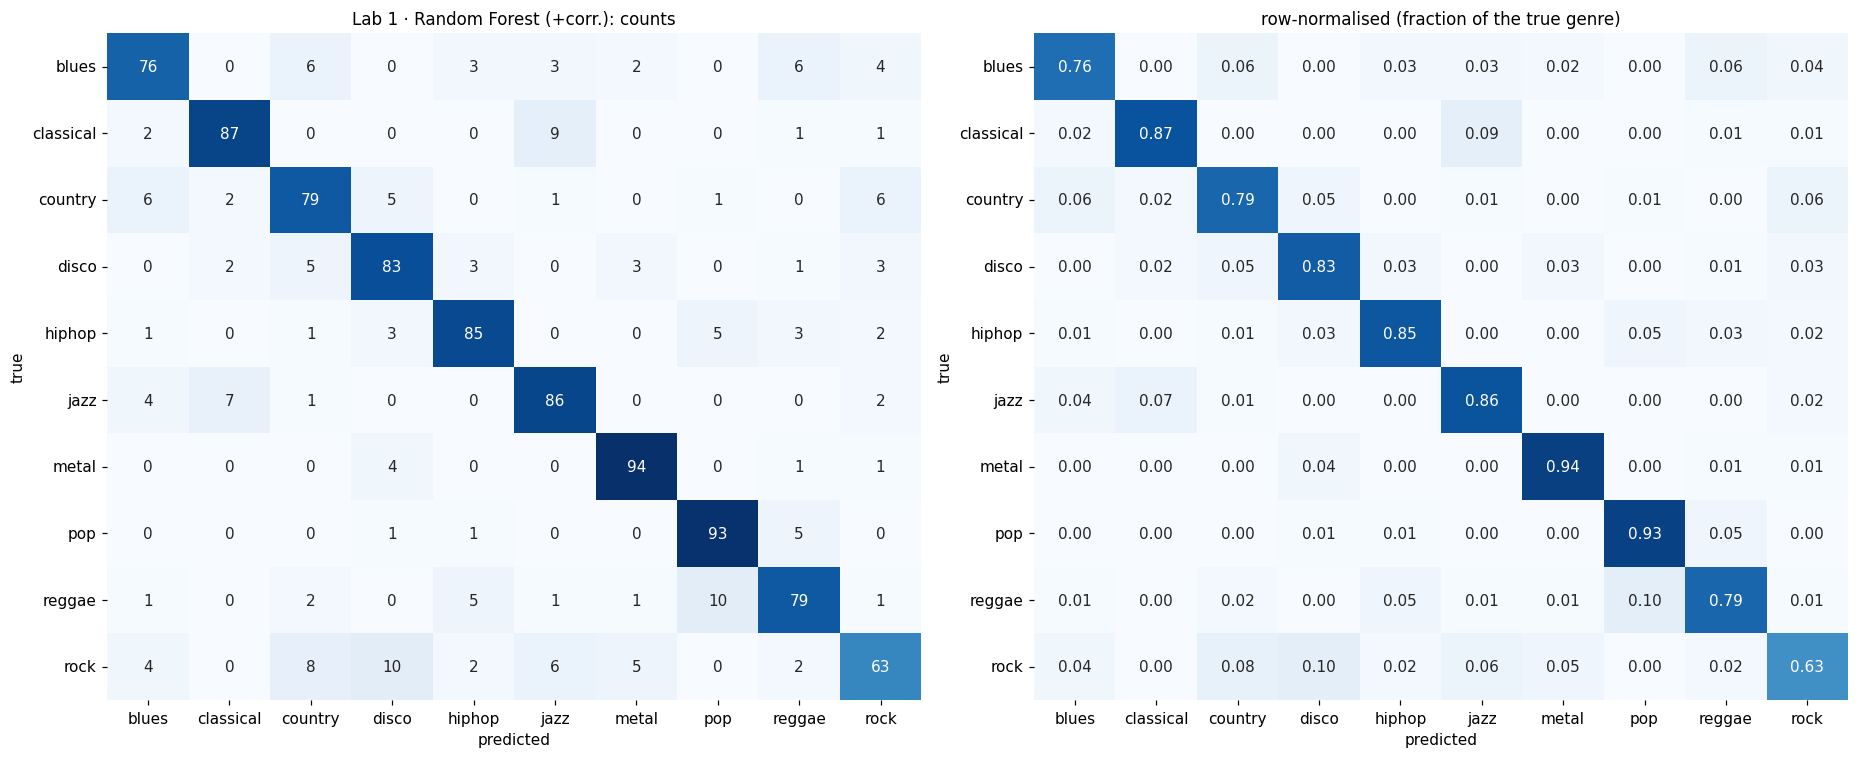

,support,precision,recall,f1,top2_recall
genre,,,,,
blues,100.0,0.809,0.760,0.784,0.940
classical,100.0,0.888,0.870,0.879,0.920
country,100.0,0.775,0.790,0.782,0.880
disco,100.0,0.783,0.830,0.806,0.900
hiphop,100.0,0.859,0.850,0.854,0.930
jazz,100.0,0.811,0.860,0.835,0.970
metal,100.0,0.895,0.940,0.917,0.990
pop,100.0,0.853,0.930,0.890,0.970
reggae,100.0,0.806,0.790,0.798,0.860


### Lab 1 · Random Forest (+corr.) — 2. How sure is it when it is right and when it is wrong?

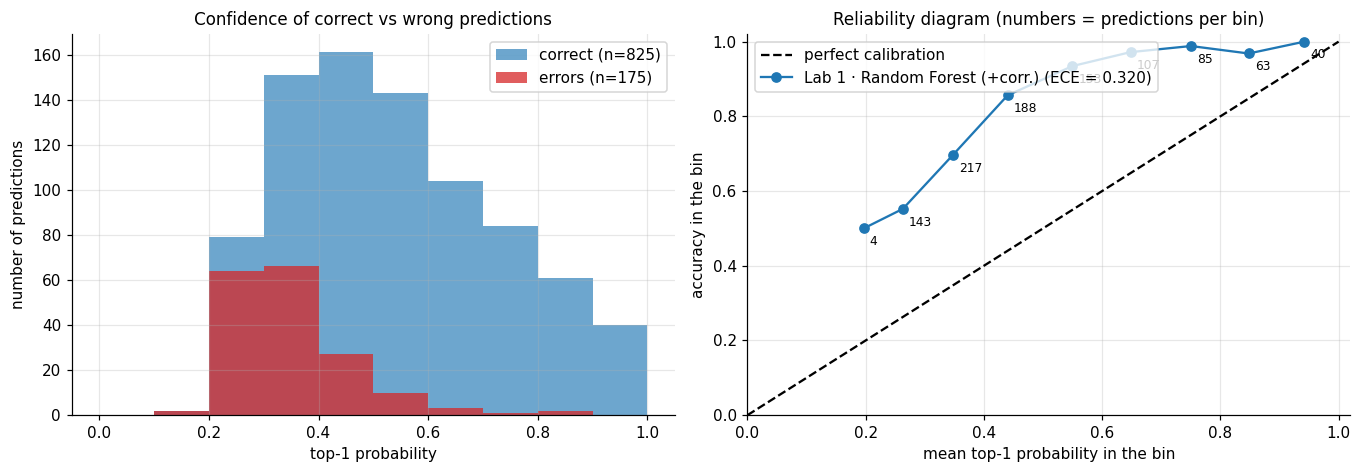

mean confidence  correct: 0.538 | errors: 0.348
AUROC of the confidence for separating correct from wrong predictions: 0.807  (0.5 = cannot tell; 1 = perfect)
errors with p1 >= 0.9: 0 of 175 (0%) | correct predictions with p1 >= 0.9: 5%


### Lab 1 · Random Forest (+corr.) — 3. Top-1 vs top-2 probability

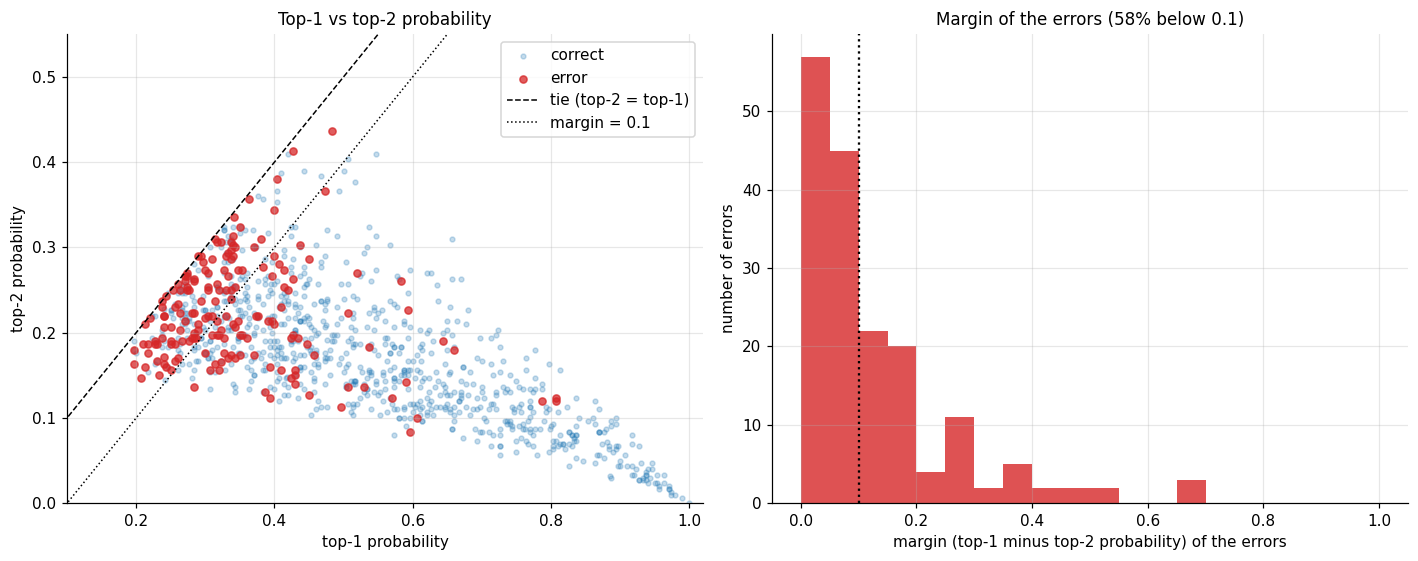

### Lab 1 · Random Forest (+corr.) — 4. Error types

,n_errors,% of errors
category,,
confident error,0,0.0
"near-tie, true = runner-up",57,32.6
"near-tie, other runner-up",45,25.7
runner-up miss,41,23.4
other error (true rank >= 3),32,18.3


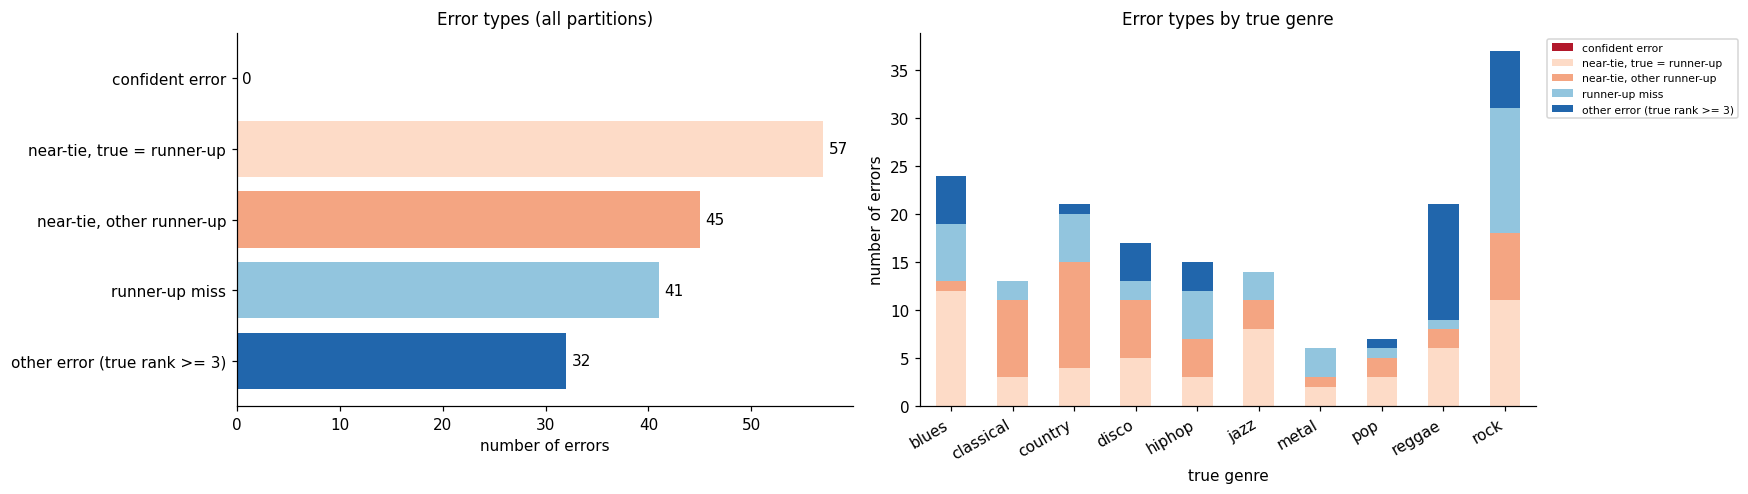

top-k accuracy: {'top-1': 0.827, 'top-2': 0.925, 'top-3': 0.972}
of the 175 errors, in 98 (56%) the true class was the 2nd most probable; in 28 (16%) it was 4th or worse.


### Lab 1 · Random Forest (+corr.) — 5. By genre and by pair of genres

,n,recall,top2_recall,n_errors,mean_p_true_in_errors,mean_p_pred_in_errors,% near-tie (<0.10),% true=runner-up,% confident (>=0.90)
blues,100,0.76,0.94,24,0.216,0.350,0.542,0.750,0.0
classical,100,0.87,0.92,13,0.158,0.271,0.846,0.385,0.0
country,100,0.79,0.88,21,0.190,0.302,0.714,0.429,0.0
disco,100,0.83,0.90,17,0.194,0.331,0.647,0.412,0.0
hiphop,100,0.85,0.93,15,0.163,0.420,0.467,0.533,0.0
jazz,100,0.86,0.97,14,0.251,0.388,0.786,0.786,0.0
metal,100,0.94,0.99,6,0.197,0.398,0.500,0.833,0.0
pop,100,0.93,0.97,7,0.248,0.350,0.714,0.571,0.0
reggae,100,0.79,0.86,21,0.146,0.359,0.381,0.333,0.0
rock,100,0.63,0.89,37,0.196,0.348,0.486,0.649,0.0


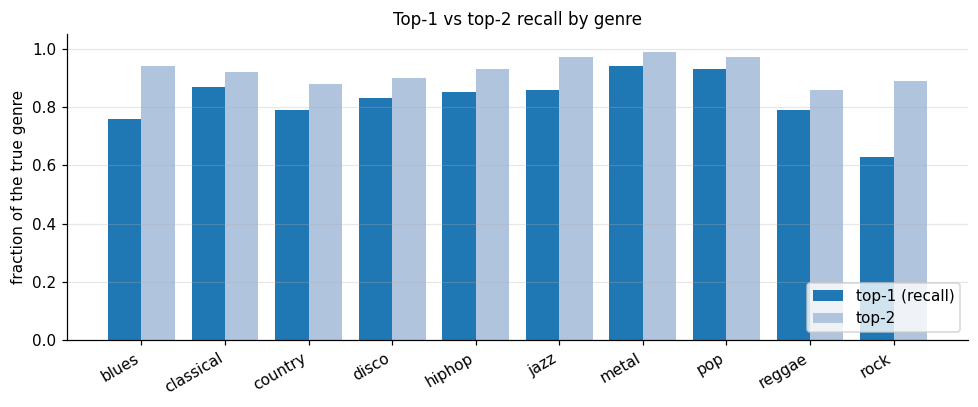

Most frequent true -> predicted pairs (reading: 'country -> rock: n times, with mean p(rock) ... and mean p(country) ...'):


,true_name,pred_name,n,mean_p_pred,mean_p_true,median_margin,share_true_is_runner_up,share_near_tie
0,reggae,pop,10,0.403,0.199,0.162,0.500,0.400
1,rock,disco,10,0.364,0.187,0.152,0.700,0.200
2,classical,jazz,9,0.287,0.181,0.057,0.556,0.778
3,rock,country,8,0.312,0.179,0.112,0.625,0.500
4,jazz,classical,7,0.467,0.283,0.070,1.000,0.714
5,country,rock,6,0.362,0.186,0.135,0.667,0.333
6,blues,reggae,6,0.360,0.227,0.105,0.667,0.500
7,rock,jazz,6,0.320,0.212,0.100,0.833,0.500
8,blues,country,6,0.311,0.211,0.060,1.000,0.667
9,country,blues,6,0.278,0.213,0.007,0.333,1.000


### Lab 1 · Random Forest (+corr.) — 6. Individual songs

TIGHTEST CALLS (errors with the smallest top-1 minus top-2 margin):


,song,seed,true_name,pred_name,p1,second_name,p2,p_true,rank_true
195,rock.00074,42,rock,blues,0.290,rock,0.290,0.290,1
440,country.00003,44,country,pop,0.243,reggae,0.243,0.157,3
597,rock.00082,44,rock,blues,0.237,rock,0.237,0.237,1
45,country.00023,42,country,classical,0.273,jazz,0.270,0.153,3
217,blues.00091,43,blues,reggae,0.213,country,0.210,0.190,3
54,country.00069,42,country,blues,0.313,country,0.310,0.310,2
32,classical.00046,42,classical,rock,0.253,jazz,0.250,0.200,3
795,rock.00061,45,rock,jazz,0.293,rock,0.290,0.290,2
459,country.00099,44,country,blues,0.270,rock,0.267,0.170,3
780,rock.00003,45,rock,blues,0.260,rock,0.257,0.257,2


MOST CONFIDENT ERRORS (highest top-1 probability while wrong):


,song,seed,true_name,pred_name,p1,second_name,p2,p_true,rank_true
582,rock.00016,44,rock,metal,0.807,rock,0.123,0.123,2
932,metal.00058,46,metal,rock,0.807,metal,0.120,0.120,2
703,jazz.00014,45,jazz,classical,0.787,jazz,0.120,0.120,2
695,hiphop.00077,45,hiphop,pop,0.660,hiphop,0.180,0.180,2
296,hiphop.00077,43,hiphop,pop,0.643,hiphop,0.190,0.190,2
883,hiphop.00031,46,hiphop,pop,0.607,disco,0.100,0.090,3
286,hiphop.00031,43,hiphop,pop,0.597,hiphop,0.083,0.083,2
500,jazz.00001,44,jazz,classical,0.593,jazz,0.227,0.227,2
80,hiphop.00000,42,hiphop,disco,0.590,metal,0.142,0.083,4
977,reggae.00087,46,reggae,pop,0.583,hiphop,0.260,0.097,3


668 distinct test songs; 268 appear in the test set of >= 2 partitions; 33 of them are wrong EVERY time
of the 101 errors on songs evaluated >= 2 times, 73% belong to songs that always fail


,genre,n_eval,n_wrong,mean_p_true,most_common_pred,frac_wrong
song,,,,,,
reggae.00022,reggae,4,4,0.086,hiphop,1.0
rock.00051,rock,4,4,0.190,disco,1.0
hiphop.00031,hiphop,3,3,0.098,pop,1.0
country.00099,country,3,3,0.154,blues,1.0
pop.00081,pop,3,3,0.193,reggae,1.0
blues.00001,blues,3,3,0.227,reggae,1.0
classical.00051,classical,2,2,0.050,reggae,1.0
blues.00075,blues,2,2,0.073,hiphop,1.0
classical.00054,classical,2,2,0.085,blues,1.0


In [6]:
REPORTS["Descriptors (Lab 1)"] = error_report(LAB1_BEST)

## 4. CNN trained from scratch
The 4-block CNN selected in Task 1, trained on the mel-spectrogram images for a fixed number of epochs.

### CNN from scratch — 1. Confusion matrix (all 5 partitions pooled)

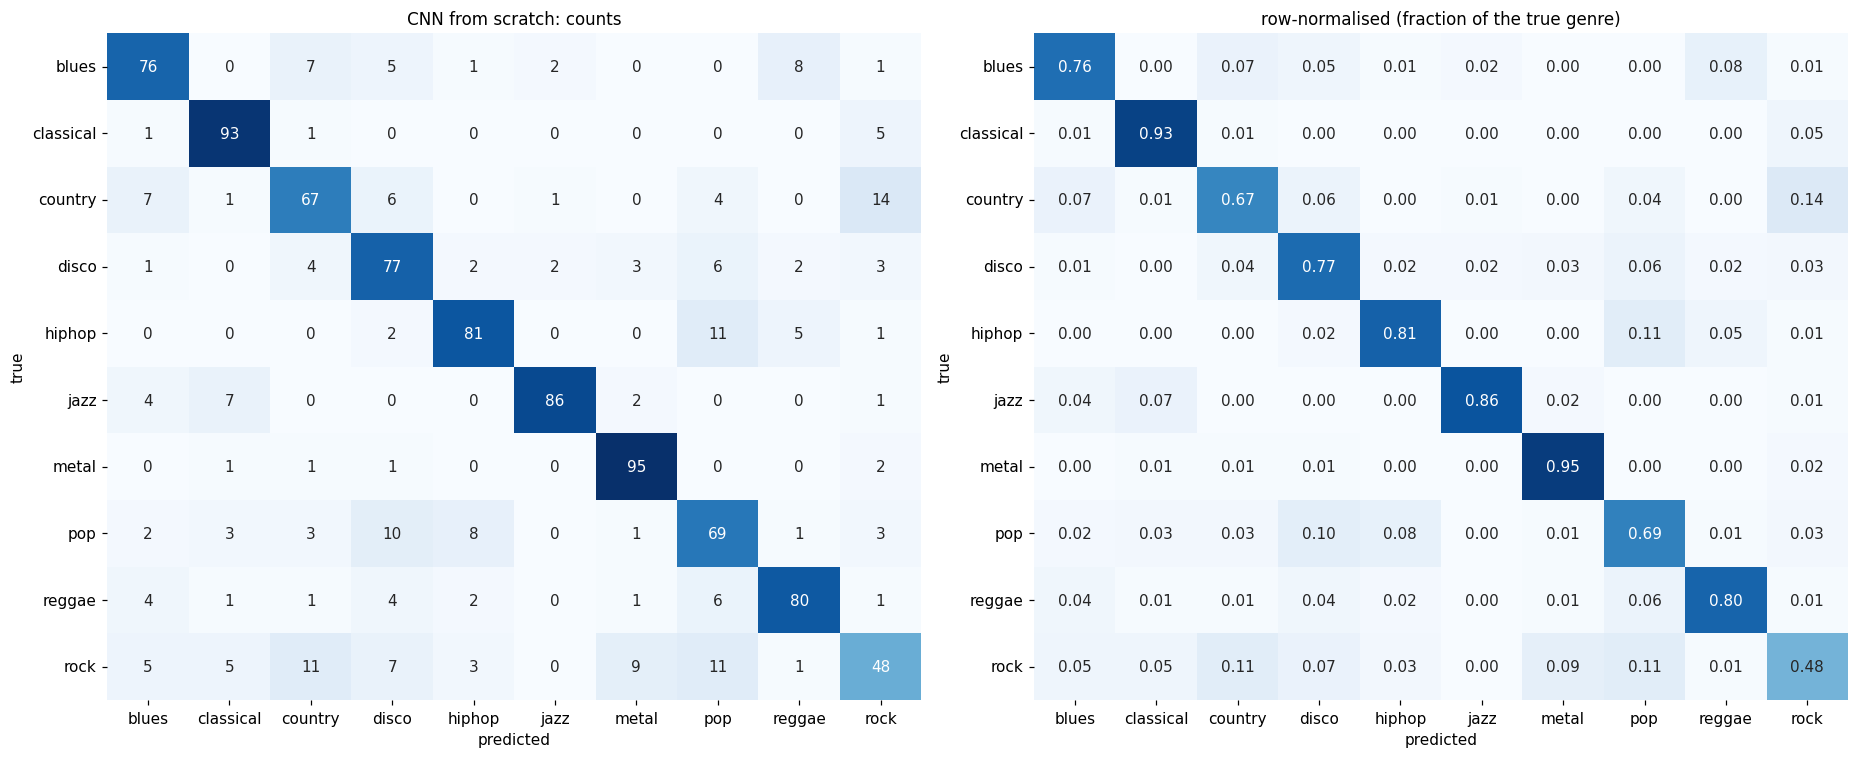

,support,precision,recall,f1,top2_recall
genre,,,,,
blues,100.0,0.760,0.760,0.760,0.890
classical,100.0,0.838,0.930,0.882,0.950
country,100.0,0.705,0.670,0.687,0.820
disco,100.0,0.688,0.770,0.726,0.880
hiphop,100.0,0.835,0.810,0.822,0.920
jazz,100.0,0.945,0.860,0.901,0.930
metal,100.0,0.856,0.950,0.900,0.980
pop,100.0,0.645,0.690,0.667,0.860
reggae,100.0,0.825,0.800,0.812,0.900


### CNN from scratch — 2. How sure is it when it is right and when it is wrong?

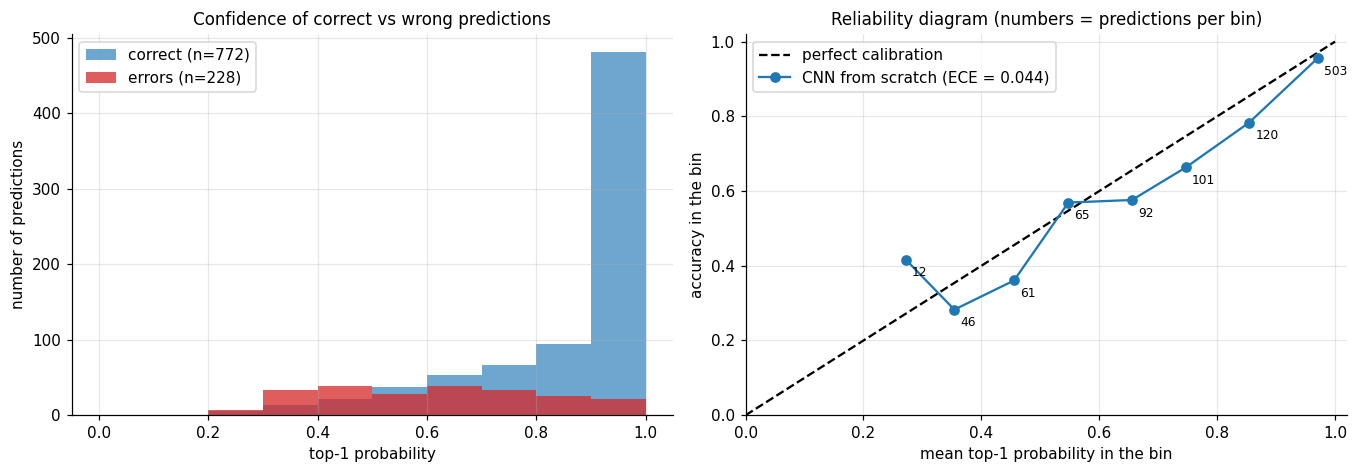

mean confidence  correct: 0.867 | errors: 0.616
AUROC of the confidence for separating correct from wrong predictions: 0.838  (0.5 = cannot tell; 1 = perfect)
errors with p1 >= 0.9: 22 of 228 (10%) | correct predictions with p1 >= 0.9: 62%


### CNN from scratch — 3. Top-1 vs top-2 probability

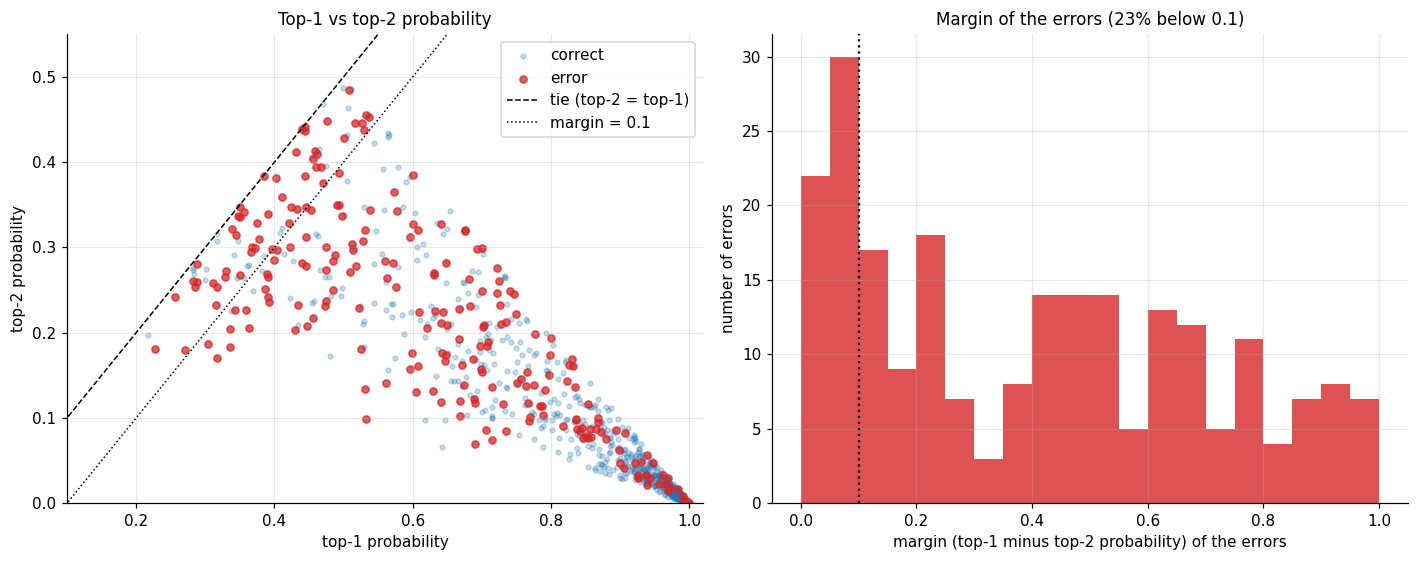

### CNN from scratch — 4. Error types

,n_errors,% of errors
category,,
confident error,22,9.6
"near-tie, true = runner-up",24,10.5
"near-tie, other runner-up",28,12.3
runner-up miss,86,37.7
other error (true rank >= 3),68,29.8


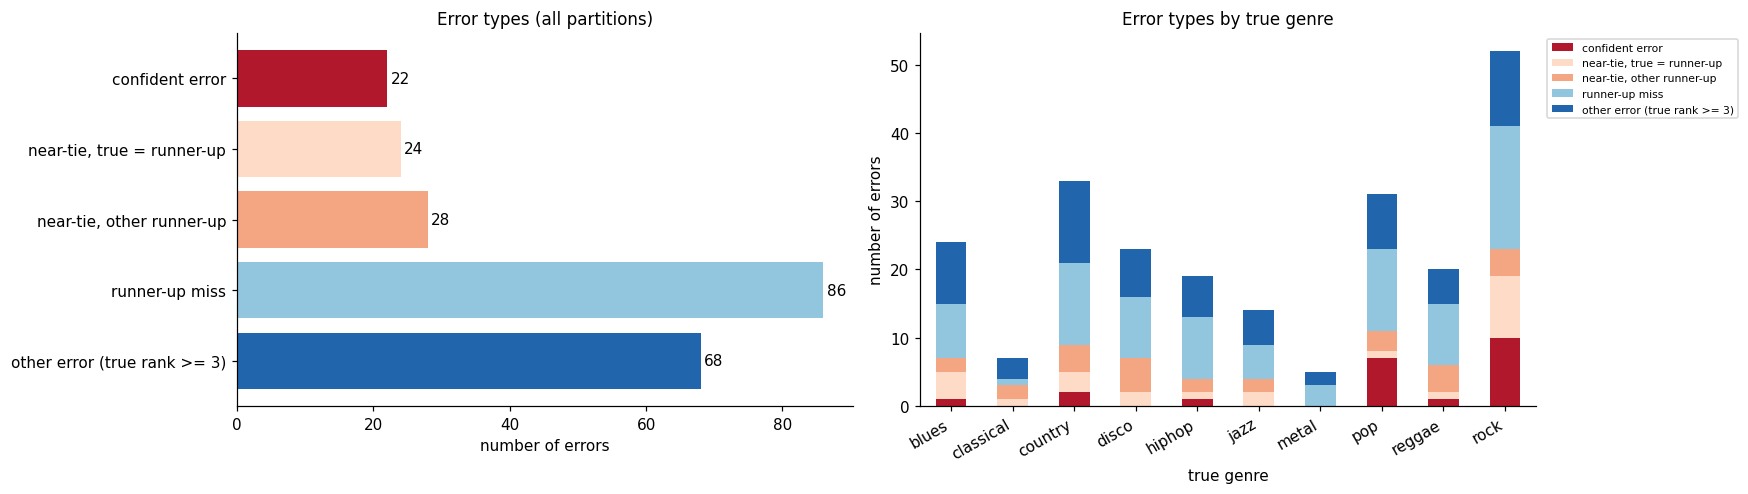

top-k accuracy: {'top-1': 0.772, 'top-2': 0.894, 'top-3': 0.938}
of the 228 errors, in 122 (54%) the true class was the 2nd most probable; in 62 (27%) it was 4th or worse.


### CNN from scratch — 5. By genre and by pair of genres

,n,recall,top2_recall,n_errors,mean_p_true_in_errors,mean_p_pred_in_errors,% near-tie (<0.10),% true=runner-up,% confident (>=0.90)
blues,100,0.76,0.89,24,0.160,0.583,0.250,0.542,0.042
classical,100,0.93,0.95,7,0.125,0.517,0.429,0.286,0.000
country,100,0.67,0.82,33,0.122,0.590,0.212,0.455,0.061
disco,100,0.77,0.88,23,0.127,0.604,0.304,0.478,0.000
hiphop,100,0.81,0.92,19,0.174,0.601,0.158,0.579,0.053
jazz,100,0.86,0.93,14,0.204,0.563,0.286,0.500,0.000
metal,100,0.95,0.98,5,0.211,0.558,0.000,0.600,0.000
pop,100,0.69,0.86,31,0.132,0.703,0.129,0.548,0.226
reggae,100,0.80,0.90,20,0.139,0.591,0.250,0.500,0.050
rock,100,0.48,0.81,52,0.165,0.651,0.250,0.635,0.192


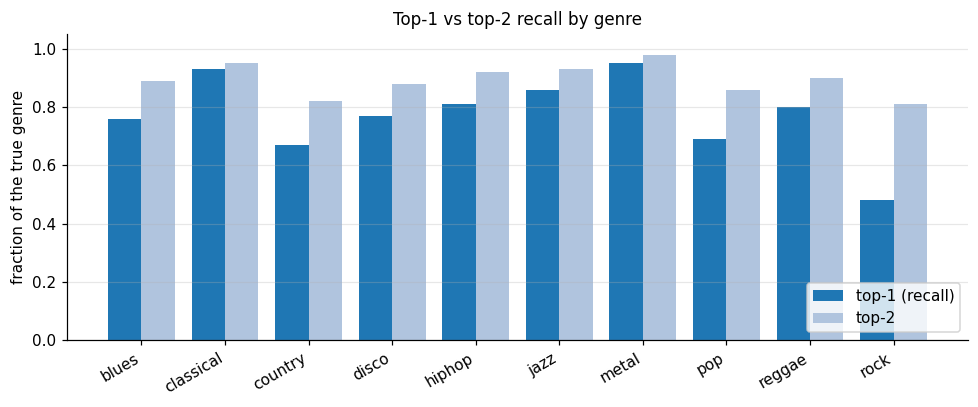

Most frequent true -> predicted pairs (reading: 'country -> rock: n times, with mean p(rock) ... and mean p(country) ...'):


,true_name,pred_name,n,mean_p_pred,mean_p_true,median_margin,share_true_is_runner_up,share_near_tie
0,country,rock,14,0.612,0.165,0.251,0.714,0.214
1,rock,pop,11,0.801,0.070,0.778,0.364,0.182
2,hiphop,pop,11,0.681,0.186,0.452,0.818,0.000
3,rock,country,11,0.668,0.191,0.240,0.818,0.091
4,pop,disco,10,0.752,0.159,0.521,0.800,0.000
5,rock,metal,9,0.770,0.172,0.728,0.889,0.333
6,pop,hiphop,8,0.758,0.165,0.691,0.875,0.125
7,blues,reggae,8,0.585,0.233,0.332,0.875,0.250
8,blues,country,7,0.619,0.134,0.480,0.429,0.143
9,jazz,classical,7,0.574,0.170,0.287,0.429,0.286


### CNN from scratch — 6. Individual songs

TIGHTEST CALLS (errors with the smallest top-1 minus top-2 margin):


,song,seed,true_name,pred_name,p1,second_name,p2,p_true,rank_true
245,country.00014,43,country,disco,0.439,pop,0.439,0.031,4
409,blues.00057,44,blues,reggae,0.385,blues,0.384,0.384,2
117,jazz.00089,42,jazz,classical,0.444,jazz,0.441,0.441,2
666,disco.00047,45,disco,jazz,0.351,classical,0.347,0.002,8
975,reggae.00070,46,reggae,hiphop,0.443,reggae,0.436,0.436,2
834,classical.00054,46,classical,blues,0.288,rock,0.280,0.042,5
70,disco.00047,42,disco,jazz,0.347,classical,0.337,0.006,7
633,classical.00054,45,classical,country,0.255,blues,0.242,0.053,5
459,country.00099,44,country,rock,0.349,country,0.335,0.335,2
189,rock.00054,42,rock,disco,0.356,rock,0.341,0.341,2


MOST CONFIDENT ERRORS (highest top-1 probability while wrong):


,song,seed,true_name,pred_name,p1,second_name,p2,p_true,rank_true
783,rock.00016,45,rock,metal,0.999,rock,0.000,0.000,2
582,rock.00016,44,rock,metal,0.999,rock,0.001,0.001,2
793,rock.00051,45,rock,pop,0.993,hiphop,0.004,0.001,4
551,pop.00069,44,pop,hiphop,0.990,metal,0.008,0.000,6
557,pop.00093,44,pop,disco,0.984,pop,0.016,0.016,2
785,rock.00019,45,rock,metal,0.972,rock,0.019,0.019,2
588,rock.00051,44,rock,pop,0.970,hiphop,0.014,0.012,3
576,reggae.00088,44,reggae,pop,0.969,disco,0.030,0.000,4
151,pop.00062,42,pop,hiphop,0.965,pop,0.022,0.022,2
415,blues.00083,44,blues,disco,0.961,blues,0.033,0.033,2


668 distinct test songs; 268 appear in the test set of >= 2 partitions; 46 of them are wrong EVERY time
of the 143 errors on songs evaluated >= 2 times, 73% belong to songs that always fail


,genre,n_eval,n_wrong,mean_p_true,most_common_pred,frac_wrong
song,,,,,,
rock.00051,rock,4,4,0.007,pop,1.0
disco.00013,disco,3,3,0.009,metal,1.0
blues.00072,blues,3,3,0.016,jazz,1.0
pop.00081,pop,3,3,0.043,rock,1.0
rock.00058,rock,3,3,0.068,pop,1.0
rock.00003,rock,3,3,0.144,blues,1.0
country.00027,country,3,3,0.201,rock,1.0
rock.00064,rock,3,3,0.201,disco,1.0
hiphop.00031,hiphop,3,3,0.208,pop,1.0


In [7]:
REPORTS["CNN from scratch"] = error_report(CNN)

## 5. Pretrained vision model (VGG16 fine-tuned)
VGG16 pretrained on ImageNet and fine-tuned from the fourth convolutional block onwards (configuration selected on the validation set in Task 2), trained on each partition by `multiseed_retraining`. The Task 2 search on the main partition (other networks and strategies, VGGish) is analysed in Part IV.

### VGG16 fine-tuned — 1. Confusion matrix (all 5 partitions pooled)

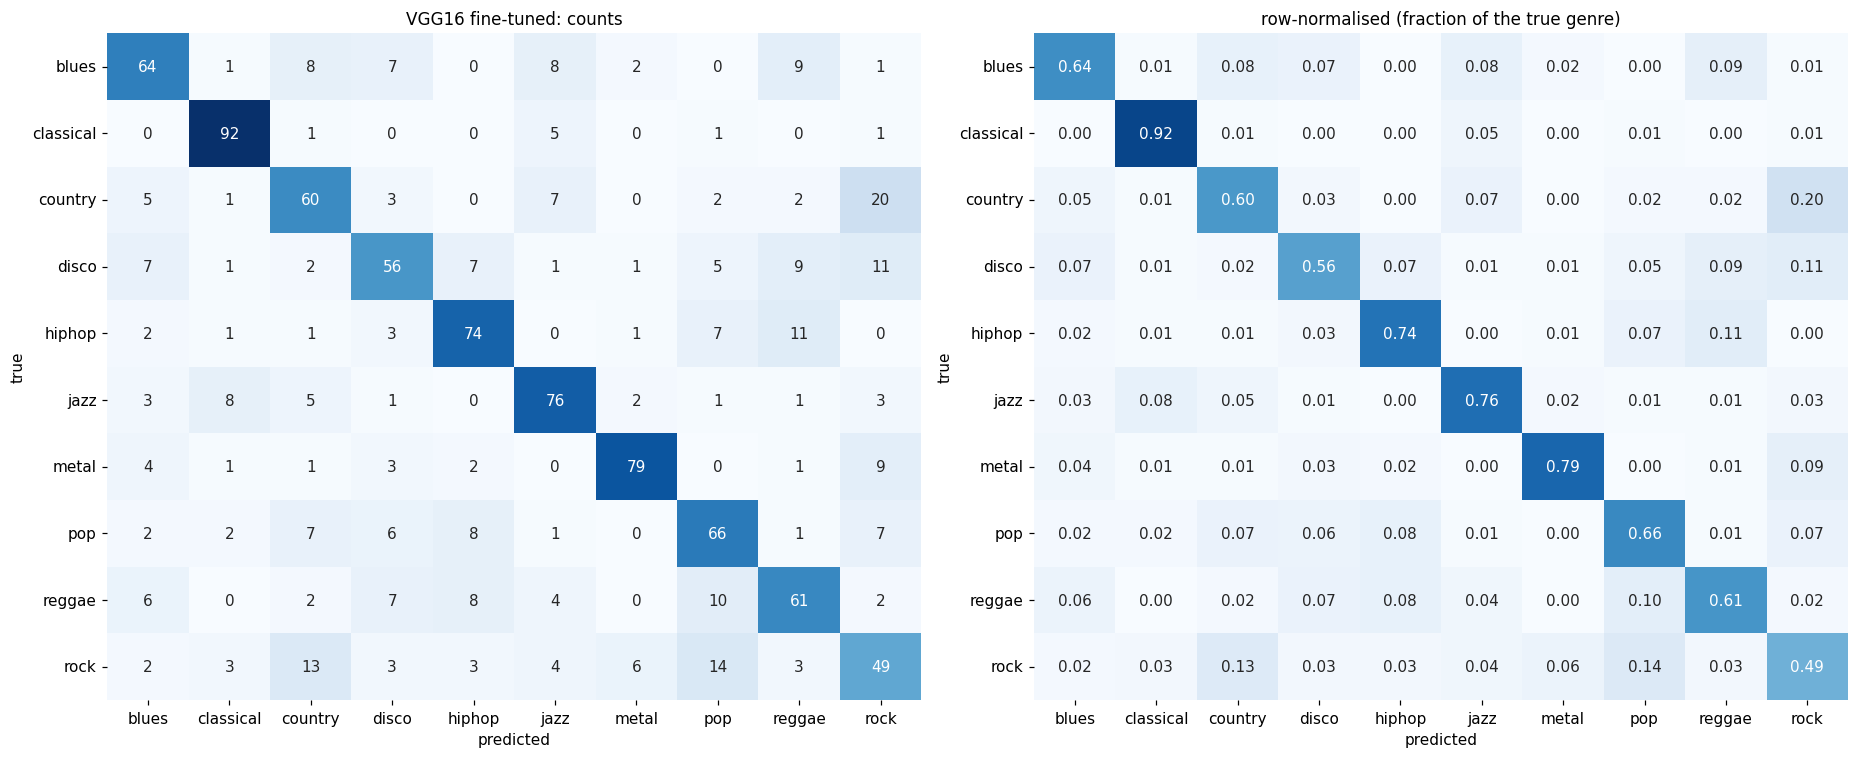

,support,precision,recall,f1,top2_recall
genre,,,,,
blues,100.0,0.674,0.640,0.656,0.810
classical,100.0,0.836,0.920,0.876,0.960
country,100.0,0.600,0.600,0.600,0.770
disco,100.0,0.629,0.560,0.593,0.770
hiphop,100.0,0.725,0.740,0.733,0.860
jazz,100.0,0.717,0.760,0.738,0.900
metal,100.0,0.868,0.790,0.827,0.900
pop,100.0,0.623,0.660,0.641,0.800
reggae,100.0,0.622,0.610,0.616,0.810


### VGG16 fine-tuned — 2. How sure is it when it is right and when it is wrong?

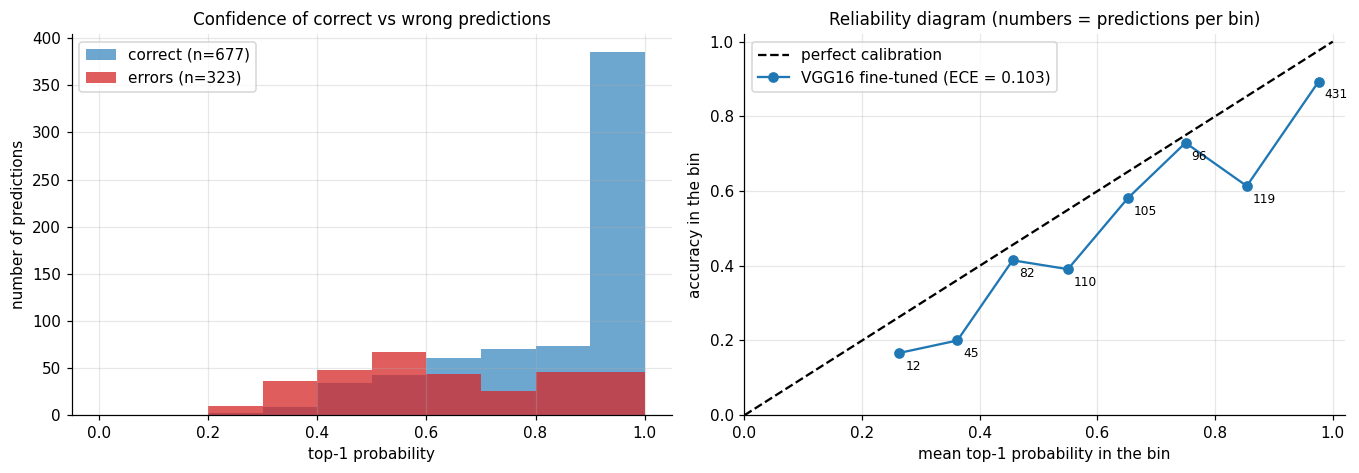

mean confidence  correct: 0.849 | errors: 0.636
AUROC of the confidence for separating correct from wrong predictions: 0.795  (0.5 = cannot tell; 1 = perfect)
errors with p1 >= 0.9: 46 of 323 (14%) | correct predictions with p1 >= 0.9: 57%


### VGG16 fine-tuned — 3. Top-1 vs top-2 probability

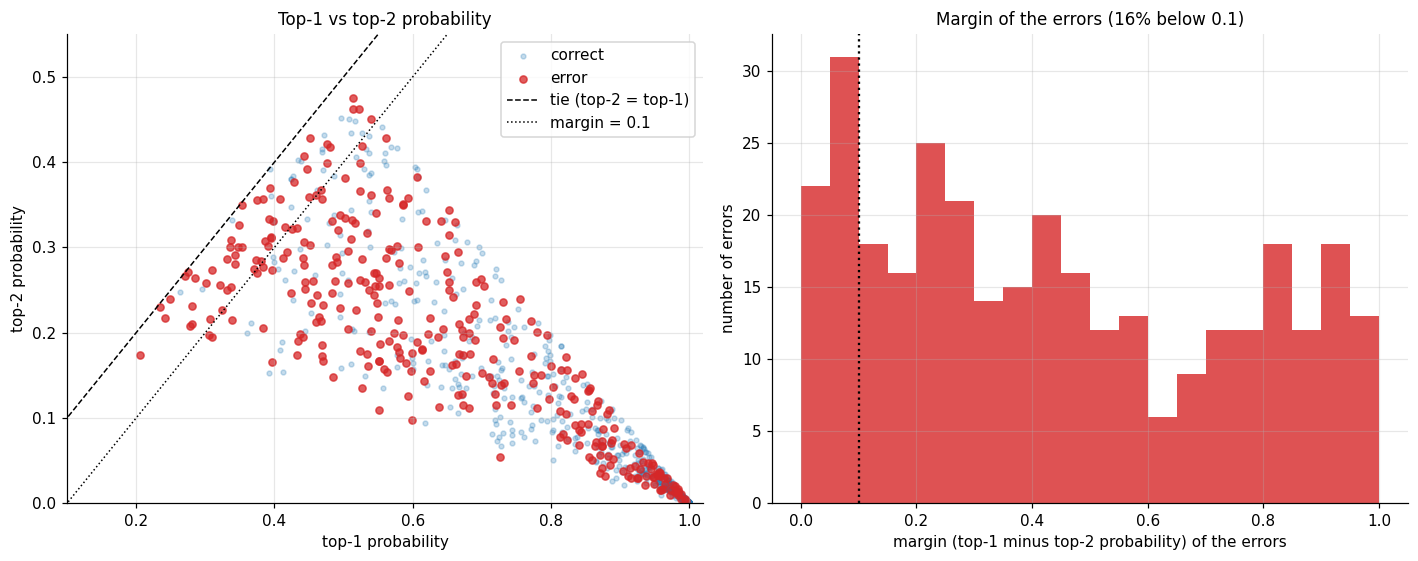

### VGG16 fine-tuned — 4. Error types

,n_errors,% of errors
category,,
confident error,46,14.2
"near-tie, true = runner-up",23,7.1
"near-tie, other runner-up",30,9.3
runner-up miss,113,35.0
other error (true rank >= 3),111,34.4


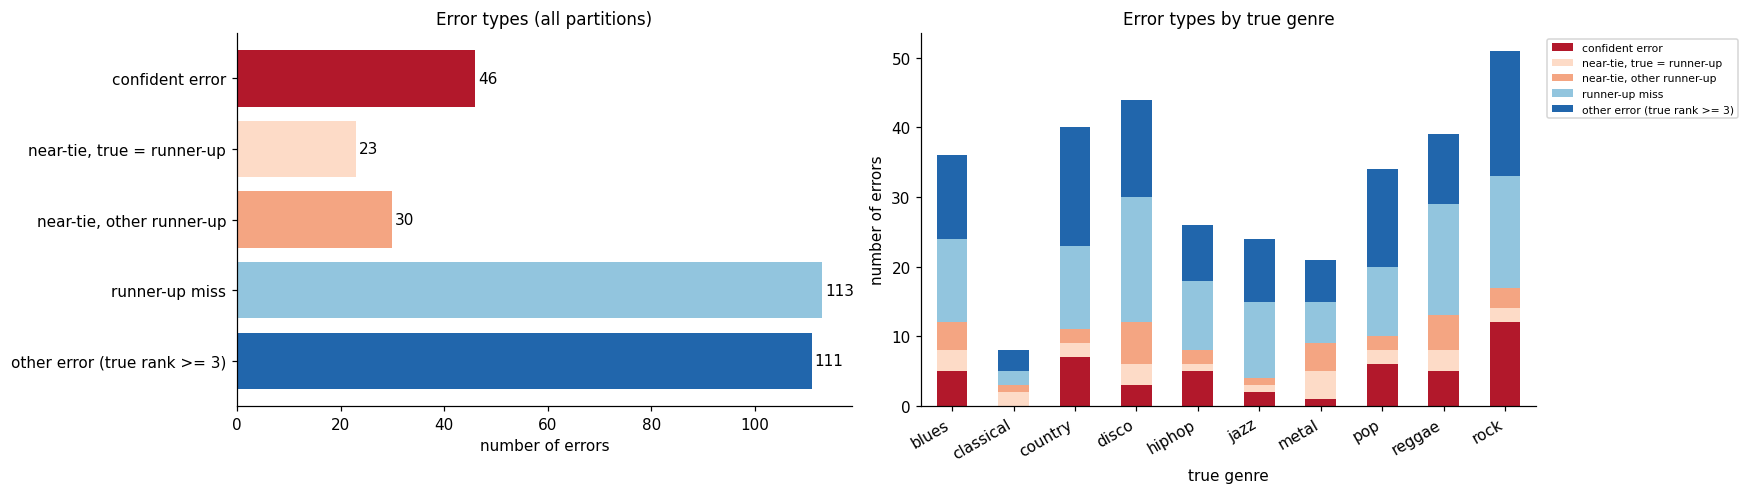

top-k accuracy: {'top-1': 0.677, 'top-2': 0.829, 'top-3': 0.902}
of the 323 errors, in 152 (47%) the true class was the 2nd most probable; in 98 (30%) it was 4th or worse.


### VGG16 fine-tuned — 5. By genre and by pair of genres

,n,recall,top2_recall,n_errors,mean_p_true_in_errors,mean_p_pred_in_errors,% near-tie (<0.10),% true=runner-up,% confident (>=0.90)
blues,100,0.64,0.81,36,0.147,0.605,0.194,0.472,0.139
classical,100,0.92,0.96,8,0.172,0.581,0.375,0.500,0.000
country,100,0.60,0.77,40,0.111,0.667,0.100,0.425,0.175
disco,100,0.56,0.77,44,0.151,0.580,0.205,0.477,0.068
hiphop,100,0.74,0.86,26,0.124,0.654,0.115,0.462,0.192
jazz,100,0.76,0.90,24,0.167,0.614,0.083,0.583,0.083
metal,100,0.79,0.90,21,0.135,0.565,0.381,0.524,0.048
pop,100,0.66,0.80,34,0.118,0.691,0.118,0.412,0.176
reggae,100,0.61,0.81,39,0.145,0.623,0.205,0.513,0.128
rock,100,0.49,0.71,51,0.098,0.695,0.098,0.431,0.235


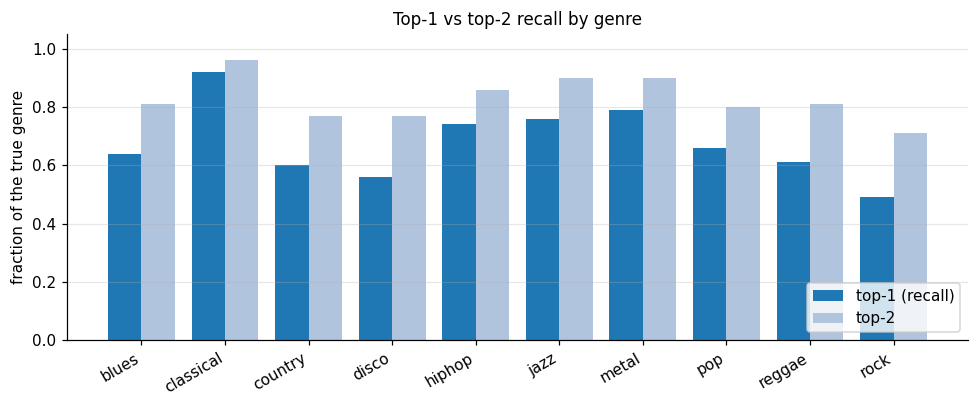

Most frequent true -> predicted pairs (reading: 'country -> rock: n times, with mean p(rock) ... and mean p(country) ...'):


,true_name,pred_name,n,mean_p_pred,mean_p_true,median_margin,share_true_is_runner_up,share_near_tie
0,country,rock,20,0.709,0.094,0.546,0.300,0.100
1,rock,pop,14,0.789,0.060,0.712,0.357,0.000
2,rock,country,13,0.674,0.154,0.460,0.769,0.077
3,hiphop,reggae,11,0.761,0.140,0.650,0.727,0.091
4,disco,rock,11,0.573,0.156,0.296,0.364,0.000
5,reggae,pop,10,0.665,0.108,0.558,0.400,0.200
6,disco,reggae,9,0.634,0.133,0.426,0.444,0.111
7,metal,rock,9,0.617,0.144,0.385,0.667,0.111
8,blues,reggae,9,0.512,0.161,0.107,0.444,0.444
9,jazz,classical,8,0.676,0.189,0.347,0.875,0.000


### VGG16 fine-tuned — 6. Individual songs

TIGHTEST CALLS (errors with the smallest top-1 minus top-2 margin):


,song,seed,true_name,pred_name,p1,second_name,p2,p_true,rank_true
652,country.00040,45,country,reggae,0.274,rock,0.272,0.044,6
868,disco.00033,46,disco,country,0.353,rock,0.350,0.212,3
768,reggae.00048,45,reggae,blues,0.235,disco,0.231,0.137,4
118,jazz.00090,42,jazz,rock,0.271,classical,0.266,0.174,3
881,hiphop.00015,46,hiphop,pop,0.249,disco,0.239,0.131,3
775,reggae.00082,45,reggae,hiphop,0.375,reggae,0.356,0.356,2
609,blues.00046,45,blues,reggae,0.285,blues,0.265,0.265,2
48,country.00043,42,country,rock,0.451,disco,0.429,0.117,3
9,blues.00057,42,blues,reggae,0.349,hiphop,0.326,0.099,4
67,disco.00029,42,disco,pop,0.393,disco,0.370,0.370,2


MOST CONFIDENT ERRORS (highest top-1 probability while wrong):


,song,seed,true_name,pred_name,p1,second_name,p2,p_true,rank_true
582,rock.00016,44,rock,metal,0.995,blues,0.002,0.002,3
391,rock.00057,43,rock,pop,0.994,disco,0.005,0.000,3
576,reggae.00088,44,reggae,pop,0.989,disco,0.010,0.000,4
188,rock.00052,42,rock,pop,0.988,rock,0.005,0.005,2
138,metal.00097,42,metal,blues,0.984,metal,0.010,0.010,2
47,country.00037,42,country,rock,0.984,country,0.014,0.014,2
143,pop.00017,42,pop,rock,0.984,country,0.012,0.004,3
383,rock.00021,43,rock,country,0.984,rock,0.016,0.016,2
213,blues.00075,43,blues,disco,0.980,rock,0.013,0.001,4
317,jazz.00082,43,jazz,pop,0.979,jazz,0.020,0.020,2


668 distinct test songs; 268 appear in the test set of >= 2 partitions; 66 of them are wrong EVERY time
of the 207 errors on songs evaluated >= 2 times, 70% belong to songs that always fail


,genre,n_eval,n_wrong,mean_p_true,most_common_pred,frac_wrong
song,,,,,,
pop.00062,pop,4,4,0.041,hiphop,1.0
rock.00051,rock,4,4,0.118,pop,1.0
pop.00081,pop,3,3,0.015,rock,1.0
rock.00064,rock,3,3,0.021,reggae,1.0
country.00027,country,3,3,0.050,rock,1.0
blues.00072,blues,3,3,0.051,metal,1.0
rock.00058,rock,3,3,0.073,country,1.0
country.00005,country,3,3,0.090,rock,1.0
disco.00013,disco,3,3,0.100,metal,1.0


In [8]:
REPORTS["Pretrained vision (VGG16 fine-tuned)"] = error_report(VGG_FT)

## 6. The three approaches side by side: how do they fail?
Summary of the error behaviour of the three approaches, from the pooled predictions of the five partitions. Calibration is compared directly, which is the right place to contrast probabilities of different model families.

,Descriptors (Lab 1),CNN from scratch,Pretrained vision (VGG16 fine-tuned)
n_observations,1000.000,1000.000,1000.000
n_partitions,5.000,5.000,5.000
accuracy,0.825,0.772,0.677
top2_accuracy,0.925,0.894,0.829
top3_accuracy,0.972,0.938,0.902
mean_conf_correct,0.538,0.867,0.849
mean_conf_errors,0.348,0.616,0.636
AUROC_confidence,0.807,0.838,0.795
ECE,0.320,0.044,0.103
pct_errors_true_is_runner_up,0.560,0.535,0.471


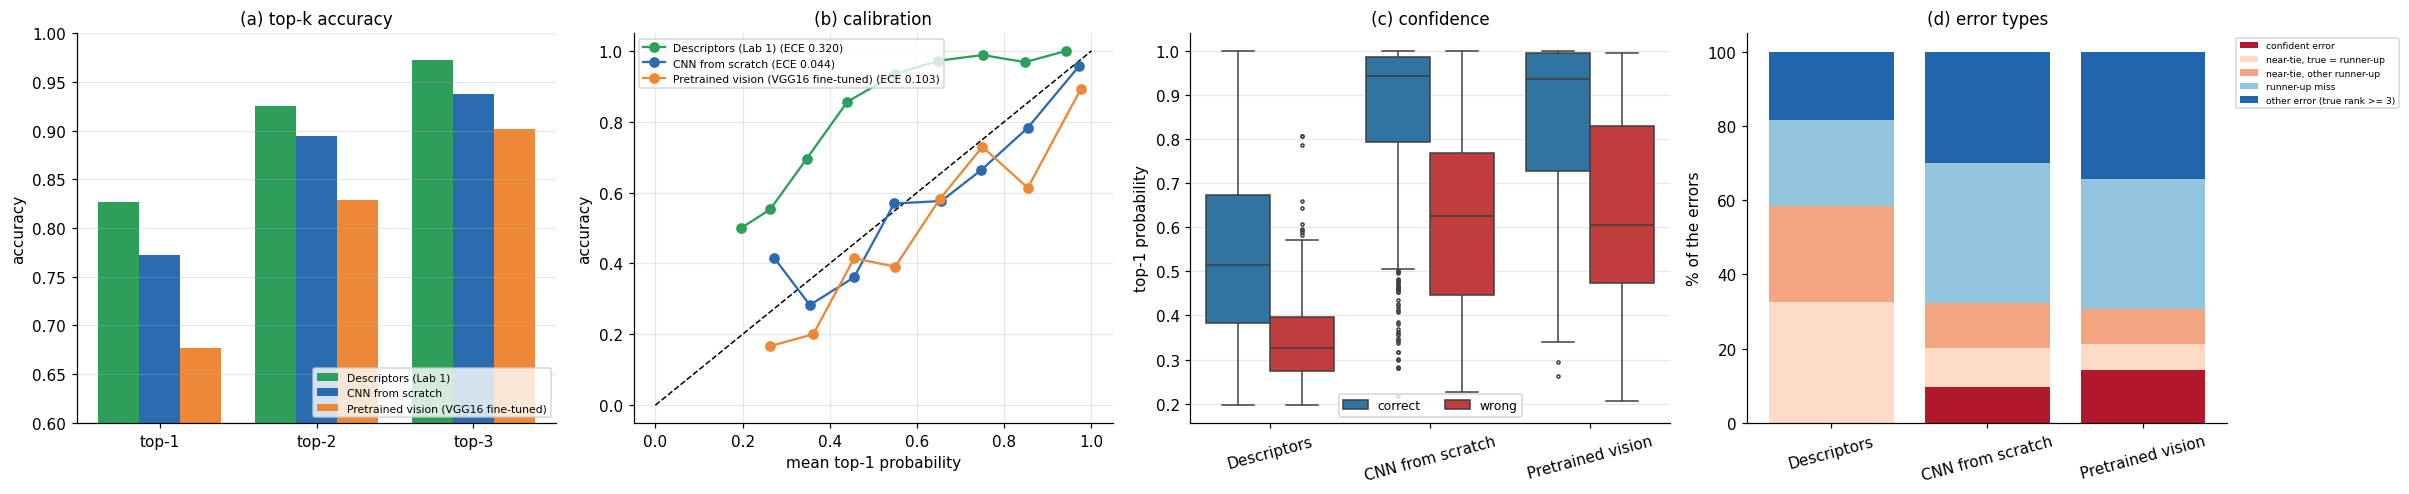

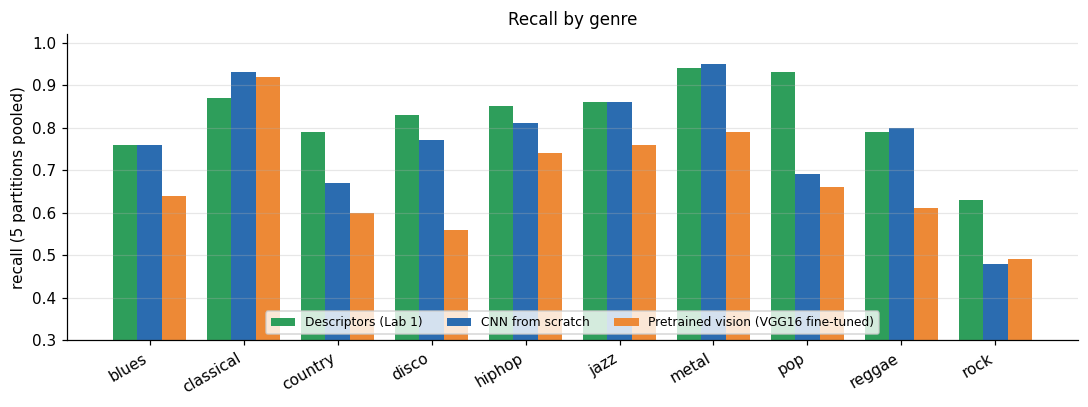

In [9]:
S6 = pd.DataFrame({k: r["summary"] for k, r in REPORTS.items()}).T.drop(columns=["model", "TIE_MARGIN", "CONFIDENT"]).astype(float)
S6.round(3).to_csv(OUT / "table_error_behaviour_summary.csv"); display(S6.round(3).T)

fig, axs = plt.subplots(1, 4, figsize=(22, 4.6)); names = list(REPORTS); cols = [color(r["model"]) for r in REPORTS.values()]
# (a) top-k accuracy
ax = axs[0]; w = 0.26
for i, (k, r) in enumerate(REPORTS.items()): ax.bar(np.arange(3) + (i - 1) * w, [r["topk"][j] for j in (1, 2, 3)], w, color=cols[i], label=k)
ax.set_xticks(range(3)); ax.set_xticklabels(["top-1", "top-2", "top-3"]); ax.set_ylim(0.6, 1.0); ax.set_ylabel("accuracy"); ax.set_title("(a) top-k accuracy"); ax.legend(fontsize=7, loc="lower right"); ax.grid(axis="y", alpha=.3)
# (b) reliability diagrams
ax = axs[1]; ax.plot([0, 1], [0, 1], "k--", lw=1)
for i, (k, r) in enumerate(REPORTS.items()): ax.plot(r["rel"].conf, r["rel"].acc, "o-", color=cols[i], label=f"{k} (ECE {r['ece']:.3f})")
ax.set_xlabel("mean top-1 probability"); ax.set_ylabel("accuracy"); ax.set_title("(b) calibration"); ax.legend(fontsize=7, loc="upper left"); ax.grid(alpha=.3)
# (c) confidence of correct vs wrong predictions
ax = axs[2]; rows = [(k, "correct", r["D"][r["D"].correct].p1) for k, r in REPORTS.items()] + [(k, "wrong", r["ERR"].p1) for k, r in REPORTS.items()]
dfc = pd.concat([pd.DataFrame({"approach": a, "outcome": o, "p1": v}) for a, o, v in rows])
sns.boxplot(data=dfc, x="approach", y="p1", hue="outcome", palette={"correct": "tab:blue", "wrong": "tab:red"}, ax=ax, fliersize=2)
ax.set_xticklabels([n.split(" (")[0] for n in names], rotation=15); ax.set_xlabel(""); ax.set_ylabel("top-1 probability"); ax.set_title("(c) confidence"); ax.grid(axis="y", alpha=.3); ax.legend(loc="lower center", ncol=2, fontsize=8, title=None)
# (d) error types, % of the errors
ax = axs[3]; ECOL = ["#b2182b", "#fddbc7", "#f4a582", "#92c5de", "#2166ac"]; bottom = np.zeros(3)
for j, cat in enumerate(REPORTS[names[0]]["tax"].index):
    v = np.array([REPORTS[k]["tax"].loc[cat, "% of errors"] for k in names]); ax.bar(range(3), v, bottom=bottom, color=ECOL[j], label=cat); bottom += v
ax.set_xticks(range(3)); ax.set_xticklabels([n.split(" (")[0] for n in names], rotation=15); ax.set_ylabel("% of the errors"); ax.set_title("(d) error types"); ax.legend(fontsize=6, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout(); savefig("part1_error_behaviour.png"); plt.show()

# per-genre recall of the three approaches
rec = pd.DataFrame({k: r["per_class"].recall.iloc[:-1] for k, r in REPORTS.items()})
fig, ax = plt.subplots(figsize=(10, 3.8)); w = 0.26
for i, k in enumerate(names): ax.bar(np.arange(len(GENRES)) + (i - 1) * w, rec[k], w, color=cols[i], label=k)
ax.set_xticks(range(len(GENRES))); ax.set_xticklabels(GENRES, rotation=30, ha="right"); ax.set_ylim(0.3, 1.02); ax.set_ylabel("recall (5 partitions pooled)"); ax.grid(axis="y", alpha=.3); ax.legend(fontsize=8, ncol=3, loc="lower center")
ax.set_title("Recall by genre"); plt.tight_layout(); savefig("part1_recall_by_genre.png"); plt.show()
KEY["part1"] = {k: dict(accuracy=float(r["summary"].accuracy), top2=float(r["topk"][2]), ECE=float(r["ece"]), AUROC=float(r["auroc"]),
                        pct_near_tie=float(r["summary"].pct_errors_near_tie), pct_confident=float(r["summary"].pct_errors_confident),
                        pct_stable_songs=float(r["stable"])) for k, r in REPORTS.items()}

# Part II — Comparing the approaches

## 7. Q1 — Do learned features beat hand-crafted descriptors?

All models are compared on the **same test songs**. Two views:

1. **Five partitions** — the models trained on every partition (descriptor models, CNN from scratch, VGG16 fine-tuned, frozen VGG16 + logistic regression): mean ± standard deviation, per-partition accuracy and macro-F1.
2. **Main partition (seed 42)** — *every* model trained in the project on the same 200 songs, including the Task 2 search (12 fine-tuning configurations, frozen embeddings, VGGish) and the CNN run of Task 1, with Wilson 95 % intervals.

A difference only counts as evidence if it survives the paired tests of Section 8; the verdict is collected at the end of that section.

In [10]:
# ---------------- statistical toolbox (used in all later sections) ----------------
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n; c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def mcnemar_exact(a, b):
    # a, b: boolean arrays "model is correct" on the SAME songs. n01 = only A right, n10 = only B right
    n01 = int((a & ~b).sum()); n10 = int((~a & b).sum()); n = n01 + n10
    p = 1.0 if n == 0 else stats.binomtest(min(n01, n10), n, 0.5, alternative="two-sided").pvalue
    return n01, n10, p

def holm(p):
    p = np.asarray(p, dtype=float); o = np.argsort(p); adj = np.empty_like(p); run = 0
    for rank, i in enumerate(o):
        run = max(run, (len(p) - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def nadeau_bengio(d, test_frac=0.2):
    # corrected resampled paired t-test (Nadeau & Bengio, 2003): the variance is inflated by 1/k + n_test/n_train
    d = np.asarray(d); k = len(d)
    if k < 2 or d.std(ddof=1) == 0: return np.nan
    t = d.mean() / np.sqrt((1 / k + test_frac / (1 - test_frac)) * d.var(ddof=1))
    return 2 * stats.t.sf(abs(t), k - 1)

def pairwise(models, seeds=SEEDS_ALL, primary=PRIMARY):
    rows = []
    for a, b in itertools.combinations(models, 2):
        n01, n10, p = mcnemar_exact(correct(a, primary), correct(b, primary))
        d = np.array([correct(a, s).mean() - correct(b, s).mean() for s in seeds])
        rows.append(dict(A=a, B=b, acc_A=correct(a, primary).mean(), acc_B=correct(b, primary).mean(), only_A_right=n01, only_B_right=n10, p_mcnemar=p,
                         mean_diff_seeds=d.mean(), seeds_A_wins=int((d > 0).sum()), n_seeds=len(d), p_nadeau_bengio=nadeau_bengio(d)))
    df = pd.DataFrame(rows); df["p_mcnemar_holm"] = holm(df.p_mcnemar.to_numpy()); df["p_NB_holm"] = holm(df.p_nadeau_bengio.fillna(1).to_numpy())
    df["verdict"] = np.where((df.p_mcnemar_holm < .05) & (df.p_NB_holm < .05), "A≠B (both tests)",
                      np.where((df.p_mcnemar_holm < .05) | (df.p_NB_holm < .05), "partial evidence", "no significant difference"))
    return df

### 7.1 Five partitions: main table

,model,approach,seed42,seed43,seed44,seed45,seed46,mean_acc,std_acc,min_acc,max_acc,mean_f1,acc_primary,wilson95_primary
0,lab1_random_forest_correlation,Hand-crafted descriptors,0.795,0.870,0.835,0.810,0.815,0.825,0.029,0.795,0.870,0.822,0.795,"[0.734, 0.845]"
1,lab1_random_forest_without_selection,Hand-crafted descriptors,0.790,0.865,0.805,0.815,0.800,0.815,0.029,0.790,0.865,0.813,0.790,"[0.728, 0.841]"
2,lab1_extra_trees_correlation,Hand-crafted descriptors,0.785,0.845,0.815,0.795,0.805,0.809,0.023,0.785,0.845,0.806,0.785,"[0.723, 0.836]"
3,cnn_scratch,CNN from scratch,0.805,0.770,0.765,0.770,0.750,0.772,0.020,0.750,0.805,0.768,0.805,"[0.745, 0.854]"
4,vgg16_ft,Pretrained vision,0.710,0.675,0.685,0.650,0.665,0.677,0.023,0.650,0.710,0.674,0.710,"[0.644, 0.768]"
5,vgg16_emb_logreg,Pretrained vision,0.660,0.585,0.635,0.620,0.580,0.616,0.034,0.580,0.660,0.617,0.660,"[0.592, 0.722]"


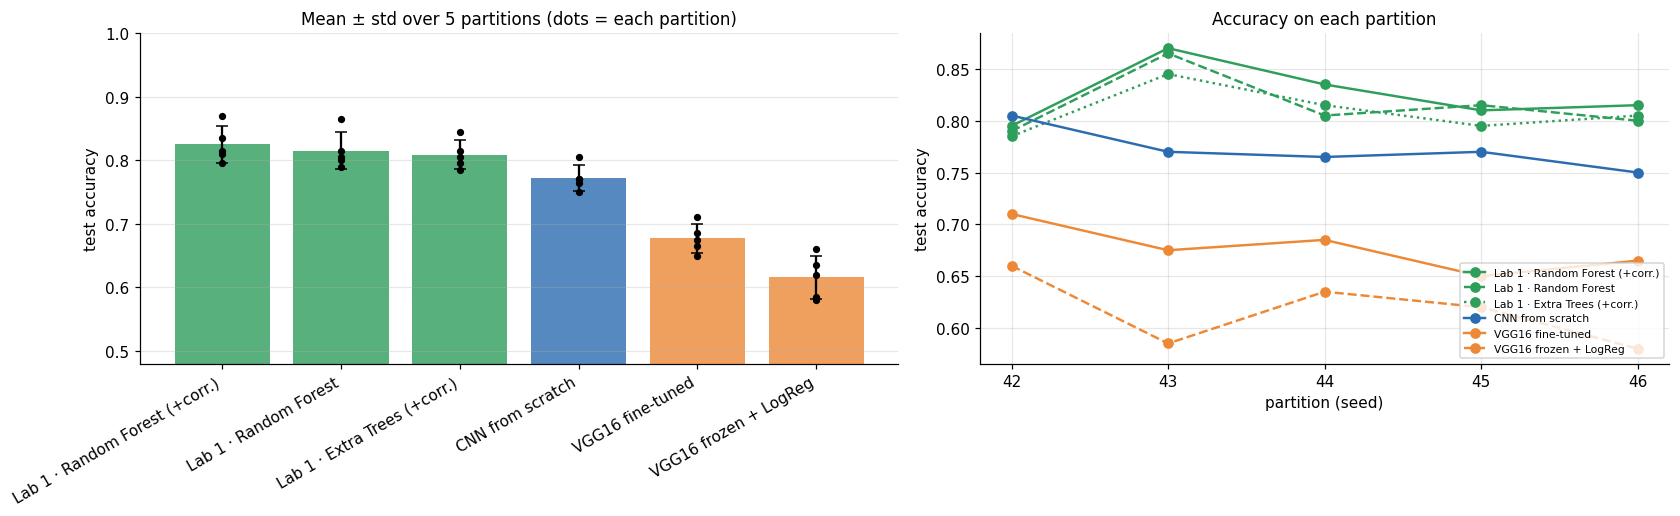

In [11]:
rows = []
for m in MULTI:
    accs = {s: correct(m, s).mean() for s in SEEDS_ALL}; f1s = [f1_score(P[m][s].y_true, P[m][s].y_pred, average="macro") for s in SEEDS_ALL]
    k, n = correct(m, PRIMARY).sum(), len(correct(m, PRIMARY)); lo, hi = wilson(k, n)
    rows.append(dict(model=m, approach=family(m), **{f"seed{s}": a for s, a in accs.items()}, mean_acc=np.mean(list(accs.values())), std_acc=np.std(list(accs.values()), ddof=1),
                     min_acc=min(accs.values()), max_acc=max(accs.values()), mean_f1=np.mean(f1s), acc_primary=accs[PRIMARY], wilson95_primary=f"[{lo:.3f}, {hi:.3f}]"))
main_tbl = pd.DataFrame(rows).sort_values("mean_acc", ascending=False).reset_index(drop=True)
main_tbl.to_csv(OUT / "table_main_multiseed.csv", index=False); display(main_tbl.round(3))
MODELS_MAIN = [m for m in main_tbl.model if PRIMARY in P[m]]

fig, axs = plt.subplots(1, 2, figsize=(15.5, 4.8), gridspec_kw=dict(width_ratios=[1.1, 1])); order = main_tbl.model.tolist(); ax = axs[0]
ax.bar(range(len(order)), main_tbl.mean_acc, yerr=main_tbl.std_acc, capsize=4, color=[color(m) for m in order], alpha=.8)
for i, m in enumerate(order): ax.scatter([i] * len(SEEDS_ALL), [correct(m, s).mean() for s in SEEDS_ALL], color="k", s=14, zorder=3)
ax.set_xticks(range(len(order))); ax.set_xticklabels([nice(m) for m in order], rotation=30, ha="right"); ax.set_ylabel("test accuracy")
ax.set_ylim(max(0, main_tbl.min_acc.min() - 0.1), 1); ax.grid(axis="y", alpha=.3); ax.set_title(f"Mean ± std over {len(SEEDS_ALL)} partitions (dots = each partition)")
ax = axs[1]; ls = {};
for m in order:
    st = ["-", "--", ":", "-."][ls.setdefault(family(m), []).__len__() % 4]; ls[family(m)].append(m)
    ax.plot(SEEDS_ALL, [correct(m, s).mean() for s in SEEDS_ALL], "o" + st, color=color(m), label=nice(m), lw=1.6)
ax.set_xticks(SEEDS_ALL); ax.set_xlabel("partition (seed)"); ax.set_ylabel("test accuracy"); ax.grid(alpha=.3); ax.set_title("Accuracy on each partition"); ax.legend(fontsize=7, loc="lower right")
plt.tight_layout(); savefig("q1_q5_accuracy_seeds.png"); plt.show()

### 7.2 Main partition: every model trained in the project on the same 200 songs
Bars show the accuracy with its Wilson 95 % interval; the dashed line is the best descriptor model. The *multi-partition* VGG16 (`VGG16 fine-tuned`) and the Task 2 search result (`VGG16 · last 2 blocks (T2)`) use the same configuration but different validation songs for early stopping and a different image-resizing implementation; the Task 2 figure is the best of 12 configurations chosen on 80 validation songs and is therefore optimistic.

,label,approach,acc,wilson_lo,wilson_hi,macro_f1,val_acc
0,VGGish frozen + SVM (T2),Pretrained audio,0.840,0.783,0.884,0.839,0.912
1,VGGish frozen + RF (T2),Pretrained audio,0.835,0.777,0.880,0.833,0.900
2,VGGish frozen + LogReg (T2),Pretrained audio,0.830,0.772,0.876,0.829,0.900
3,CNN from scratch (Task 1 run),CNN from scratch,0.825,0.766,0.871,0.825,NaN
4,CNN from scratch (multi-partition run),CNN from scratch,0.805,0.745,0.854,0.800,NaN
5,Lab 1 · Random Forest (+corr.),Hand-crafted descriptors,0.795,0.734,0.845,0.791,NaN
6,Lab 1 · Random Forest,Hand-crafted descriptors,0.790,0.728,0.841,0.789,NaN
7,Lab 1 · Extra Trees (+corr.),Hand-crafted descriptors,0.785,0.723,0.836,0.780,NaN
8,EfficientNetB0 · full (T2),Pretrained vision,0.765,0.702,0.818,0.768,0.775
9,VGG16 · last 2 blocks (T2),Pretrained vision,0.745,0.680,0.800,0.740,0.812


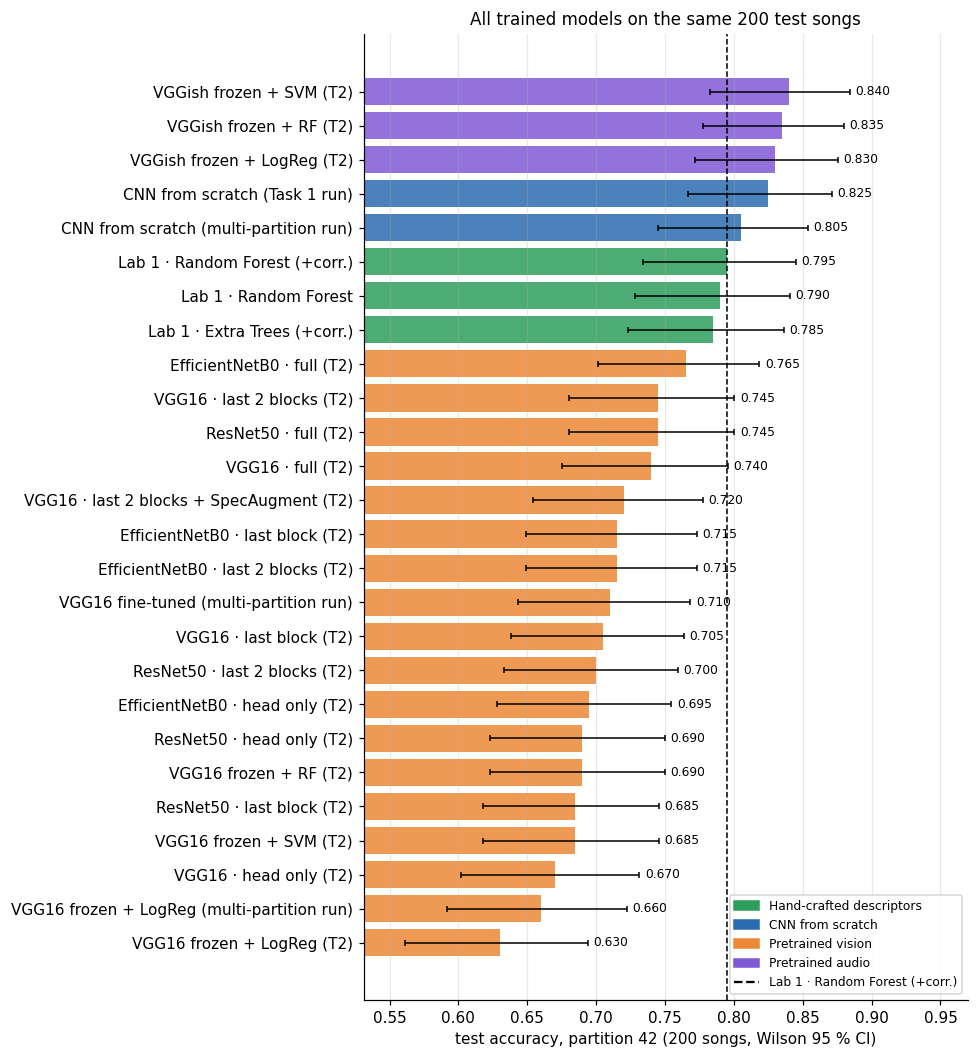

In [12]:
rows = []
for m in P42:
    c = correct42(m); k, n = int(c.sum()), len(c); lo, hi = wilson(k, n)
    lab_ = nice(m) + (" (multi-partition run)" if (m in MULTI and not m.startswith("lab1_")) else "")
    rows.append(dict(model=m, label=lab_, approach=family(m), acc=k / n, wilson_lo=lo, wilson_hi=hi, macro_f1=f1_score(P42[m].y_true, P42[m].y_pred, average="macro"),
                     val_acc=T2_RUNS.val_acc.get(m[3:], np.nan) if (m.startswith("t2_") and len(T2_RUNS)) else np.nan))
tbl42 = pd.DataFrame(rows).sort_values("acc", ascending=False).reset_index(drop=True); tbl42.to_csv(OUT / "table_all_models_primary.csv", index=False)
display(tbl42.drop(columns="model").round(3))

d = tbl42.iloc[::-1].reset_index(drop=True); fig, ax = plt.subplots(figsize=(9, 0.32 * len(d) + 1.4))
ax.barh(d.label, d.acc, xerr=[d.acc - d.wilson_lo, d.wilson_hi - d.acc], color=[FAM_COLORS[a] for a in d.approach], alpha=.85, capsize=2, error_kw=dict(lw=1, color="0.25"))
ax.axvline(correct42(LAB1_BEST).mean(), color="k", ls="--", lw=1, label=f"{nice(LAB1_BEST)}")
for i, r in d.iterrows(): ax.text(r.wilson_hi + 0.004, i, f"{r.acc:.3f}", va="center", fontsize=8)
ax.set_xlim(max(0.4, d.wilson_lo.min() - 0.03), 0.97); ax.set_xlabel(f"test accuracy, partition {PRIMARY} (200 songs, Wilson 95 % CI)"); ax.grid(axis="x", alpha=.3); ax.legend(loc="lower right", fontsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAM_COLORS.values()]; ax.legend(handles + [plt.Line2D([], [], color="k", ls="--")], list(FAM_COLORS) + [nice(LAB1_BEST)], loc="lower right", fontsize=8)
ax.set_title("All trained models on the same 200 test songs"); plt.tight_layout(); savefig("q1_all_models_primary.png"); plt.show()

### 7.3 Every model against the best descriptor model (exact McNemar, Holm-corrected)
For each model, the songs where only the reference or only the model is correct are counted; the test asks whether those two counts differ more than chance. With 200 songs, only differences of roughly 7–8 pp are significant on a single partition (see Section 8.4).

In [13]:
REF = LAB1_BEST; rows = []
for m in P42:
    if m == REF: continue
    n01, n10, p = mcnemar_exact(correct42(REF), correct42(m))
    rows.append(dict(model=m, label=nice(m) + (" (multi-partition run)" if (m in MULTI and not m.startswith("lab1_")) else ""), approach=family(m), acc=correct42(m).mean(), diff_vs_ref_pp=100 * (correct42(m).mean() - correct42(REF).mean()), only_ref_right=n01, only_model_right=n10, p_mcnemar=p))
vs_ref = pd.DataFrame(rows); vs_ref["p_holm"] = holm(vs_ref.p_mcnemar.to_numpy())
vs_ref["verdict"] = np.where(vs_ref.p_holm < .05, np.where(vs_ref.diff_vs_ref_pp > 0, "better than reference", "worse than reference"), "no significant difference")
vs_ref = vs_ref.sort_values("acc", ascending=False).reset_index(drop=True); vs_ref.to_csv(OUT / "table_vs_reference_primary.csv", index=False)
print(f"Reference: {nice(REF)} ({correct42(REF).mean():.3f} on partition {PRIMARY})"); display(vs_ref.drop(columns="model").round(4))
print(vs_ref.verdict.value_counts().to_string())

Reference: Lab 1 · Random Forest (+corr.) (0.795 on partition 42)


,label,approach,acc,diff_vs_ref_pp,only_ref_right,only_model_right,p_mcnemar,p_holm,verdict
0,VGGish frozen + SVM (T2),Pretrained audio,0.840,4.5,14,23,0.1877,1.0000,no significant difference
1,VGGish frozen + RF (T2),Pretrained audio,0.835,4.0,17,25,0.2800,1.0000,no significant difference
2,VGGish frozen + LogReg (T2),Pretrained audio,0.830,3.5,19,26,0.3713,1.0000,no significant difference
3,CNN from scratch (Task 1 run),CNN from scratch,0.825,3.0,15,21,0.4050,1.0000,no significant difference
4,CNN from scratch (multi-partition run),CNN from scratch,0.805,1.0,15,17,0.8601,1.0000,no significant difference
5,Lab 1 · Random Forest,Hand-crafted descriptors,0.790,-0.5,7,6,1.0000,1.0000,no significant difference
6,Lab 1 · Extra Trees (+corr.),Hand-crafted descriptors,0.785,-1.0,12,10,0.8318,1.0000,no significant difference
7,EfficientNetB0 · full (T2),Pretrained vision,0.765,-3.0,26,20,0.4614,1.0000,no significant difference
8,VGG16 · last 2 blocks (T2),Pretrained vision,0.745,-5.0,28,18,0.1839,1.0000,no significant difference
9,ResNet50 · full (T2),Pretrained vision,0.745,-5.0,27,17,0.1742,1.0000,no significant difference


verdict
no significant difference    23
worse than reference          2


### 7.4 Where do learned features help or hurt? Recall by genre
Per-genre recall of the CNN and of fine-tuned VGG16 minus that of the descriptor model, pooled over the five partitions (descriptive: a song can appear in several partitions, so these are not independent observations).

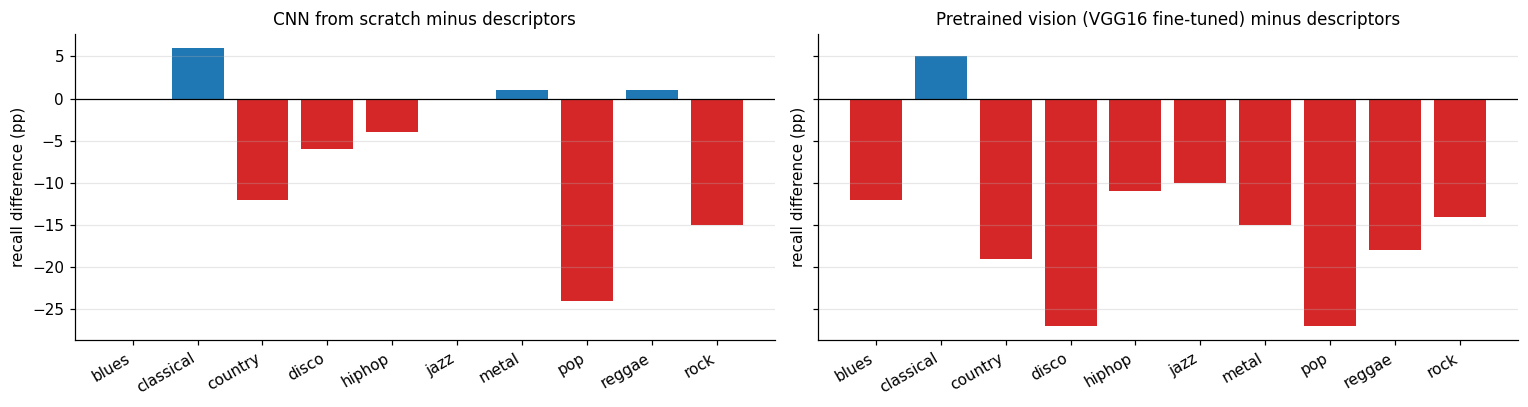

In [14]:
rec_lab = REPORTS["Descriptors (Lab 1)"]["per_class"].recall.iloc[:-1]
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, key in zip(axs, ["CNN from scratch", "Pretrained vision (VGG16 fine-tuned)"]):
    diff = 100 * (REPORTS[key]["per_class"].recall.iloc[:-1] - rec_lab)
    ax.bar(GENRES, diff, color=np.where(diff >= 0, "tab:blue", "tab:red")); ax.axhline(0, color="k", lw=.8); ax.grid(axis="y", alpha=.3)
    ax.set_title(f"{key} minus descriptors"); ax.set_ylabel("recall difference (pp)"); plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); savefig("q1_recall_difference_by_genre.png"); plt.show()

## 8. Q5 — How much does one 80/20 split tell you?

With 200 test songs, one song is 0.5 pp and the sampling standard error of an accuracy near 0.8 is about 2.8 pp. Repeating the split shows how much the result moves, and paired tests tell whether a difference between two models is larger than this noise.

- **Exact McNemar** (main partition): compares A and B on the *same* 200 songs; only songs where exactly one of them is right count. Corrected for multiple comparisons with **Holm**.
- **Corrected resampled t-test of Nadeau & Bengio** (five partitions): tests the mean accuracy difference while accounting for the overlap between training sets. With five partitions it has little power: *not significant* is not evidence of equivalence.

*Cautious rule for the report:* claim that A beats B only if McNemar (Holm) **and** the corrected t-test agree and A wins on most partitions.

### 8.1 How large is the spread across partitions compared with pure sampling noise?

,model,mean_acc,observed_sd,expected_sd_one_test_set,ratio,range_pp,best_partition,worst_partition
0,lab1_random_forest_correlation,0.825,0.029,0.027,1.077,7.5,43,42
1,lab1_random_forest_without_selection,0.815,0.029,0.027,1.070,7.5,43,42
2,lab1_extra_trees_correlation,0.809,0.023,0.028,0.828,6.0,43,42
3,cnn_scratch,0.772,0.020,0.030,0.680,5.5,42,46
4,vgg16_ft,0.677,0.023,0.033,0.681,6.0,42,45
5,vgg16_emb_logreg,0.616,0.034,0.034,0.983,8.0,42,46


ratio ≈ 1: the spread across partitions is about what the sampling noise of one 200-song test set alone would produce.


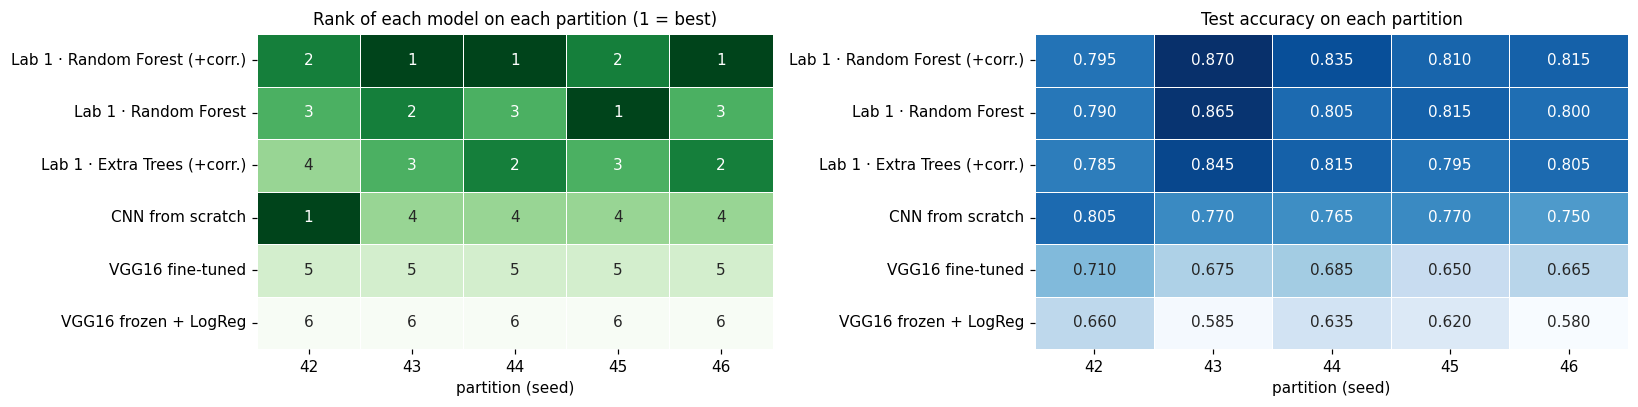

In [15]:
rows = []
for m in MULTI:
    a = np.array([correct(m, s).mean() for s in SEEDS_ALL]); p = a.mean(); n = len(correct(m, SEEDS_ALL[0])); se = np.sqrt(p * (1 - p) / n)
    rows.append(dict(model=m, mean_acc=p, observed_sd=a.std(ddof=1), expected_sd_one_test_set=se, ratio=a.std(ddof=1) / se, range_pp=100 * (a.max() - a.min()), best_partition=SEEDS_ALL[a.argmax()], worst_partition=SEEDS_ALL[a.argmin()]))
var_tbl = pd.DataFrame(rows).sort_values("mean_acc", ascending=False).reset_index(drop=True); var_tbl.to_csv(OUT / "table_variability.csv", index=False); display(var_tbl.round(3))
print("ratio ≈ 1: the spread across partitions is about what the sampling noise of one 200-song test set alone would produce.")

# rank of each model on every partition
acc_df = pd.DataFrame({nice(m): {s: correct(m, s).mean() for s in SEEDS_ALL} for m in MODELS_MAIN}).T[SEEDS_ALL]
rank_df = acc_df.rank(ascending=False, method="min").astype(int)
fig, axs = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw=dict(width_ratios=[1, 1.15]))
sns.heatmap(rank_df, annot=True, fmt="d", cmap="Greens_r", cbar=False, ax=axs[0], linewidths=.5); axs[0].set_title("Rank of each model on each partition (1 = best)"); axs[0].set_xlabel("partition (seed)")
sns.heatmap(acc_df, annot=True, fmt=".3f", cmap="Blues", cbar=False, ax=axs[1], linewidths=.5); axs[1].set_title("Test accuracy on each partition"); axs[1].set_xlabel("partition (seed)")
plt.tight_layout(); savefig("q5_ranks_by_partition.png"); plt.show()

### 8.2 Pairwise tests between the multi-partition models

,A,B,acc_A,acc_B,only_A_right,only_B_right,p_mcnemar_holm,mean_diff_seeds,seeds_A_wins,n_seeds,p_NB_holm,verdict
0,lab1_random_forest_correlation,lab1_random_forest_without_selection,0.795,0.790,7,6,1.0000,0.010,4,5,0.7075,no significant difference
1,lab1_random_forest_correlation,lab1_extra_trees_correlation,0.795,0.785,12,10,1.0000,0.016,5,5,0.1512,no significant difference
2,lab1_random_forest_correlation,cnn_scratch,0.795,0.805,15,17,1.0000,0.053,4,5,0.6371,no significant difference
3,lab1_random_forest_correlation,vgg16_ft,0.795,0.710,35,18,0.2701,0.148,5,5,0.0647,no significant difference
4,lab1_random_forest_correlation,vgg16_emb_logreg,0.795,0.660,44,17,0.0102,0.209,5,5,0.0647,partial evidence
5,lab1_random_forest_without_selection,lab1_extra_trees_correlation,0.790,0.785,11,10,1.0000,0.006,3,5,0.7075,no significant difference
6,lab1_random_forest_without_selection,cnn_scratch,0.790,0.805,15,18,1.0000,0.043,4,5,0.7075,no significant difference
7,lab1_random_forest_without_selection,vgg16_ft,0.790,0.710,36,20,0.3964,0.138,5,5,0.0656,no significant difference
8,lab1_random_forest_without_selection,vgg16_emb_logreg,0.790,0.660,44,18,0.0169,0.199,5,5,0.0647,partial evidence
9,lab1_extra_trees_correlation,cnn_scratch,0.785,0.805,18,22,1.0000,0.037,4,5,0.7075,no significant difference


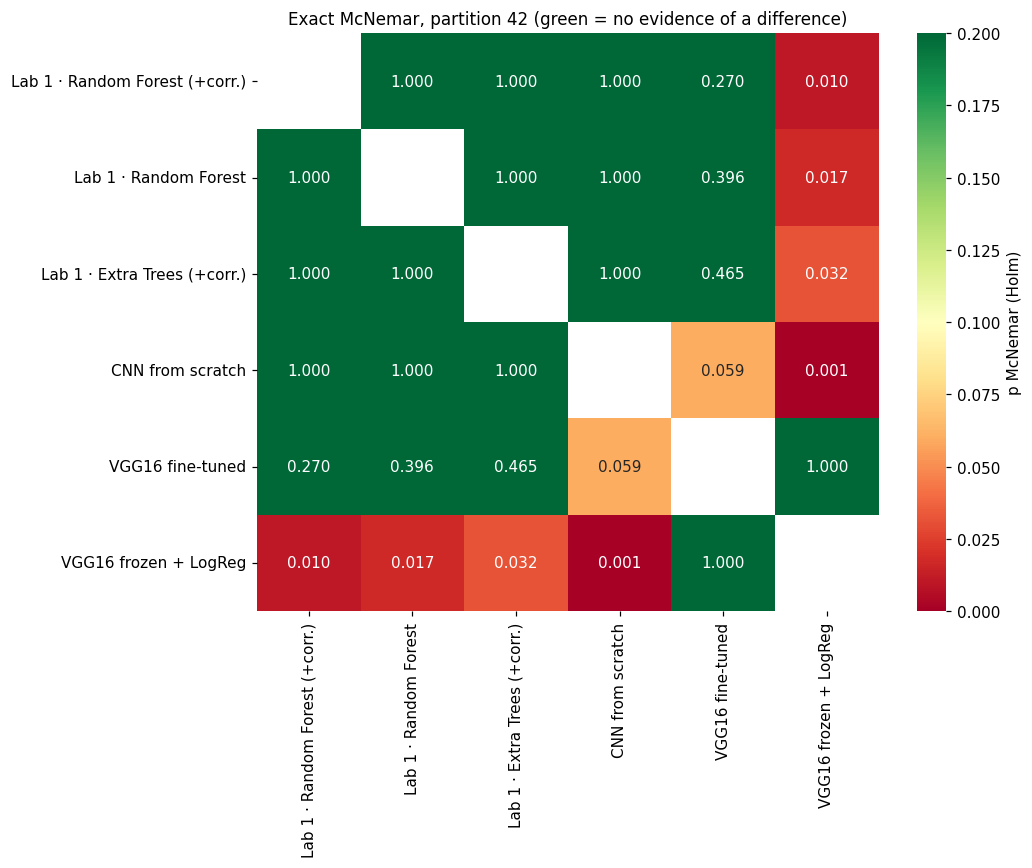

In [16]:
pw = pairwise(MODELS_MAIN); pw.to_csv(OUT / "table_pairwise_mcnemar.csv", index=False)
display(pw[["A", "B", "acc_A", "acc_B", "only_A_right", "only_B_right", "p_mcnemar_holm", "mean_diff_seeds", "seeds_A_wins", "n_seeds", "p_NB_holm", "verdict"]].round(4))

M = pd.DataFrame(np.nan, index=MODELS_MAIN, columns=MODELS_MAIN)
for _, r in pw.iterrows(): M.loc[r.A, r.B] = M.loc[r.B, r.A] = r.p_mcnemar_holm
plt.figure(figsize=(1.1 * len(M) + 3, 1.0 * len(M) + 2))
sns.heatmap(M.rename(index=nice, columns=nice), annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=0.2, cbar_kws={"label": "p McNemar (Holm)"})
plt.title(f"Exact McNemar, partition {PRIMARY} (green = no evidence of a difference)"); plt.tight_layout(); savefig("q5_mcnemar_heatmap.png"); plt.show()

### 8.3 Paired differences partition by partition

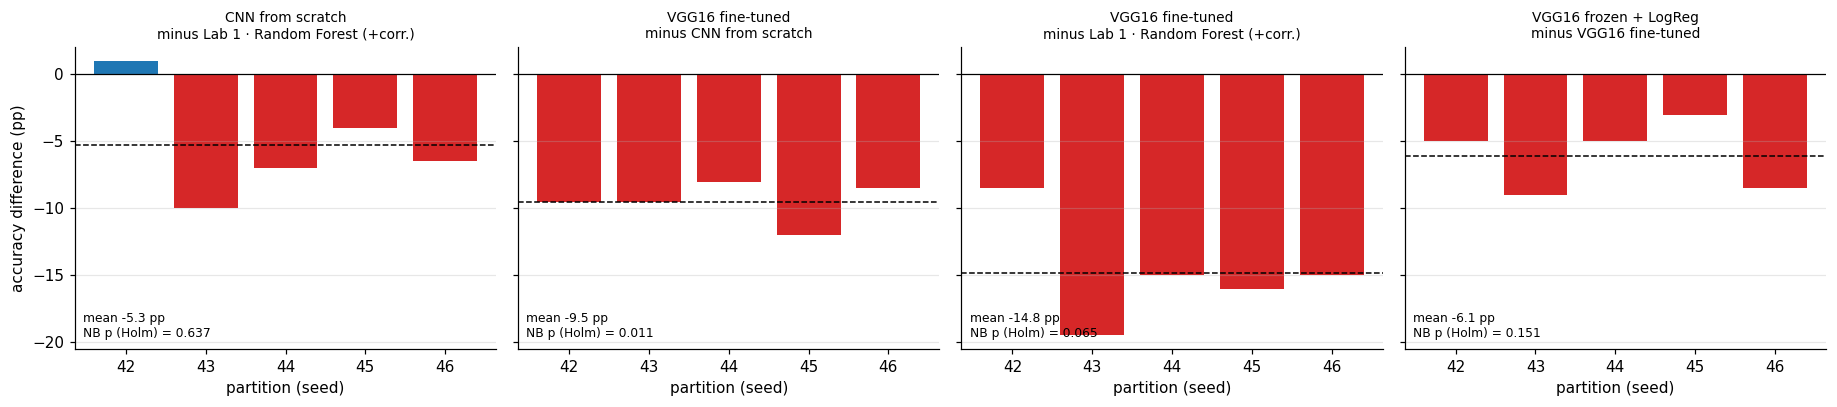

In [17]:
KP = [(CNN, LAB1_BEST), (VGG_FT, CNN), (VGG_FT, LAB1_BEST), ("vgg16_emb_logreg", VGG_FT)]; KP = [(a, b) for a, b in KP if a in MODELS_MAIN and b in MODELS_MAIN]
fig, axs = plt.subplots(1, len(KP), figsize=(4.2 * len(KP), 3.8), sharey=True)
for ax, (a, b) in zip(np.atleast_1d(axs), KP):
    d = 100 * np.array([correct(a, s).mean() - correct(b, s).mean() for s in SEEDS_ALL]); r = pw[((pw.A == a) & (pw.B == b)) | ((pw.A == b) & (pw.B == a))].iloc[0]
    ax.bar([str(s) for s in SEEDS_ALL], d, color=np.where(d >= 0, "tab:blue", "tab:red")); ax.axhline(0, color="k", lw=.8); ax.axhline(d.mean(), color="k", ls="--", lw=1); ax.grid(axis="y", alpha=.3)
    ax.set_title(f"{nice(a)}\nminus {nice(b)}", fontsize=9); ax.set_xlabel("partition (seed)"); ax.text(0.02, 0.03, f"mean {d.mean():+.1f} pp\nNB p (Holm) = {r.p_NB_holm:.3f}", transform=ax.transAxes, fontsize=8, va="bottom")
np.atleast_1d(axs)[0].set_ylabel("accuracy difference (pp)"); plt.tight_layout(); savefig("q5_paired_differences.png"); plt.show()

### 8.4 What difference can one 200-song test set detect?
For a given number of songs on which the two models disagree (*discordant* songs), the table gives the smallest net advantage (songs where only A is right minus songs where only B is right) that is significant with an exact McNemar test at the 5 % level, before any multiple-comparison correction.

In [18]:
rows = []
for nd in (10, 20, 30, 40, 50, 60):
    k = next(k for k in range(nd // 2, nd + 1) if stats.binomtest(nd - k, nd, 0.5).pvalue < .05)       # k songs for the winner, nd-k for the loser
    rows.append(dict(discordant_songs=nd, min_net_advantage_songs=2 * k - nd, min_difference_pp=100 * (2 * k - nd) / 200, winner_songs=k, loser_songs=nd - k))
det = pd.DataFrame(rows); det.to_csv(OUT / "table_detectable_difference.csv", index=False); display(det.round(2))
disc = pw[["only_A_right", "only_B_right"]].sum(1); print(f"In this project, two different models disagree on {disc.min()}–{disc.max()} of the 200 songs (median {disc.median():.0f}).")

,discordant_songs,min_net_advantage_songs,min_difference_pp,winner_songs,loser_songs
0,10,8,4.0,9,1
1,20,10,5.0,15,5
2,30,12,6.0,21,9
3,40,14,7.0,27,13
4,50,16,8.0,33,17
5,60,18,9.0,39,21


In this project, two different models disagree on 13–65 of the 200 songs (median 43).


### 8.5 Q1 — evidence summary

In [19]:
def verdict_row(a, b):
    r = pw[((pw.A == a) & (pw.B == b)) | ((pw.A == b) & (pw.B == a))].iloc[0]; flip = r.A != a
    return dict(A=a, B=b, accA=r.acc_B if flip else r.acc_A, accB=r.acc_A if flip else r.acc_B, only_A=r.only_B_right if flip else r.only_A_right, only_B=r.only_A_right if flip else r.only_B_right,
                p_mcn=r.p_mcnemar_holm, mean_diff=-r.mean_diff_seeds if flip else r.mean_diff_seeds, wins=(r.n_seeds - r.seeds_A_wins) if flip else r.seeds_A_wins, n_seeds=r.n_seeds, p_nb=r.p_NB_holm, verdict=r.verdict)
q1 = pd.DataFrame([verdict_row(a, b) for a, b in [(CNN, LAB1_BEST), (VGG_FT, LAB1_BEST), (VGG_FT, CNN)] if a in MODELS_MAIN and b in MODELS_MAIN])
display(q1.round(4))
for _, r in q1.iterrows():
    print(f"{nice(r.A)} vs {nice(r.B)}: {r.accA:.3f} vs {r.accB:.3f} on partition {PRIMARY}; mean difference over {r.n_seeds} partitions {100 * r.mean_diff:+.1f} pp, "
          f"{nice(r.A)} wins {r.wins}/{r.n_seeds}; McNemar (Holm) p = {r.p_mcn:.3f} (only {nice(r.A)} right: {r.only_A}, only {nice(r.B)} right: {r.only_B}); Nadeau-Bengio (Holm) p = {r.p_nb:.3f} -> {r.verdict}")
KEY["q1_q5"] = dict(main_table=main_tbl[["model", "mean_acc", "std_acc", "min_acc", "max_acc", "mean_f1"]].round(4).to_dict("records"), paired=q1.round(4).to_dict("records"),
                    sd_ratio=var_tbl[["model", "observed_sd", "expected_sd_one_test_set"]].round(4).to_dict("records"))

,A,B,accA,accB,only_A,only_B,p_mcn,mean_diff,wins,n_seeds,p_nb,verdict
0,cnn_scratch,lab1_random_forest_correlation,0.805,0.795,17,15,1.0000,-0.053,1,5,0.6371,no significant difference
1,vgg16_ft,lab1_random_forest_correlation,0.710,0.795,18,35,0.2701,-0.148,0,5,0.0647,no significant difference
2,vgg16_ft,cnn_scratch,0.710,0.805,12,31,0.0594,-0.095,0,5,0.0109,partial evidence


CNN from scratch vs Lab 1 · Random Forest (+corr.): 0.805 vs 0.795 on partition 42; mean difference over 5 partitions -5.3 pp, CNN from scratch wins 1/5; McNemar (Holm) p = 1.000 (only CNN from scratch right: 17, only Lab 1 · Random Forest (+corr.) right: 15); Nadeau-Bengio (Holm) p = 0.637 -> no significant difference
VGG16 fine-tuned vs Lab 1 · Random Forest (+corr.): 0.710 vs 0.795 on partition 42; mean difference over 5 partitions -14.8 pp, VGG16 fine-tuned wins 0/5; McNemar (Holm) p = 0.270 (only VGG16 fine-tuned right: 18, only Lab 1 · Random Forest (+corr.) right: 35); Nadeau-Bengio (Holm) p = 0.065 -> no significant difference
VGG16 fine-tuned vs CNN from scratch: 0.710 vs 0.805 on partition 42; mean difference over 5 partitions -9.5 pp, VGG16 fine-tuned wins 0/5; McNemar (Holm) p = 0.059 (only VGG16 fine-tuned right: 12, only CNN from scratch right: 31); Nadeau-Bengio (Holm) p = 0.011 -> partial evidence


## 9. Q2 — Do CNNs and descriptor models make the same mistakes?

If two models fail on the same songs, those songs are intrinsically hard (ambiguous genre, atypical clip, mislabelled) and combining the models cannot help much; if they fail on different songs, they carry complementary information (Section 10). Four angles:

1. **Error overlap** — how many songs both models get wrong, compared with the overlap expected if errors were independent, and the correlation between the error indicators (φ).
2. **How many approaches fail on each song** — observed distribution against the one expected under independence.
3. **Genre-confusion structure** — are the same *pairs of genres* confused by the descriptors and by the CNN, or is part of the structure an effect of the descriptors?
4. **Songs that every approach fails.**

### 9.1 Error overlap between models (average over the partitions)

,wrong_A,wrong_B,both_wrong,only_A_wrong,only_B_wrong,expected_both_if_independent,jaccard,overlap_of_smaller,oracle_acc,phi
Lab 1 · Random Forest (+corr.) vs Lab 1 · Random Forest,35.0,37.0,31.2,3.8,5.8,6.597,0.766,0.898,0.844,0.839
Lab 1 · Random Forest (+corr.) vs Lab 1 · Extra Trees (+corr.),35.0,38.2,27.0,8.0,11.2,6.791,0.585,0.774,0.865,0.680
Lab 1 · Random Forest (+corr.) vs CNN from scratch,35.0,45.6,20.4,14.6,25.2,7.944,0.342,0.593,0.898,0.394
Lab 1 · Random Forest (+corr.) vs VGG16 fine-tuned,35.0,64.6,22.0,13.0,42.6,11.286,0.283,0.638,0.890,0.305
Lab 1 · Random Forest (+corr.) vs VGG16 frozen + LogReg,35.0,76.8,24.4,10.6,52.4,13.351,0.279,0.706,0.878,0.301
Lab 1 · Random Forest vs Lab 1 · Extra Trees (+corr.),37.0,38.2,26.8,10.2,11.4,7.163,0.552,0.736,0.866,0.645
Lab 1 · Random Forest vs CNN from scratch,37.0,45.6,20.6,16.4,25.0,8.415,0.336,0.573,0.897,0.379
Lab 1 · Random Forest vs VGG16 fine-tuned,37.0,64.6,22.8,14.2,41.8,11.918,0.289,0.626,0.886,0.303
Lab 1 · Random Forest vs VGG16 frozen + LogReg,37.0,76.8,25.6,11.4,51.2,14.116,0.290,0.697,0.872,0.305
Lab 1 · Extra Trees (+corr.) vs CNN from scratch,38.2,45.6,21.6,16.6,24.0,8.678,0.347,0.580,0.892,0.394


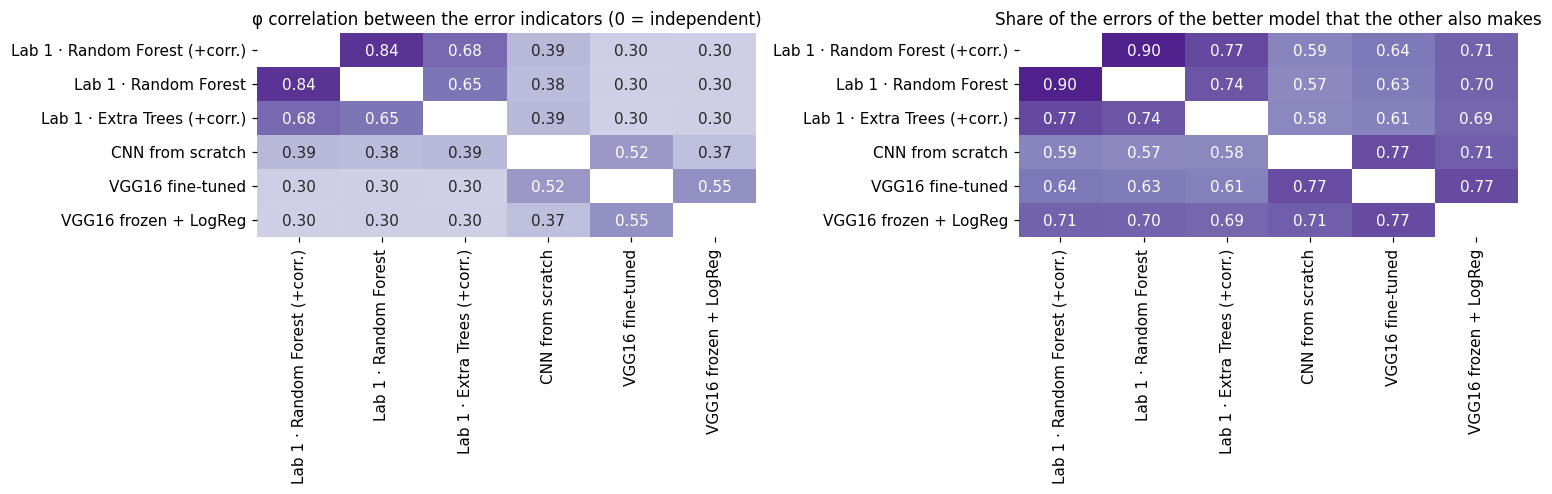

In [20]:
def error_overlap(a, b, seeds):
    r = []
    for s in seeds:
        wa, wb = ~correct(a, s), ~correct(b, s); n = len(wa); both = int((wa & wb).sum())
        r.append(dict(wrong_A=wa.sum(), wrong_B=wb.sum(), both_wrong=both, only_A_wrong=int((wa & ~wb).sum()), only_B_wrong=int((~wa & wb).sum()), expected_both_if_independent=wa.sum() * wb.sum() / n,
                      jaccard=both / max(1, (wa | wb).sum()), overlap_of_smaller=both / max(1, min(wa.sum(), wb.sum())), oracle_acc=1 - both / n,
                      phi=np.corrcoef(wa, wb)[0, 1] if wa.std() > 0 and wb.std() > 0 else np.nan))
    return pd.DataFrame(r).mean()

ov = pd.DataFrame({f"{nice(a)} vs {nice(b)}": error_overlap(a, b, SEEDS_ALL) for a, b in itertools.combinations(MODELS_MAIN, 2)}).T
ov.to_csv(OUT / "table_error_overlap.csv"); display(ov.round(3))

PHI = pd.DataFrame(np.nan, index=MODELS_MAIN, columns=MODELS_MAIN); OVS = PHI.copy()
for a, b in itertools.combinations(MODELS_MAIN, 2):
    e = error_overlap(a, b, SEEDS_ALL); PHI.loc[a, b] = PHI.loc[b, a] = e.phi; OVS.loc[a, b] = OVS.loc[b, a] = e.overlap_of_smaller
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
sns.heatmap(PHI.rename(index=nice, columns=nice), annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, ax=axs[0], cbar=False); axs[0].set_title("φ correlation between the error indicators (0 = independent)")
sns.heatmap(OVS.rename(index=nice, columns=nice), annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, ax=axs[1], cbar=False); axs[1].set_title("Share of the errors of the better model that the other also makes")
plt.tight_layout(); savefig("q2_error_overlap.png"); plt.show()

### 9.2 Per-partition agreement of the three approaches

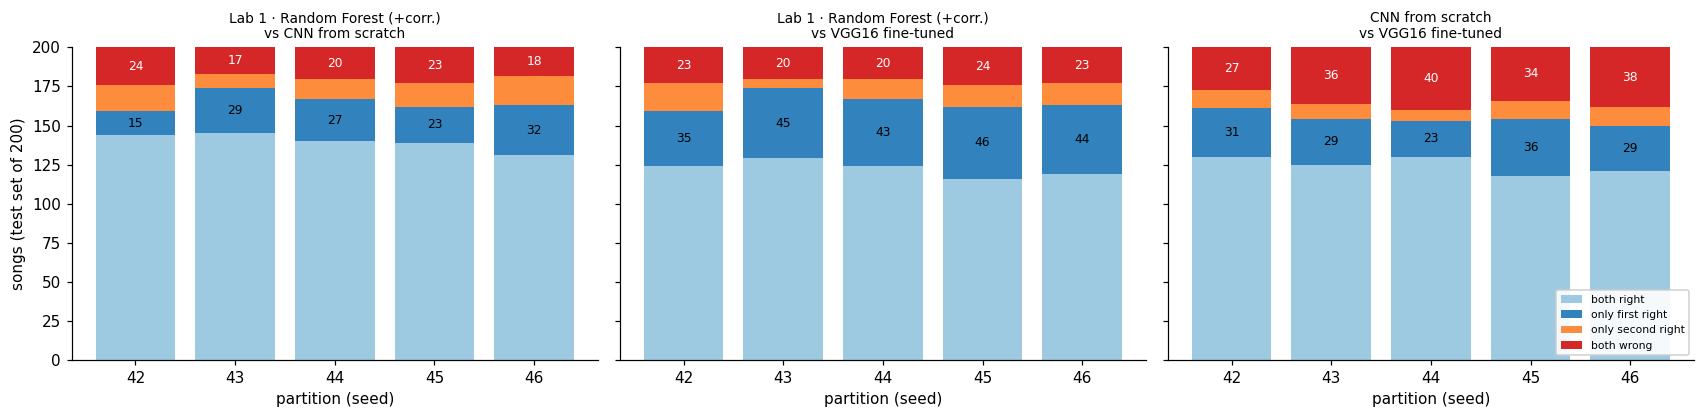

In [21]:
REPS = [m for m in (LAB1_BEST, CNN, VGG_FT, "vgg16_emb_logreg") if m in MODELS_MAIN]       # one representative per approach (+ frozen VGG16)
PAIRS = [(a, b) for a, b in itertools.combinations(REPS[:3], 2)]
fig, axs = plt.subplots(1, len(PAIRS), figsize=(5.2 * len(PAIRS), 3.9), sharey=True); cats = ["both right", "only first right", "only second right", "both wrong"]; cc = ["#9ecae1", "#3182bd", "#fd8d3c", "#d62728"]
for ax, (a, b) in zip(np.atleast_1d(axs), PAIRS):
    cnt = np.array([[(correct(a, s) & correct(b, s)).sum(), (correct(a, s) & ~correct(b, s)).sum(), (~correct(a, s) & correct(b, s)).sum(), (~correct(a, s) & ~correct(b, s)).sum()] for s in SEEDS_ALL]); bottom = np.zeros(len(SEEDS_ALL))
    for j in range(4): ax.bar([str(s) for s in SEEDS_ALL], cnt[:, j], bottom=bottom, color=cc[j], label=cats[j]); bottom += cnt[:, j]
    for i in range(len(SEEDS_ALL)):
        ax.text(i, cnt[i, :3].sum() + cnt[i, 3] / 2, str(cnt[i, 3]), ha="center", va="center", fontsize=8, color="w"); ax.text(i, cnt[i, 0] + cnt[i, 1] / 2, str(cnt[i, 1]), ha="center", va="center", fontsize=8)
    ax.set_title(f"{nice(a)}\nvs {nice(b)}", fontsize=9); ax.set_xlabel("partition (seed)"); ax.set_ylim(0, 200)
np.atleast_1d(axs)[0].set_ylabel("songs (test set of 200)"); np.atleast_1d(axs)[-1].legend(fontsize=7, loc="lower right", framealpha=.9)
plt.tight_layout(); savefig("q2_pair_agreement.png"); plt.show()

### 9.3 How many approaches fail on each song?
For each test song, how many of the representative models get it wrong, compared with what would be expected if the errors of the models were **independent** (Poisson-binomial distribution with each model's own error rate). Excess mass at 0 and at the maximum means that difficulty is a property of the song.

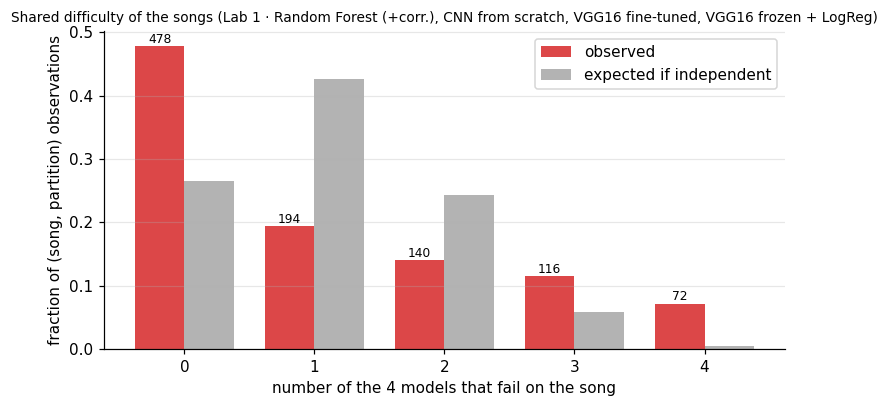

songs failed by all 4 models: observed 72 vs 5 expected under independence | failed by none: observed 478 vs 266


In [22]:
K = len(REPS); obs = np.zeros(K + 1); exp = np.zeros(K + 1)
for s in SEEDS_ALL:
    nw = np.sum([~correct(m, s) for m in REPS], axis=0); obs += np.bincount(nw, minlength=K + 1)
    dist = np.array([1.0])
    for m in REPS: q = (~correct(m, s)).mean(); dist = np.convolve(dist, [1 - q, q])
    exp += dist * len(nw)
fig, ax = plt.subplots(figsize=(7, 3.8)); w = 0.38; xs = np.arange(K + 1)
ax.bar(xs - w / 2, obs / obs.sum(), w, label="observed", color="tab:red", alpha=.85); ax.bar(xs + w / 2, exp / exp.sum(), w, label="expected if independent", color="0.7")
for i in xs: ax.text(i - w / 2, obs[i] / obs.sum() + .005, f"{int(obs[i])}", ha="center", fontsize=8)
ax.set_xticks(xs); ax.set_xlabel(f"number of the {K} models that fail on the song"); ax.set_ylabel("fraction of (song, partition) observations"); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title(f"Shared difficulty of the songs ({', '.join(nice(m) for m in REPS)})", fontsize=9); plt.tight_layout(); savefig("q2_songs_failed_by_k_models.png"); plt.show()
print(f"songs failed by all {K} models: observed {int(obs[K])} vs {exp[K]:.0f} expected under independence | failed by none: observed {int(obs[0])} vs {exp[0]:.0f}")
KEY["q2_all_fail"] = dict(models=REPS, observed_all_fail=int(obs[K]), expected_all_fail=float(exp[K]), observed_none_fail=int(obs[0]), expected_none_fail=float(exp[0]))

### 9.4 Is the genre-similarity structure the same for descriptors and for the CNN?
For each model, the confusion matrices of the five partitions are summed, row-normalised and symmetrised (`(R + Rᵀ)/2`), giving a *similarity* between every pair of genres (how often one is taken for the other). The Spearman correlation between these similarities tells whether the **same pairs** of genres are confused by the different approaches; where they differ, the confusion is partly an effect of the representation (descriptors vs spectrograms).

Spearman correlation between the genre-confusion structures (1 = the same pairs of genres are confused):


,Lab 1 · Random Forest (+corr.),CNN from scratch,VGG16 fine-tuned,VGG16 frozen + LogReg
Lab 1 · Random Forest (+corr.),1.00,0.50,0.53,0.56
CNN from scratch,0.50,1.00,0.75,0.63
VGG16 fine-tuned,0.53,0.75,1.00,0.90
VGG16 frozen + LogReg,0.56,0.63,0.90,1.00


The 6 most confused genre pairs of each model (similarity in brackets):


,Lab 1 · Random Forest (+corr.),CNN from scratch,VGG16 fine-tuned,VGG16 frozen + LogReg
#1,classical–jazz (0.08),country–rock (0.12),country–rock (0.17),country–rock (0.18)
#2,pop–reggae (0.08),hiphop–pop (0.10),pop–rock (0.11),hiphop–reggae (0.11)
#3,country–rock (0.07),disco–pop (0.08),hiphop–reggae (0.10),disco–reggae (0.09)
#4,disco–rock (0.07),blues–country (0.07),disco–reggae (0.08),disco–hiphop (0.09)
#5,blues–country (0.06),pop–rock (0.07),hiphop–pop (0.08),metal–rock (0.08)
#6,country–disco (0.05),blues–reggae (0.06),metal–rock (0.07),disco–rock (0.08)


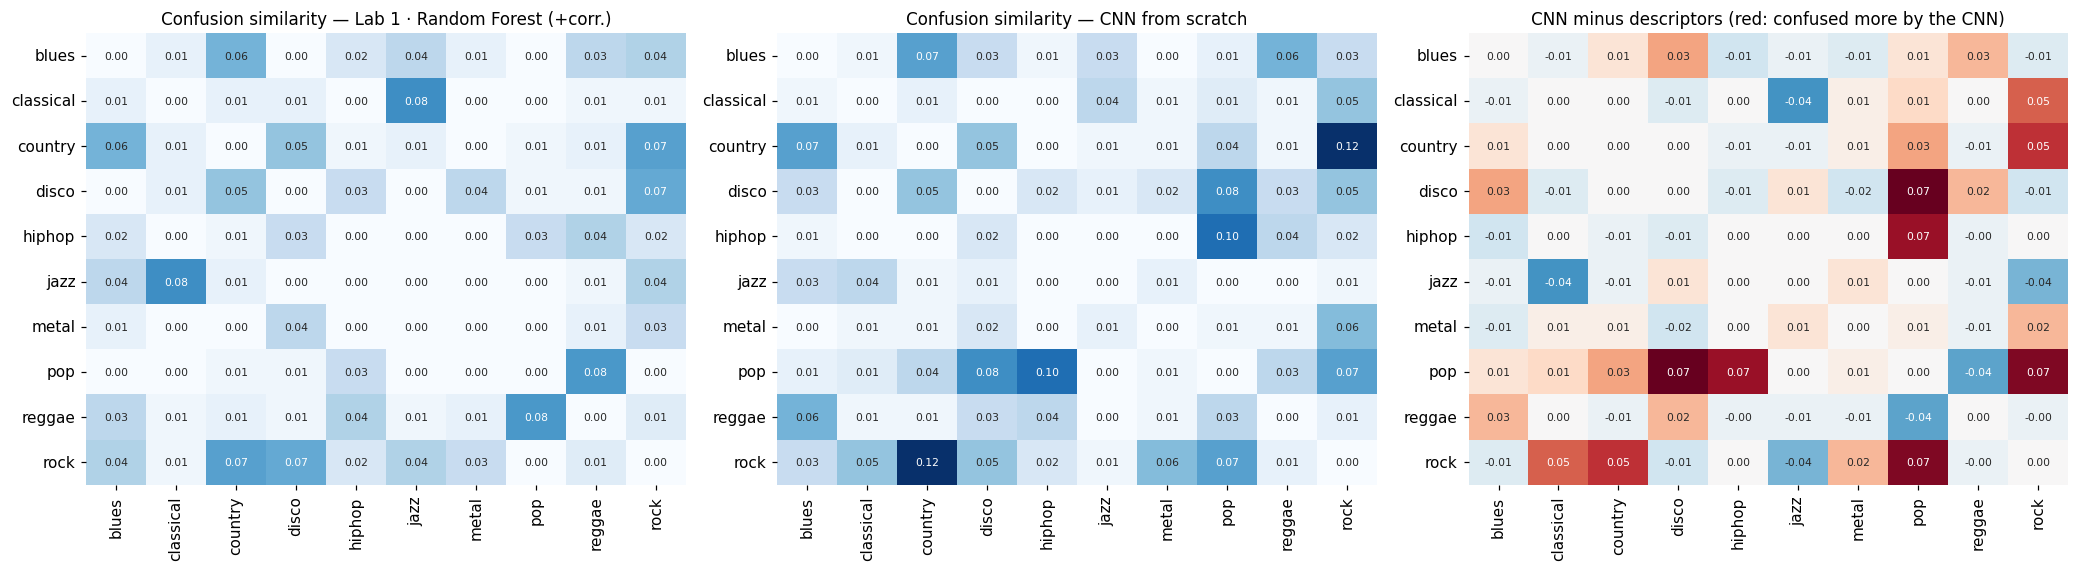

Pairs confused MORE by the descriptors than by the CNN:


,pair,Lab 1 · Random Forest (+corr.),CNN from scratch,CNN − descriptors
0,classical–jazz,0.080,0.035,-0.045
1,pop–reggae,0.075,0.035,-0.040
2,jazz–rock,0.040,0.005,-0.035
3,disco–metal,0.035,0.020,-0.015
4,disco–rock,0.065,0.050,-0.015


Pairs confused MORE by the CNN than by the descriptors:


,pair,Lab 1 · Random Forest (+corr.),CNN from scratch,CNN − descriptors
0,disco–pop,0.005,0.080,0.075
1,pop–rock,0.000,0.070,0.070
2,hiphop–pop,0.030,0.095,0.065
3,country–rock,0.070,0.125,0.055
4,classical–rock,0.005,0.050,0.045


In [23]:
SHOW = REPS; CM = {m: sum(confusion_matrix(P[m][s].y_true, P[m][s].y_pred, labels=range(len(GENRES))) for s in SEEDS_ALL) for m in MODELS_MAIN}
iu = np.triu_indices(len(GENRES), 1)
def sim_matrix(C): R = C / C.sum(1, keepdims=True); S = (R + R.T) / 2; np.fill_diagonal(S, 0); return S
SIM = {m: sim_matrix(CM[m]) for m in MODELS_MAIN}
corr = pd.DataFrame({a: {b: stats.spearmanr(SIM[a][iu], SIM[b][iu])[0] for b in SHOW} for a in SHOW}).rename(index=nice, columns=nice)
print("Spearman correlation between the genre-confusion structures (1 = the same pairs of genres are confused):"); display(corr.round(2)); corr.round(3).to_csv(OUT / "table_confusion_structure_corr.csv")

pairs = [(GENRES[i], GENRES[j]) for i, j in zip(*iu)]
top = pd.DataFrame({nice(m): [f"{pairs[k][0]}–{pairs[k][1]} ({SIM[m][iu][k]:.2f})" for k in np.argsort(-SIM[m][iu])[:6]] for m in SHOW}, index=[f"#{i+1}" for i in range(6)])
print("The 6 most confused genre pairs of each model (similarity in brackets):"); display(top)

a, b = LAB1_BEST, CNN; vmax = max(SIM[a].max(), SIM[b].max()); fig, axs = plt.subplots(1, 3, figsize=(19, 5.3))
for ax, m in zip(axs[:2], (a, b)): sns.heatmap(SIM[m], annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=vmax, xticklabels=GENRES, yticklabels=GENRES, cbar=False, ax=ax, annot_kws=dict(size=7)); ax.set_title(f"Confusion similarity — {nice(m)}")
dif = SIM[b] - SIM[a]; lim = np.abs(dif).max()
sns.heatmap(dif, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-lim, vmax=lim, xticklabels=GENRES, yticklabels=GENRES, cbar=False, ax=axs[2], annot_kws=dict(size=7)); axs[2].set_title("CNN minus descriptors (red: confused more by the CNN)")
plt.tight_layout(); savefig("q2_confusion_structure.png"); plt.show()

dd = pd.DataFrame({"pair": [f"{p[0]}–{p[1]}" for p in pairs], nice(a): SIM[a][iu], nice(b): SIM[b][iu]}); dd["CNN − descriptors"] = dd[nice(b)] - dd[nice(a)]
print("Pairs confused MORE by the descriptors than by the CNN:"); display(dd.sort_values("CNN − descriptors").head(5).round(3).reset_index(drop=True))
print("Pairs confused MORE by the CNN than by the descriptors:"); display(dd.sort_values("CNN − descriptors", ascending=False).head(5).round(3).reset_index(drop=True))
KEY["q2_structure"] = dict(spearman=corr.round(3).to_dict())

### 9.5 Songs that every approach fails (main partition)

In [24]:
allwrong = np.logical_and.reduce([~correct42(m) for m in REPS]); sp = P42[REPS[0]]
tab = pd.DataFrame({"song": sp.song[allwrong].to_numpy(), "true": [GENRES[i] for i in sp.y_true[allwrong]], **{nice(m): [GENRES[i] for i in P42[m].y_pred[allwrong]] for m in REPS}})
print(f"{allwrong.sum()} songs failed by all {len(REPS)} models ({allwrong.mean():.1%}) on partition {PRIMARY}:"); display(tab)

15 songs failed by all 4 models (7.5%) on partition 42:


,song,true,Lab 1 · Random Forest (+corr.),CNN from scratch,VGG16 fine-tuned,VGG16 frozen + LogReg
0,blues.00057,blues,hiphop,reggae,reggae,hiphop
1,blues.00074,blues,country,disco,jazz,jazz
2,blues.00075,blues,hiphop,disco,disco,disco
3,blues.00095,blues,country,country,country,country
4,country.00015,country,rock,blues,rock,rock
5,disco.00027,disco,hiphop,hiphop,reggae,hiphop
6,disco.00047,disco,classical,jazz,jazz,jazz
7,disco.00063,disco,hiphop,hiphop,reggae,hiphop
8,hiphop.00000,hiphop,disco,disco,disco,disco
9,reggae.00086,reggae,pop,metal,rock,rock


## 10. Q3 — Are the two approaches complementary?

If the models make different mistakes (Section 9), combining their predictions should beat the best single model. The class probabilities of the models are **averaged** (soft voting) for every subset of the representative models, always on the same partitions and test songs as in Section 8, and each ensemble is compared with its best member. The *oracle* accuracy (at least one member is right) is the ceiling of any combination.

**Why two weightings.** The probabilities of the models live on different scales (Section 6): a Random Forest outputs vote fractions (mean top-1 probability about 0.5), whereas the networks output softmax probabilities (about 0.8). A plain average is therefore dominated by the networks, whatever their quality.

- **Raw average:** equal weights on the stored probabilities.
- **Confidence-matched average:** each model's probabilities are first transformed as `p^α` (renormalised) with α chosen, for every model and partition, so that its **mean top-1 probability equals a common value** `C_STAR`. This uses only the model's own predictions on the test songs — **no labels and no tuning on the test accuracy** — and Section 10.2 shows that the result hardly depends on `C_STAR`.

Holm's correction is applied across **all** the ensembles and both weightings of the table (22 tests); the uncorrected p-values (`p_mcnemar_vs_best`, `p_nadeau_bengio`) are in the same table, and the sample-size caveats of Section 8 apply (with five partitions the corrected t-test has little power).

,ensemble,weighting,n_models,mean_acc,std_acc,best_member_mean_acc,gain_vs_best_pp,seeds_ensemble_wins,only_ens_right,only_best_right,p_mcnemar_vs_best,p_nadeau_bengio,oracle_acc,p_mcnemar_holm,p_NB_holm
0,Lab 1 + CNN,confidence-matched,2,0.854,0.0182,0.825,2.9,5,18,4,0.0043,0.1537,0.898,0.0956,1.0000
1,Lab 1 + CNN + VGG16-ft,confidence-matched,3,0.839,0.0216,0.825,1.4,3,18,6,0.0227,0.5177,0.914,0.4531,1.0000
2,Lab 1 + CNN + VGG16-frozen,confidence-matched,3,0.826,0.0340,0.825,0.1,2,21,9,0.0428,0.9726,0.919,0.8127,1.0000
3,Lab 1 + VGG16-ft,confidence-matched,2,0.819,0.0171,0.825,-0.6,2,16,10,0.3269,0.7611,0.890,1.0000,1.0000
4,Lab 1 + CNN + VGG16-ft + VGG16-frozen,confidence-matched,4,0.803,0.0356,0.825,-2.2,1,20,11,0.1496,0.4688,0.928,1.0000,1.0000
5,Lab 1 + VGG16-ft + VGG16-frozen,confidence-matched,3,0.782,0.0233,0.825,-4.3,1,16,14,0.8555,0.1168,0.906,1.0000,1.0000
6,Lab 1 + VGG16-frozen,confidence-matched,2,0.780,0.0184,0.825,-4.5,0,14,15,1.0000,0.0444,0.878,1.0000,0.8882
7,CNN + VGG16-ft,confidence-matched,2,0.768,0.0236,0.772,-0.4,1,9,10,1.0000,0.4664,0.825,1.0000,1.0000
8,CNN + VGG16-ft + VGG16-frozen,confidence-matched,3,0.766,0.0288,0.772,-0.6,1,12,13,1.0000,0.5543,0.857,1.0000,1.0000
9,CNN + VGG16-frozen,confidence-matched,2,0.765,0.0398,0.772,-0.7,1,12,8,0.5034,0.6325,0.837,1.0000,1.0000


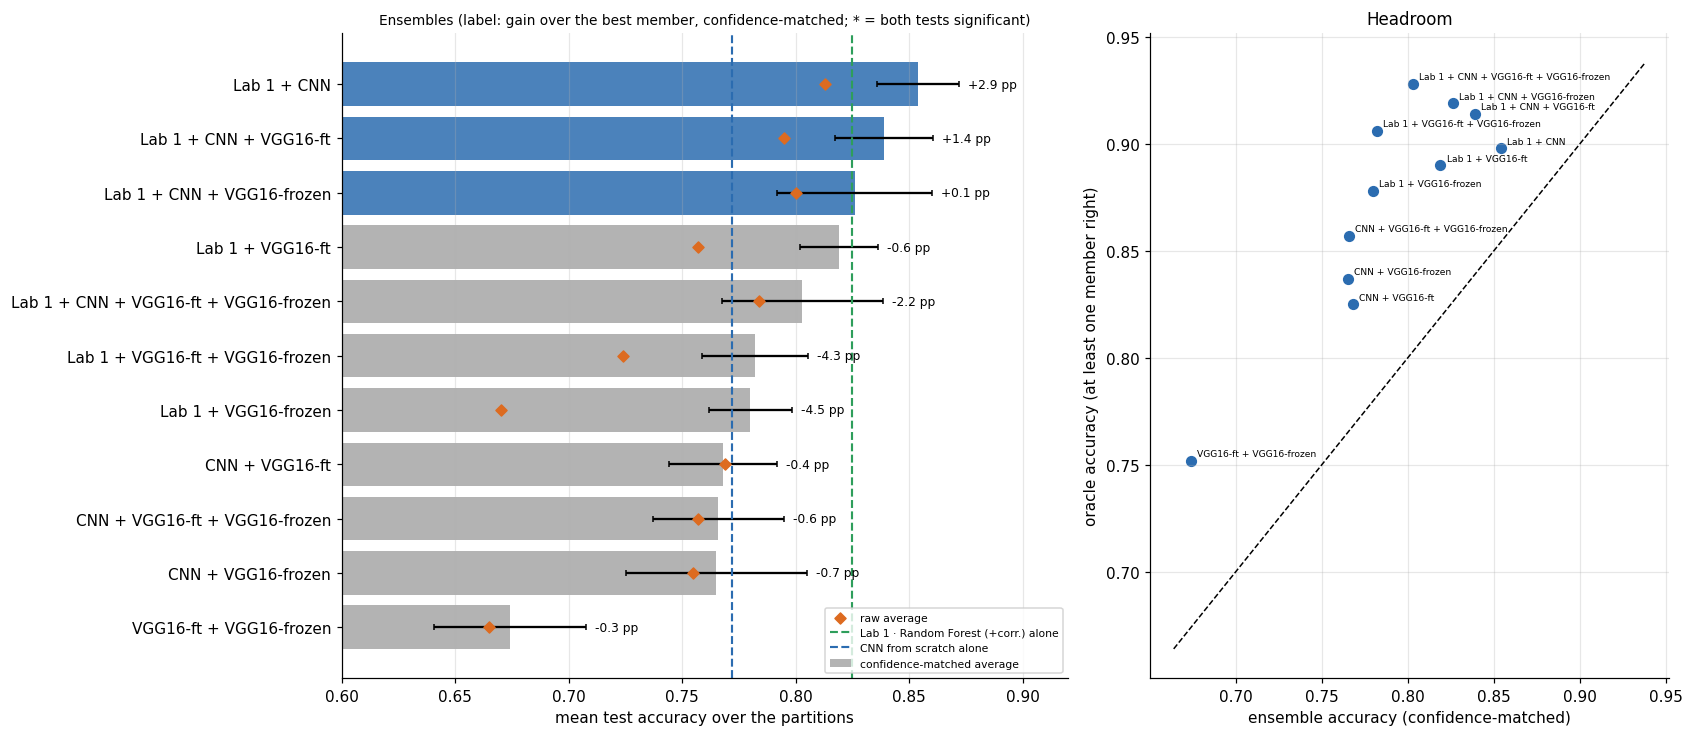

In [25]:
C_STAR = 0.70                                                 # common mean top-1 probability for the confidence-matched average (label-free)
SHORT = {LAB1_BEST: "Lab 1", CNN: "CNN", VGG_FT: "VGG16-ft", "vgg16_emb_logreg": "VGG16-frozen"}

def match_confidence(p, c=C_STAR):
    lo, hi = 0.05, 30.0                                      # bisection on the exponent alpha of p**alpha (renormalised)
    for _ in range(60):
        a = (lo + hi) / 2; q = np.maximum(p, 1e-12) ** a; q /= q.sum(1, keepdims=True)
        if q.max(1).mean() < c: lo = a
        else: hi = a
    return q

def ens_proba(models, s, w=None, matched=False, c=C_STAR):
    return np.average([match_confidence(proba(m, s), c) if matched else proba(m, s) for m in models], axis=0, weights=w)
ens_pred = lambda models, s, w=None, matched=False, c=C_STAR: ens_proba(models, s, w, matched, c).argmax(1)

rows = []
for r_ in range(2, len(REPS) + 1):
    for ms in itertools.combinations(REPS, r_):
        mean_single = {m: np.mean([correct(m, s).mean() for s in SEEDS_ALL]) for m in ms}; best = max(ms, key=mean_single.get)
        for matched in (False, True):
            accs = np.array([(ens_pred(ms, s, matched=matched) == ytrue(s)).mean() for s in SEEDS_ALL]); d = accs - np.array([correct(best, s).mean() for s in SEEDS_ALL])
            ok = ens_pred(ms, PRIMARY, matched=matched) == ytrue(PRIMARY); n01, n10, p = mcnemar_exact(ok, correct(best, PRIMARY))
            rows.append(dict(ensemble=" + ".join(SHORT[m] for m in ms), weighting="confidence-matched" if matched else "raw average", n_models=len(ms), members=", ".join(ms), mean_acc=accs.mean(), std_acc=accs.std(ddof=1),
                             best_member=best, best_member_mean_acc=mean_single[best], gain_vs_best_pp=100 * d.mean(), seeds_ensemble_wins=int((d > 0).sum()), only_ens_right=n01, only_best_right=n10,
                             p_mcnemar_vs_best=p, p_nadeau_bengio=nadeau_bengio(d), oracle_acc=np.mean([np.logical_or.reduce([correct(m, s) for m in ms]).mean() for s in SEEDS_ALL])))
ens_tbl = pd.DataFrame(rows)
ens_tbl["p_mcnemar_holm"] = holm(ens_tbl.p_mcnemar_vs_best.to_numpy()); ens_tbl["p_NB_holm"] = holm(ens_tbl.p_nadeau_bengio.fillna(1).to_numpy())
ens_tbl = ens_tbl.sort_values(["weighting", "mean_acc"], ascending=[True, False]).reset_index(drop=True); ens_tbl.to_csv(OUT / "table_ensembles.csv", index=False)
display(ens_tbl.drop(columns=["members", "best_member"]).round(4))

fig, axs = plt.subplots(1, 2, figsize=(15.5, 0.40 * (len(ens_tbl) // 2) + 2.4), gridspec_kw=dict(width_ratios=[1.4, 1]))
mt_ = ens_tbl[ens_tbl.weighting == "confidence-matched"].sort_values("mean_acc").reset_index(drop=True); rw_ = ens_tbl[ens_tbl.weighting == "raw average"].set_index("ensemble"); ax = axs[0]
sig = (mt_.p_mcnemar_holm < .05) & (mt_.p_NB_holm < .05)
ax.barh(mt_.ensemble, mt_.mean_acc, xerr=mt_.std_acc, color=np.where(mt_.gain_vs_best_pp > 0, "#2b6cb0", "0.65"), alpha=.85, capsize=2, label="confidence-matched average")
ax.scatter([rw_.mean_acc[e] for e in mt_.ensemble], range(len(mt_)), marker="D", s=26, color="#dd6b20", zorder=3, label="raw average")
for m, c_ in ((LAB1_BEST, FAM_COLORS["Hand-crafted descriptors"]), (CNN, FAM_COLORS["CNN from scratch"])): ax.axvline(_acc[m], color=c_, ls="--", lw=1.4, label=f"{nice(m)} alone")
for i, r in mt_.iterrows(): ax.text(max(r.mean_acc + r.std_acc, rw_.mean_acc[r.ensemble]) + .004, i, f"{r.gain_vs_best_pp:+.1f} pp" + (" *" if sig[i] else ""), va="center", fontsize=8)
ax.set_xlim(0.6, 0.92); ax.set_xlabel("mean test accuracy over the partitions"); ax.legend(loc="lower right", fontsize=7); ax.grid(axis="x", alpha=.3)
ax.set_title("Ensembles (label: gain over the best member, confidence-matched; * = both tests significant)", fontsize=9)
ax = axs[1]; ax.scatter(mt_.mean_acc, mt_.oracle_acc, s=40, color="#2b6cb0"); lim = [mt_.mean_acc.min() - .01, mt_.oracle_acc.max() + .01]; ax.plot(lim, lim, "k--", lw=1)
for _, r in mt_.iterrows(): ax.annotate(r.ensemble, (r.mean_acc, r.oracle_acc), xytext=(4, 3), textcoords="offset points", fontsize=6)
ax.set_xlabel("ensemble accuracy (confidence-matched)"); ax.set_ylabel("oracle accuracy (at least one member right)"); ax.grid(alpha=.3); ax.set_title("Headroom")
plt.tight_layout(); savefig("q3_ensembles.png"); plt.show()
KEY["q3"] = ens_tbl[["ensemble", "weighting", "mean_acc", "std_acc", "best_member_mean_acc", "gain_vs_best_pp", "seeds_ensemble_wins", "p_mcnemar_holm", "p_NB_holm", "oracle_acc"]].round(4).to_dict("records")

### 10.2 Sensitivity: how much do the weights and the confidence target matter? (descriptive, not tuned on the test set)

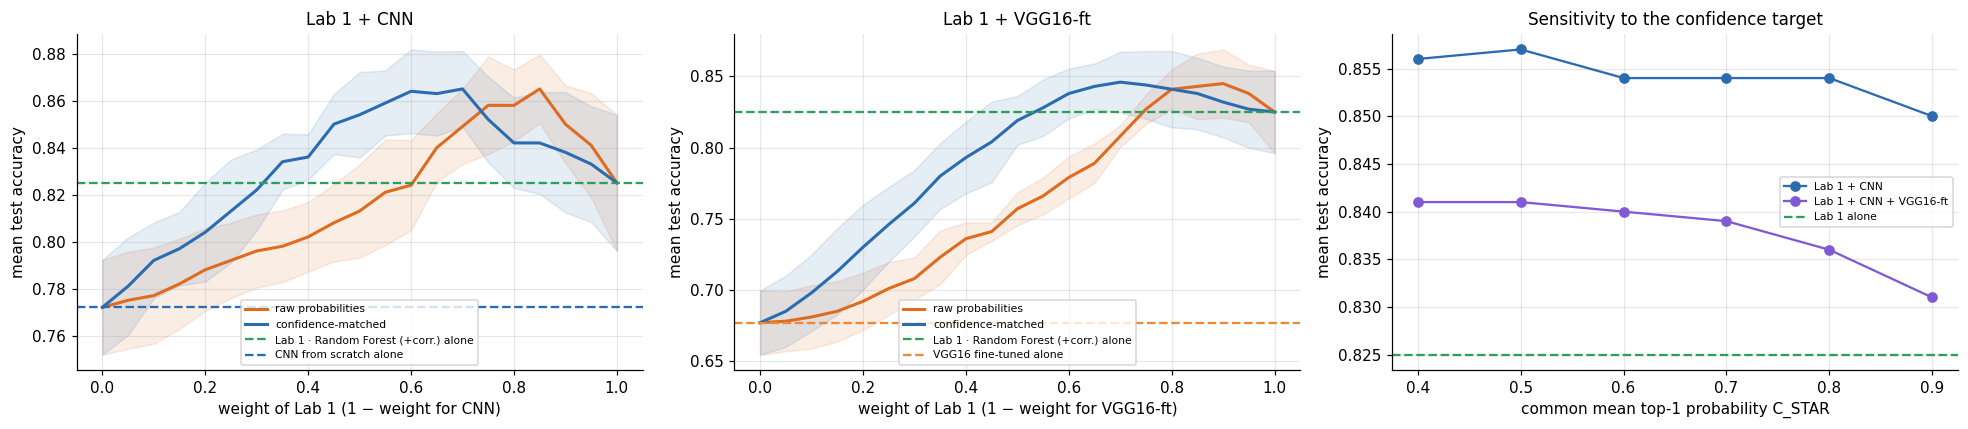

In [26]:
ws = np.linspace(0, 1, 21); fig, axs = plt.subplots(1, 3, figsize=(18, 4)); other_list = [o for o in (CNN, VGG_FT) if o in MODELS_MAIN]
for ax, other in zip(axs, other_list):
    for matched, c_, lab in ((False, "#dd6b20", "raw probabilities"), (True, "#2b6cb0", "confidence-matched")):
        A = np.array([[(ens_pred([LAB1_BEST, other], s, [w, 1 - w], matched=matched) == ytrue(s)).mean() for w in ws] for s in SEEDS_ALL])
        ax.plot(ws, A.mean(0), color=c_, lw=2, label=lab); ax.fill_between(ws, A.mean(0) - A.std(0, ddof=1), A.mean(0) + A.std(0, ddof=1), color=c_, alpha=.12)
    ax.axhline(_acc[LAB1_BEST], color=FAM_COLORS["Hand-crafted descriptors"], ls="--", label=f"{nice(LAB1_BEST)} alone"); ax.axhline(_acc[other], color=color(other), ls="--", label=f"{nice(other)} alone")
    ax.set_xlabel(f"weight of {SHORT[LAB1_BEST]} (1 − weight for {SHORT[other]})"); ax.set_ylabel("mean test accuracy"); ax.grid(alpha=.3); ax.legend(fontsize=7, loc="lower center"); ax.set_title(f"{SHORT[LAB1_BEST]} + {SHORT[other]}")
ax = axs[2]; cs = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
for ms, c_ in (((LAB1_BEST, CNN), "#2b6cb0"), ((LAB1_BEST, CNN, VGG_FT), "#805ad5")):
    if all(m in MODELS_MAIN for m in ms): ax.plot(cs, [np.mean([(ens_pred(ms, s, matched=True, c=c) == ytrue(s)).mean() for s in SEEDS_ALL]) for c in cs], "o-", color=c_, label=" + ".join(SHORT[m] for m in ms))
ax.axhline(_acc[LAB1_BEST], color=FAM_COLORS["Hand-crafted descriptors"], ls="--", label=f"{SHORT[LAB1_BEST]} alone"); ax.set_xlabel("common mean top-1 probability C_STAR"); ax.set_ylabel("mean test accuracy"); ax.grid(alpha=.3); ax.legend(fontsize=7)
ax.set_title("Sensitivity to the confidence target"); plt.tight_layout(); savefig("q3_weight_sweep.png"); plt.show()

### 10.3 What does the ensemble change? Lab 1 + CNN (confidence-matched), song by song

In [27]:
a, b = LAB1_BEST, CNN; rows = []
for s in SEEDS_ALL:
    ca, cb, ce = correct(a, s), correct(b, s), ens_pred([a, b], s, matched=True) == ytrue(s)
    rows.append(dict(seed=s, only_one_right=int((ca ^ cb).sum()), ensemble_fixes=int(((ca ^ cb) & ce).sum()), both_right=int((ca & cb).sum()), ensemble_breaks=int((ca & cb & ~ce).sum()),
                     both_wrong=int((~ca & ~cb).sum()), ensemble_rescues=int((~ca & ~cb & ce).sum())))
dd = pd.DataFrame(rows).set_index("seed"); dd.loc["total"] = dd.sum(); display(dd)
print("Of the songs where exactly one model is right, the ensemble gets", f"{dd.loc['total', 'ensemble_fixes'] / dd.loc['total', 'only_one_right']:.0%}", "right.")

,only_one_right,ensemble_fixes,both_right,ensemble_breaks,both_wrong,ensemble_rescues
seed,,,,,,
42,32,26,144,0,24,3
43,38,31,145,0,17,0
44,40,29,140,0,20,0
45,38,28,139,0,23,0
46,51,38,131,0,18,0
total,199,152,699,0,102,3


Of the songs where exactly one model is right, the ensemble gets 76% right.


## 11. Q4 — Is the extra cost worth it?

Accuracy against training time, inference time and model size. A random forest on descriptors may come close to a CNN at a fraction of the cost.

> **Caveats.** Training times were measured on different hardware (Random Forest on a CPU, networks on a Colab T4 GPU) and the descriptors themselves must be extracted from the audio, which is not included in the inference times. Inference time of the image models excludes decoding the PNG. The cost of VGGish includes reading and resampling the audio file.

,mean_acc,std_acc,train_time_s,infer_ms_per_song,size_mb,params,acc_diff_vs_lab1_pp,train_x,infer_x,size_x
model,,,,,,,,,,
lab1_random_forest_correlation,0.825,0.029,2.727,0.194,15.293,NaN,0.0,1.000,1.000,1.000
lab1_random_forest_without_selection,0.815,0.029,3.356,0.187,13.954,NaN,-1.0,1.230,0.966,0.912
lab1_extra_trees_correlation,0.809,0.023,1.119,0.238,35.763,NaN,-1.6,0.410,1.228,2.338
cnn_scratch,0.772,0.020,58.659,4.263,1.568,391946.0,-5.3,21.507,22.015,0.103
vgg16_ft,0.677,0.023,127.329,8.067,58.879,14719818.0,-14.8,46.684,41.659,3.850
vgg16_emb_logreg,0.616,0.034,0.351,12.019,0.020,5130.0,-20.9,0.129,62.069,0.001


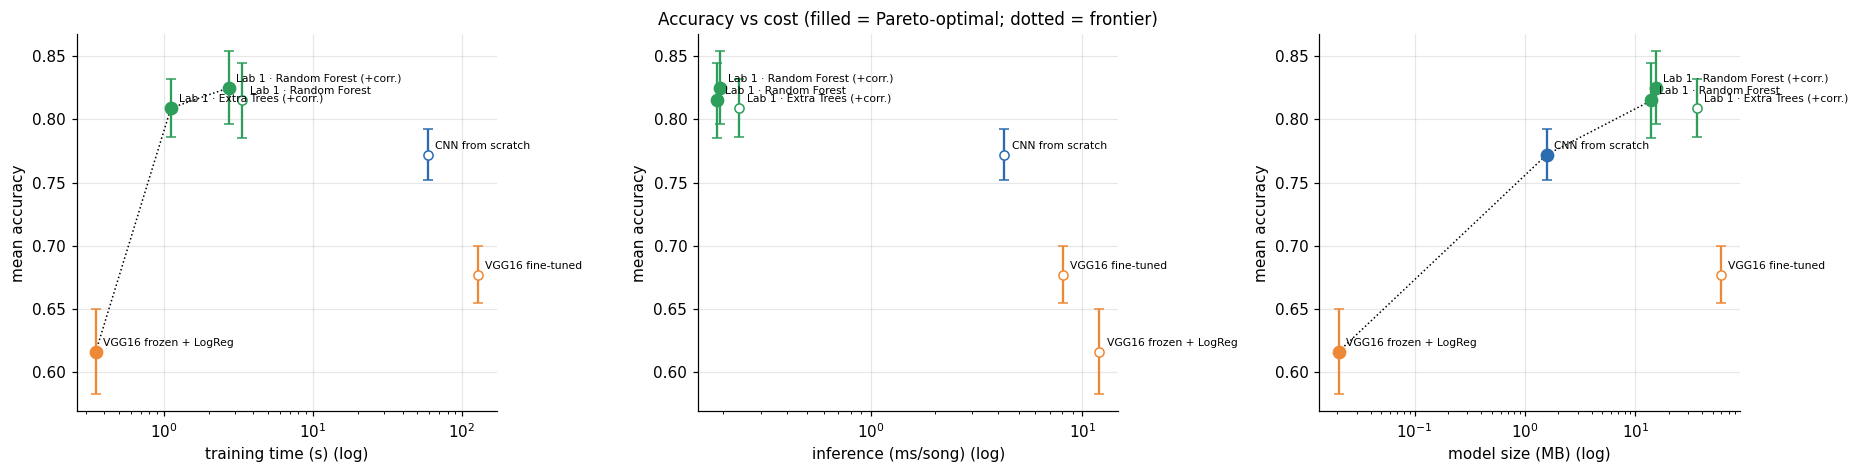

CNN from scratch vs Lab 1 · Random Forest (+corr.): -5.3 pp accuracy for 22x the training time, 22x the inference time and 0.10x the size.


In [28]:
costs = pd.read_csv(OUT / "costs.csv"); cm = costs.groupby("model")[["train_time_s", "infer_ms_per_song", "size_mb", "params"]].mean()
cost_tbl = main_tbl.set_index("model")[["mean_acc", "std_acc"]].join(cm).sort_values("mean_acc", ascending=False)
ref = cost_tbl.loc[LAB1_BEST]
cost_tbl["acc_diff_vs_lab1_pp"] = 100 * (cost_tbl.mean_acc - ref.mean_acc)
for c, nm in (("train_time_s", "train_x"), ("infer_ms_per_song", "infer_x"), ("size_mb", "size_x")): cost_tbl[nm] = cost_tbl[c] / ref[c]
cost_tbl.to_csv(OUT / "table_cost.csv"); display(cost_tbl.round(3))

def pareto(df, col):                                         # non-dominated models: no cheaper model is at least as accurate
    d = df.dropna(subset=[col]).sort_values(col); best = -1; keep = []
    for m, r in d.iterrows():
        if r.mean_acc > best: keep.append(m); best = r.mean_acc
    return keep

fig, axs = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, col, lab in zip(axs, ["train_time_s", "infer_ms_per_song", "size_mb"], ["training time (s)", "inference (ms/song)", "model size (MB)"]):
    dcol = cost_tbl.dropna(subset=[col]); front = pareto(cost_tbl, col)
    for m, r in dcol.iterrows():
        ax.errorbar(r[col], r.mean_acc, yerr=r.std_acc, fmt="o", capsize=3, color=color(m), ms=8 if m in front else 6, mfc=color(m) if m in front else "w")
        ax.annotate(nice(m), (r[col], r.mean_acc), fontsize=7, xytext=(5, 4), textcoords="offset points")
    ax.plot(dcol.loc[front, col], dcol.loc[front, "mean_acc"], "k:", lw=1); ax.set_xscale("log"); ax.set_xlabel(lab + " (log)"); ax.set_ylabel("mean accuracy"); ax.grid(alpha=.3)
axs[1].set_title("Accuracy vs cost (filled = Pareto-optimal; dotted = frontier)")
plt.tight_layout(); savefig("q4_cost.png"); plt.show()

c_ = cost_tbl.loc[CNN]; print(f"{nice(CNN)} vs {nice(LAB1_BEST)}: {c_.acc_diff_vs_lab1_pp:+.1f} pp accuracy for {c_.train_x:.0f}x the training time, {c_.infer_x:.0f}x the inference time and {c_.size_x:.2f}x the size.")
KEY["q4"] = cost_tbl.reset_index()[["model", "mean_acc", "train_time_s", "infer_ms_per_song", "size_mb", "params", "acc_diff_vs_lab1_pp", "train_x", "infer_x", "size_x"]].round(4).to_dict("records")

### 11.2 All models on the main partition: accuracy against training and inference time

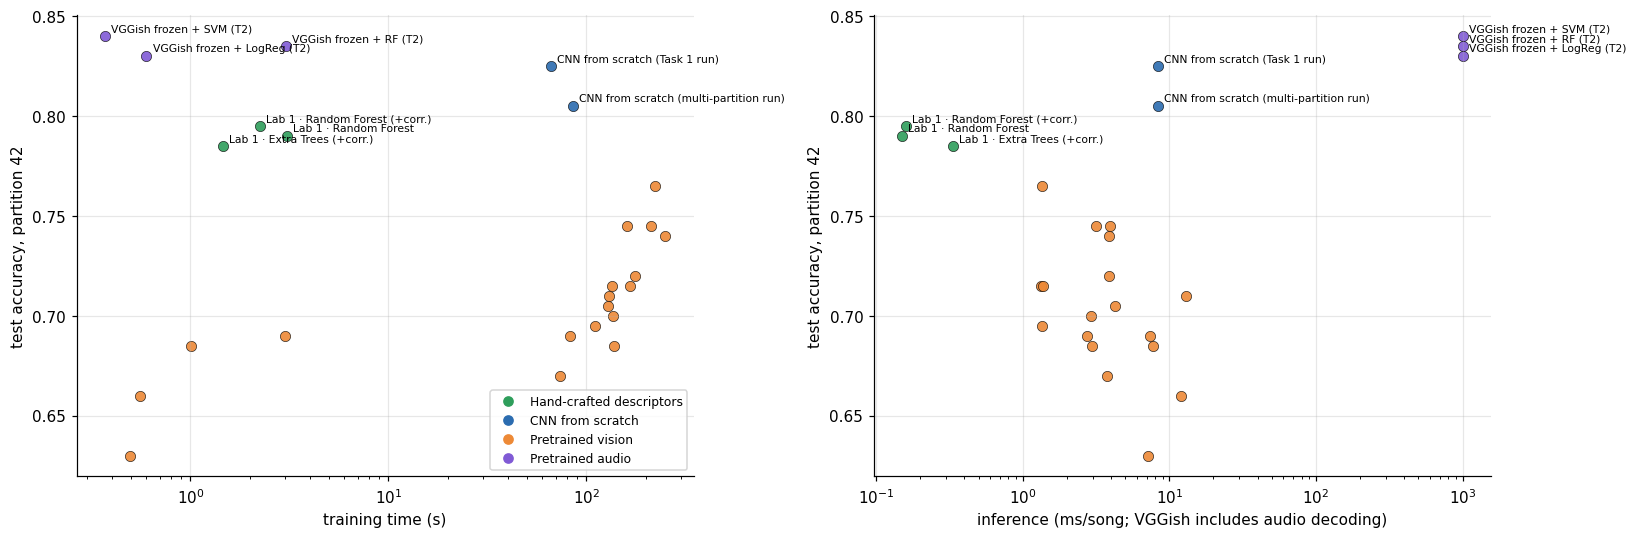

In [29]:
rows = []
for m in P42:
    if m in costs.model.values and (costs[(costs.model == m) & (costs.seed == PRIMARY)].shape[0]):
        r = costs[(costs.model == m) & (costs.seed == PRIMARY)].iloc[0]; rows.append((m, r.train_time_s, r.infer_ms_per_song))
    elif m.startswith("t2_") and m[3:] in T2_RUNS.index: r = T2_RUNS.loc[m[3:]]; rows.append((m, r.train_time_s, r.infer_ms_per_song))
    elif m == "t1_cnn_scratch" and (T1 / "task1_final.csv").exists(): r = pd.read_csv(T1 / "task1_final.csv").iloc[0]; rows.append((m, r.train_time_s, r.infer_ms_per_song))
c42 = pd.DataFrame(rows, columns=["model", "train_time_s", "infer_ms_per_song"]).set_index("model").join(tbl42.set_index("model")[["acc", "label", "approach"]])
c42.to_csv(OUT / "table_cost_all_models_primary.csv"); fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for ax, col, lab in zip(axs, ["train_time_s", "infer_ms_per_song"], ["training time (s)", "inference (ms/song; VGGish includes audio decoding)"]):
    for m, r in c42.iterrows(): ax.scatter(r[col], r.acc, color=FAM_COLORS[r.approach], s=45, alpha=.9, edgecolor="k", lw=.4)
    for m, r in c42.sort_values("acc", ascending=False).head(8).iterrows(): ax.annotate(r.label, (r[col], r.acc), fontsize=7, xytext=(4, 3), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel(lab); ax.set_ylabel(f"test accuracy, partition {PRIMARY}"); ax.grid(alpha=.3)
axs[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c_, label=k) for k, c_ in FAM_COLORS.items()], fontsize=8, loc="lower right"); plt.tight_layout(); savefig("q4_cost_all_models.png"); plt.show()

# Part III — Designing the CNN

These three sections use the sweeps of `multiseed_retraining`: the **first three partitions** (seeds 42–44) and a fixed number of epochs, with the other hyperparameters as in Task 1. As elsewhere, the test set is used here only to *describe* how accuracy changes, never to pick a model.

## 12. Q6 — How does data size affect the comparison?
Learning curves with 10, 25, 50 and 100 % of the **training songs** (stratified by genre), always evaluated on the same 200 test songs, for the CNN from scratch and for the best Lab 1 model.

> **Limitation of the CNN curve.** The CNN is trained for a fixed number of epochs, so with 10–25 % of the data it also performs far fewer optimisation steps (a tenth of the updates at 10 %). Its low accuracy for small fractions therefore mixes *less data* with *less training*, and the descriptor model has no such handicap. Read the gap at 10–25 % with this in mind.

label,CNN from scratch,Lab 1 (best descriptor model),"gap (Lab 1 − CNN, pp)"
frac,,,
0.10,0.207,0.553,34.667
0.25,0.333,0.688,35.500
0.50,0.618,0.767,14.833
1.00,0.782,0.833,5.167


seed                                   42     43     44
label                         frac                     
CNN from scratch              0.10  0.170  0.155  0.295
                              0.25  0.305  0.385  0.310
                              0.50  0.705  0.565  0.585
                              1.00  0.810  0.780  0.755
Lab 1 (best descriptor model) 0.10  0.540  0.525  0.595
                              0.25  0.695  0.675  0.695
                              0.50  0.710  0.790  0.800
                              1.00  0.795  0.870  0.835

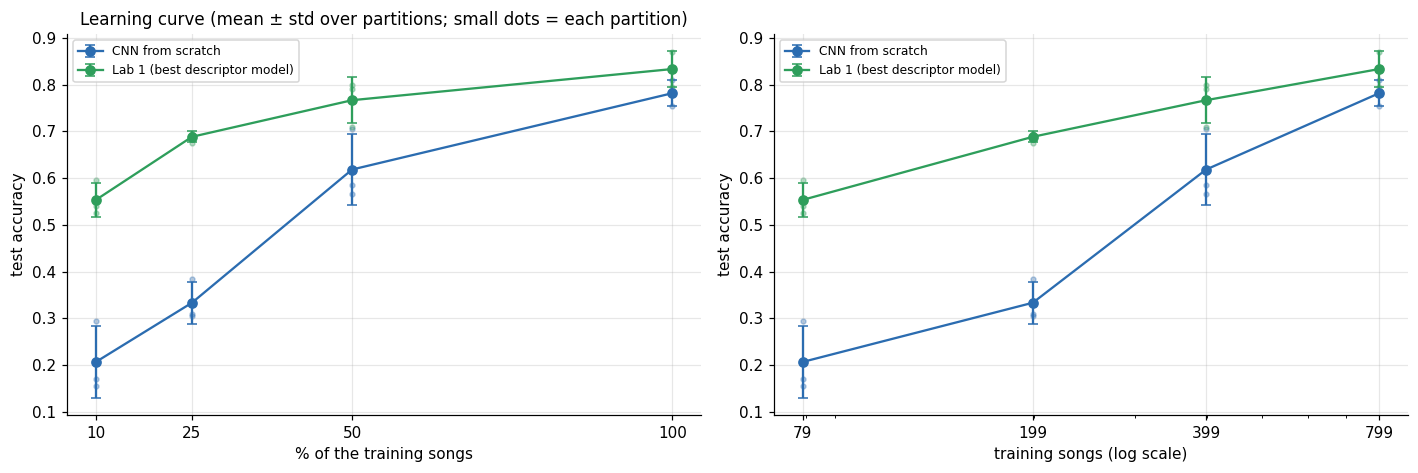

Accuracy retained with only 10 % of the training songs, relative to 100 %: {'CNN from scratch': 0.26, 'Lab 1 (best descriptor model)': 0.66}


In [30]:
parts = []
for f, lab, fam in (("learning_curve_cnn.csv", "CNN from scratch", "CNN from scratch"), ("learning_curve_lab1.csv", "Lab 1 (best descriptor model)", "Hand-crafted descriptors")):
    if (OUT / f).exists(): parts.append(pd.read_csv(OUT / f).assign(label=lab, approach=fam))
lc = pd.concat(parts); g = lc.groupby(["label", "approach", "frac"]).agg(n_train=("n_train", "mean"), mean=("test_acc", "mean"), std=("test_acc", "std"), n_seeds=("seed", "nunique")).reset_index()
piv = g.pivot(index="frac", columns="label", values="mean"); piv["gap (Lab 1 − CNN, pp)"] = 100 * (piv["Lab 1 (best descriptor model)"] - piv["CNN from scratch"]); display(piv.round(3))
display(lc.pivot_table(index=["label", "frac"], columns="seed", values="test_acc").round(3))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, xcol, xl in zip(axs, ["frac", "n_train"], ["% of the training songs", "training songs (log scale)"]):
    for (lab, fam), d in g.groupby(["label", "approach"]):
        x = d.frac * 100 if xcol == "frac" else d.n_train; ax.errorbar(x, d["mean"], yerr=d["std"], marker="o", capsize=3, color=FAM_COLORS[fam], label=lab)
        for _, r in lc[lc.label == lab].iterrows(): ax.scatter(r.frac * 100 if xcol == "frac" else r.n_train, r.test_acc, s=10, color=FAM_COLORS[fam], alpha=.35)
    if xcol == "frac": ax.set_xticks([10, 25, 50, 100])
    else: ax.set_xscale("log"); ax.set_xticks(sorted(g.n_train.round().unique())); ax.set_xticklabels([f"{int(v)}" for v in sorted(g.n_train.round().unique())])
    ax.set_xlabel(xl); ax.set_ylabel("test accuracy"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[0].set_title("Learning curve (mean ± std over partitions; small dots = each partition)"); plt.tight_layout(); savefig("q6_learning_curves.png"); plt.show()
ret = (piv.iloc[0] / piv.iloc[-1]).drop("gap (Lab 1 − CNN, pp)"); print("Accuracy retained with only 10 % of the training songs, relative to 100 %:", ret.round(2).to_dict())
KEY["q6"] = piv.round(4).reset_index().to_dict("records")

# Part IV — Pretrained models

## 13. Q9 — Would fine-tuning a pretrained model improve the model? Vision model or audio model?
Task 2 compares, on the **main partition** (719 train / 80 validation / 200 test songs): three ImageNet vision networks (VGG16, ResNet50, EfficientNetB0) with four fine-tuning strategies (head only, last block, last two blocks, whole network), and **VGGish**, a network pretrained on audio, used as a frozen feature extractor with classical classifiers. The CNN from scratch and the descriptor model are the references. Everything is evaluated on the same 200 test songs, and models are chosen with the validation accuracy (80 songs), which makes the best of 12 configurations an optimistic estimate.

val_acc  test_acc  train_time_s  \
Model          Strategy                                           
VGG16          head only          0.650     0.670          74.0   
               last block         0.712     0.705         129.0   
               last two blocks    0.812     0.745         161.0   
               full network       0.775     0.740         251.0   
ResNet50       head only          0.762     0.690          83.0   
               last block         0.750     0.685         139.0   
               last two blocks    0.750     0.700         136.0   
               full network       0.762     0.745         212.0   
EfficientNetB0 head only          0.688     0.695         111.0   
               last block         0.700     0.715         134.0   
               last two blocks    0.700     0.715         166.0   
               full network       0.775     0.765         223.0   

                                infer_ms_per_song      params  \
Model          Strategy                                         
VGG16          head only                      3.8  14719818.0   
               last block                     4.3  14719818.0   
               last two blocks                4.0  14719818.0   
               full network                   3.9  14719818.0   
ResNet50       head only                      2.8  23608202.0   
               last block                     3.0  23608202.0   
               last two blocks                2.9  23608202.0   
               full network                   3.1  23608202.0   
EfficientNetB0 head only                      1.4   4062381.0   
               last block                     1.3   4062381.0   
               last two blocks                1.4   4062381.0   
               full network                   1.4   4062381.0   

                                selected_by_validation  best_on_test  
Model          Strategy                                               
VGG16          head only                         False         False  
               last block                        False         False  
               last two blocks                    True         False  
               full network                      False         False  
ResNet50       head only                         False         False  
               last block                        False         False  
               last two blocks                   False         False  
               full network                      False         False  
EfficientNetB0 head only                         False         False  
               last block                        False         False  
               last two blocks                   False         False  
               full network                      False          True

Selected by validation: vgg16_block45 (val 0.812 -> test 0.745) | best on test: effnetb0_full | Spearman(val, test) over the 12 configurations = 0.64 (p = 0.024)
Wilson 95 % interval of the selected model: [0.680, 0.800]


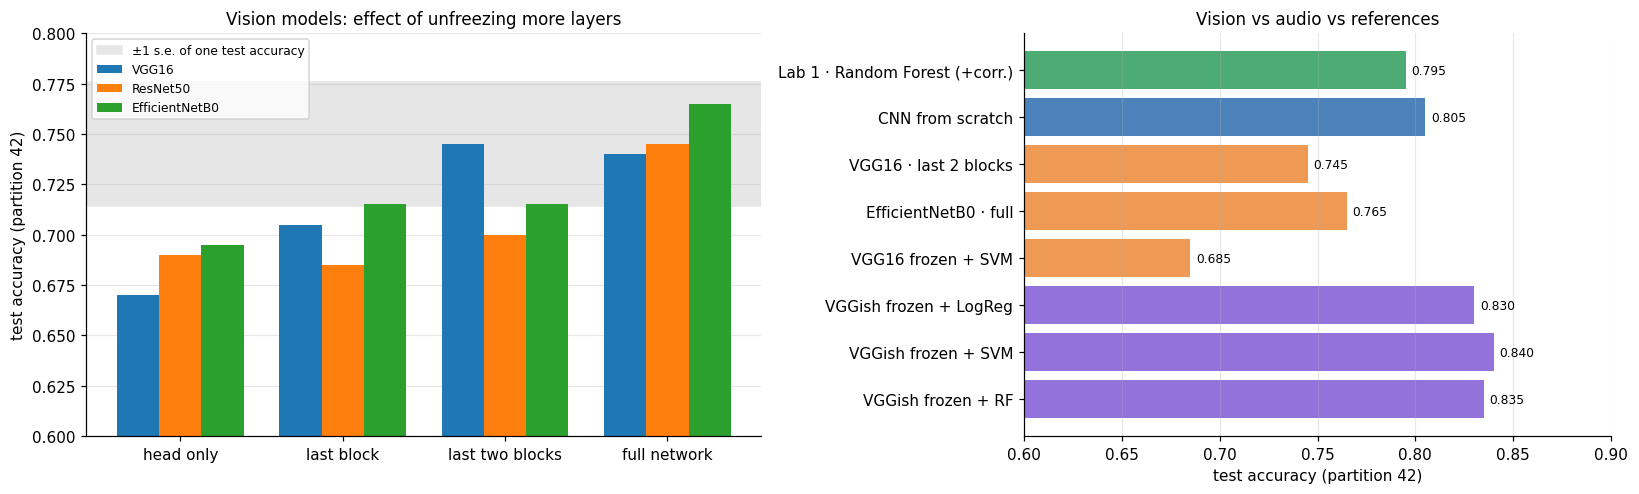

In [33]:
LAYOUT = [("VGG16", "head only", "vgg16_head"), ("VGG16", "last block", "vgg16_block5"), ("VGG16", "last two blocks", "vgg16_block45"), ("VGG16", "full network", "vgg16_full"),
          ("ResNet50", "head only", "resnet50_head"), ("ResNet50", "last block", "resnet50_conv5"), ("ResNet50", "last two blocks", "resnet50_conv45"), ("ResNet50", "full network", "resnet50_full"),
          ("EfficientNetB0", "head only", "effnetb0_head"), ("EfficientNetB0", "last block", "effnetb0_last"), ("EfficientNetB0", "last two blocks", "effnetb0_last2"), ("EfficientNetB0", "full network", "effnetb0_full")]
t2 = pd.DataFrame([dict(Model=m, Strategy=s, key=k_, **T2_RUNS.loc[k_, ["val_acc", "test_acc", "train_time_s", "infer_ms_per_song", "params"]]) for m, s, k_ in LAYOUT])
SEL = t2.loc[t2.val_acc.idxmax(), "key"]; BEST_T = t2.loc[t2.test_acc.idxmax(), "key"]; t2["selected_by_validation"] = t2.key == SEL; t2["best_on_test"] = t2.key == BEST_T
display(t2.drop(columns="key").round({"val_acc": 3, "test_acc": 3, "train_time_s": 0, "infer_ms_per_song": 1}).set_index(["Model", "Strategy"]))
rho, pv = stats.spearmanr(t2.val_acc, t2.test_acc)
print(f"Selected by validation: {SEL} (val {t2.set_index('key').val_acc[SEL]:.3f} -> test {t2.set_index('key').test_acc[SEL]:.3f}) | best on test: {BEST_T} | Spearman(val, test) over the 12 configurations = {rho:.2f} (p = {pv:.3f})")
n_ok = int(round(t2.set_index("key").test_acc[SEL] * 200)); lo, hi = wilson(n_ok, 200); print(f"Wilson 95 % interval of the selected model: [{lo:.3f}, {hi:.3f}]")

strategies = ["head only", "last block", "last two blocks", "full network"]; p_sel = float(t2.set_index("key").test_acc[SEL]); se = np.sqrt(p_sel * (1 - p_sel) / 200)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[1.15, 1])); ax = axs[0]; w = 0.26
ax.axhspan(p_sel - se, p_sel + se, color="0.9", zorder=0, label="±1 s.e. of one test accuracy")
for j, (m, c_) in enumerate(zip(["VGG16", "ResNet50", "EfficientNetB0"], ["tab:blue", "tab:orange", "tab:green"])):
    ax.bar(np.arange(4) + (j - 1) * w, [t2[(t2.Model == m) & (t2.Strategy == s)].test_acc.iloc[0] for s in strategies], w, label=m, color=c_, zorder=2)
ax.set_xticks(range(4)); ax.set_xticklabels(strategies); ax.set_ylim(0.6, 0.8); ax.set_ylabel(f"test accuracy (partition {PRIMARY})"); ax.grid(axis="y", alpha=.3, zorder=1); ax.legend(fontsize=8, loc="upper left"); ax.set_title("Vision models: effect of unfreezing more layers")
ax = axs[1]; ref_ = [("Lab 1 · Random Forest (+corr.)", correct42(LAB1_BEST).mean(), FAM_COLORS["Hand-crafted descriptors"]), ("CNN from scratch", correct42(CNN).mean(), FAM_COLORS["CNN from scratch"])]
ref_ += [(T2_LABELS[k_], T2_RUNS.test_acc[k_], FAM_COLORS["Pretrained vision"] if "vggish" not in k_ else FAM_COLORS["Pretrained audio"]) for k_ in ["vgg16_block45", "effnetb0_full", "vgg16emb_svm", "vggish_logreg", "vggish_svm", "vggish_rf"]]
ref_ = ref_[::-1]; ax.barh([r[0] for r in ref_], [r[1] for r in ref_], color=[r[2] for r in ref_], alpha=.85); ax.set_xlim(0.6, 0.9); ax.set_xlabel(f"test accuracy (partition {PRIMARY})"); ax.grid(axis="x", alpha=.3)
for i, r in enumerate(ref_): ax.text(r[1] + .003, i, f"{r[1]:.3f}", va="center", fontsize=8)
ax.set_title("Vision vs audio vs references"); plt.tight_layout(); savefig("q9_pretrained_overview.png"); plt.show()
KEY["q9_t2"] = dict(selected=SEL, best_test=BEST_T, spearman=float(rho), spearman_p=float(pv), table=t2.drop(columns=["selected_by_validation", "best_on_test"]).round(4).to_dict("records"))

### 13.2 Vision vs audio: McNemar tests on the main partition

,A,B,acc_A,acc_B,only_A_right,only_B_right,p_mcnemar,p_holm,verdict
0,Lab 1 · Random Forest (+corr.),CNN from scratch,0.795,0.805,15,17,0.8601,1.0000,no significant difference
1,Lab 1 · Random Forest (+corr.),VGG16 · last 2 blocks (T2),0.795,0.745,28,18,0.1839,1.0000,no significant difference
2,Lab 1 · Random Forest (+corr.),EfficientNetB0 · full (T2),0.795,0.765,26,20,0.4614,1.0000,no significant difference
3,Lab 1 · Random Forest (+corr.),VGG16 frozen + SVM (T2),0.795,0.685,36,14,0.0026,0.0625,no significant difference
4,Lab 1 · Random Forest (+corr.),VGGish frozen + LogReg (T2),0.795,0.830,19,26,0.3713,1.0000,no significant difference
5,Lab 1 · Random Forest (+corr.),VGGish frozen + SVM (T2),0.795,0.840,14,23,0.1877,1.0000,no significant difference
6,Lab 1 · Random Forest (+corr.),VGGish frozen + RF (T2),0.795,0.835,17,25,0.2800,1.0000,no significant difference
7,CNN from scratch,VGG16 · last 2 blocks (T2),0.805,0.745,26,14,0.0807,1.0000,no significant difference
8,CNN from scratch,EfficientNetB0 · full (T2),0.805,0.765,21,13,0.2295,1.0000,no significant difference
9,CNN from scratch,VGG16 frozen + SVM (T2),0.805,0.685,36,12,0.0007,0.0179,A≠B


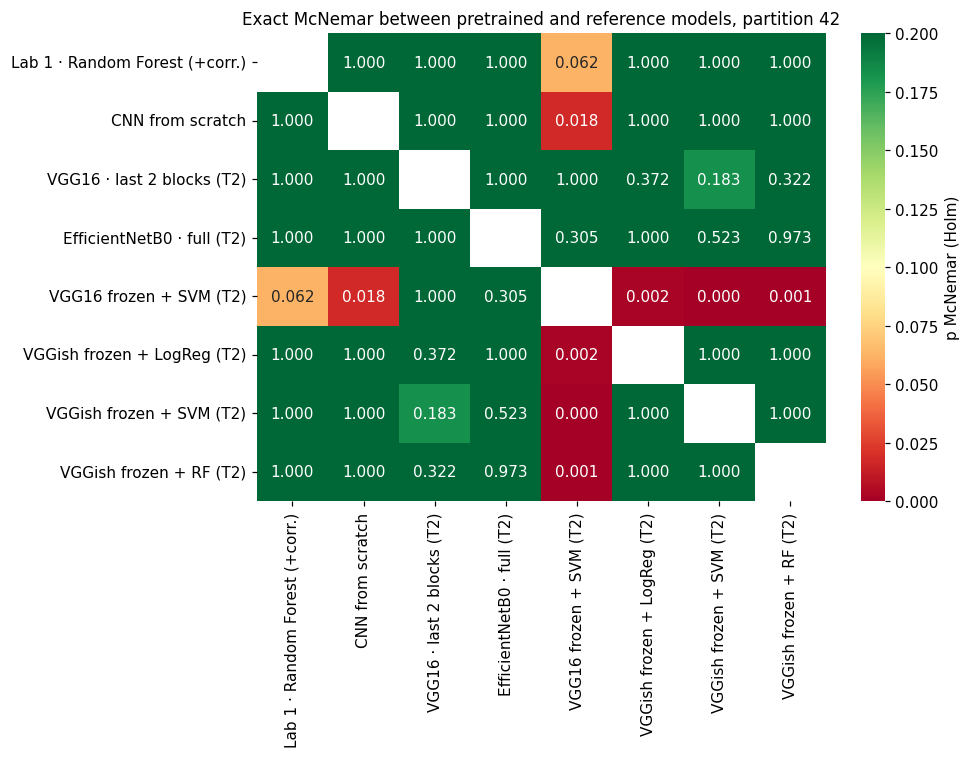

Same classifier, different embedding: frozen VGG16 (vision) vs frozen VGGish (audio)


,classifier,VGGish,VGG16,diff_pp,only_VGGish_right,only_VGG16_right,p,p_holm
0,logreg,0.830,0.630,20.0,51,11,0.0,0.0
1,svm,0.840,0.685,15.5,38,7,0.0,0.0
2,rf,0.835,0.690,14.5,38,9,0.0,0.0


In [34]:
SUB = [LAB1_BEST, CNN, "t2_vgg16_block45", "t2_effnetb0_full", "t2_vgg16emb_svm", "t2_vggish_logreg", "t2_vggish_svm", "t2_vggish_rf"]; SUB = [m for m in SUB if m in P42]
rows = []
for a, b in itertools.combinations(SUB, 2):
    n01, n10, p = mcnemar_exact(correct42(a), correct42(b)); rows.append(dict(A=nice(a), B=nice(b), acc_A=correct42(a).mean(), acc_B=correct42(b).mean(), only_A_right=n01, only_B_right=n10, p_mcnemar=p))
pw9 = pd.DataFrame(rows); pw9["p_holm"] = holm(pw9.p_mcnemar.to_numpy()); pw9["verdict"] = np.where(pw9.p_holm < .05, "A≠B", "no significant difference"); pw9.to_csv(OUT / "table_pairwise_pretrained_primary.csv", index=False)
display(pw9.round(4))

M9 = pd.DataFrame(np.nan, index=[nice(m) for m in SUB], columns=[nice(m) for m in SUB])
for _, r in pw9.iterrows(): M9.loc[r.A, r.B] = M9.loc[r.B, r.A] = r.p_holm
plt.figure(figsize=(9, 7)); sns.heatmap(M9, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0, vmax=0.2, cbar_kws={"label": "p McNemar (Holm)"}); plt.title(f"Exact McNemar between pretrained and reference models, partition {PRIMARY}")
plt.tight_layout(); savefig("q9_mcnemar_pretrained.png"); plt.show()

print("Same classifier, different embedding: frozen VGG16 (vision) vs frozen VGGish (audio)")
rows = []
for c_ in ("logreg", "svm", "rf"):
    a, b = f"t2_vggish_{c_}", f"t2_vgg16emb_{c_}"
    if a in P42 and b in P42: n01, n10, p = mcnemar_exact(correct42(a), correct42(b)); rows.append(dict(classifier=c_, VGGish=correct42(a).mean(), VGG16=correct42(b).mean(), diff_pp=100 * (correct42(a).mean() - correct42(b).mean()), only_VGGish_right=n01, only_VGG16_right=n10, p=p))
vv = pd.DataFrame(rows); vv["p_holm"] = holm(vv.p.to_numpy()); display(vv.round(4))
KEY["q9_vision_vs_audio"] = vv.round(4).to_dict("records")

### 13.3 Five partitions: does the Task 2 result hold up?
The selected VGG16 configuration (last two blocks) is retrained on every partition in `multiseed_retraining`, next to the CNN from scratch, the frozen VGG16 + logistic regression and the best descriptor model. The seed-42 value of this pipeline differs from the Task 2 search value (validation songs for early stopping and image-resizing implementation differ), which shows how much the best-of-12 selection on 80 validation songs inflates the search result.

In [35]:
PRE = [m for m in (LAB1_BEST, CNN, VGG_FT, "vgg16_emb_logreg") if m in MODELS_MAIN]
sub = main_tbl.set_index("model").loc[PRE, ["mean_acc", "std_acc", "min_acc", "max_acc"]].join(cost_tbl[["train_time_s", "infer_ms_per_song", "params"]]); display(sub.round(3))
pw_pre = pairwise(PRE); pw_pre.to_csv(OUT / "table_pairwise_pretrained.csv", index=False)
display(pw_pre[["A", "B", "acc_A", "acc_B", "only_A_right", "only_B_right", "p_mcnemar_holm", "mean_diff_seeds", "seeds_A_wins", "p_NB_holm", "verdict"]].round(4))
if "t2_vgg16_block45" in P42 and VGG_FT in P42: print(f"VGG16 last two blocks on partition {PRIMARY}: Task 2 search {correct42('t2_vgg16_block45').mean():.3f} vs multi-partition pipeline {correct42(VGG_FT).mean():.3f}; mean over {len(SEEDS_ALL)} partitions {np.mean([correct(VGG_FT, s).mean() for s in SEEDS_ALL]):.3f}")
KEY["q9_multiseed"] = pw_pre.round(4).to_dict("records")

,mean_acc,std_acc,min_acc,max_acc,train_time_s,infer_ms_per_song,params
model,,,,,,,
lab1_random_forest_correlation,0.825,0.029,0.795,0.870,2.727,0.194,NaN
cnn_scratch,0.772,0.020,0.750,0.805,58.659,4.263,391946.0
vgg16_ft,0.677,0.023,0.650,0.710,127.329,8.067,14719818.0
vgg16_emb_logreg,0.616,0.034,0.580,0.660,0.351,12.019,5130.0


,A,B,acc_A,acc_B,only_A_right,only_B_right,p_mcnemar_holm,mean_diff_seeds,seeds_A_wins,p_NB_holm,verdict
0,lab1_random_forest_correlation,cnn_scratch,0.795,0.805,15,17,0.8601,0.053,4,0.1274,no significant difference
1,lab1_random_forest_correlation,vgg16_ft,0.795,0.710,35,18,0.0810,0.148,5,0.0199,partial evidence
2,lab1_random_forest_correlation,vgg16_emb_logreg,0.795,0.660,44,17,0.0036,0.209,5,0.0199,A≠B (both tests)
3,cnn_scratch,vgg16_ft,0.805,0.710,31,12,0.0216,0.095,5,0.0039,A≠B (both tests)
4,cnn_scratch,vgg16_emb_logreg,0.805,0.660,41,12,0.0005,0.156,5,0.0025,A≠B (both tests)
5,vgg16_ft,vgg16_emb_logreg,0.710,0.660,24,14,0.2866,0.061,5,0.0475,partial evidence


VGG16 last two blocks on partition 42: Task 2 search 0.745 vs multi-partition pipeline 0.710; mean over 5 partitions 0.677


## 14. Q10 — Frozen embeddings + classical machine learning, or full fine-tuning?
Two ways of using the same pretrained network: **train only a classical classifier on its frozen embeddings** (cheap: the network is never trained) or **adapt its weights** (fine-tuning). The comparison uses accuracy, training time and inference time.

,setting,test_acc,val_acc,train_time_s,infer_ms_per_song
0,VGG16 frozen + LogReg,0.630,0.638,0.496,7.157
1,VGG16 frozen + SVM,0.685,0.688,1.007,7.786
2,VGG16 frozen + RF,0.690,0.675,3.014,7.371
3,"VGG16 head only (frozen features, linear layer)",0.670,0.650,73.503,3.778
4,"VGG16 last 2 blocks (fine-tuned, selected)",0.745,0.812,160.539,3.951
5,VGG16 full network,0.740,0.775,251.170,3.897
6,VGGish frozen + LogReg,0.830,0.900,0.599,1002.021
7,VGGish frozen + SVM,0.840,0.912,0.369,1002.147
8,VGGish frozen + RF,0.835,0.900,3.041,1002.118


Best frozen VGG16 embedding classifier: 0.690 vs fine-tuned VGG16 (last two blocks): 0.745 (+5.5 pp); training time 0.5–3.0 s vs 161 s


,frozen,fine_tuned_acc,frozen_acc,only_finetuned_right,only_frozen_right,p,p_holm
0,VGG16 frozen + LogReg,0.745,0.630,36,13,0.0014,0.0042
1,VGG16 frozen + SVM,0.745,0.685,26,14,0.0807,0.1614
2,VGG16 frozen + RF,0.745,0.690,24,13,0.0989,0.1614


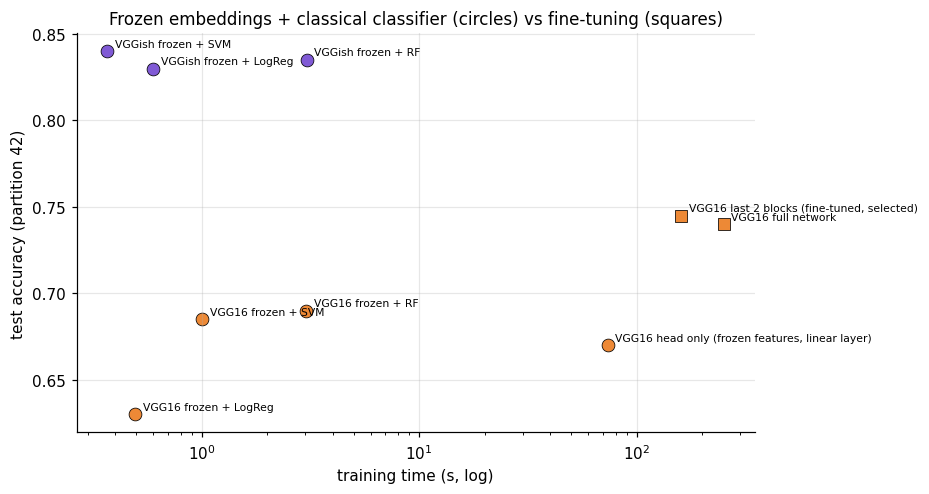

In [36]:
ROWS = [("VGG16 frozen + LogReg", "vgg16emb_logreg"), ("VGG16 frozen + SVM", "vgg16emb_svm"), ("VGG16 frozen + RF", "vgg16emb_rf"), ("VGG16 head only (frozen features, linear layer)", "vgg16_head"),
        ("VGG16 last 2 blocks (fine-tuned, selected)", "vgg16_block45"), ("VGG16 full network", "vgg16_full"), ("VGGish frozen + LogReg", "vggish_logreg"), ("VGGish frozen + SVM", "vggish_svm"), ("VGGish frozen + RF", "vggish_rf")]
q10 = pd.DataFrame([dict(setting=n, key=k_, test_acc=T2_RUNS.test_acc[k_], val_acc=T2_RUNS.val_acc[k_], train_time_s=T2_RUNS.train_time_s[k_], infer_ms_per_song=T2_RUNS.infer_ms_per_song[k_]) for n, k_ in ROWS if k_ in T2_RUNS.index])
q10.drop(columns="key").round(3).to_csv(OUT / "table_q10_frozen_vs_finetuned.csv", index=False); display(q10.drop(columns="key").round(3))
bf = q10[q10.key == "vgg16_block45"].iloc[0]; fz = q10[q10.key.str.startswith("vgg16emb")]
print(f"Best frozen VGG16 embedding classifier: {fz.test_acc.max():.3f} vs fine-tuned VGG16 (last two blocks): {bf.test_acc:.3f} ({100 * (bf.test_acc - fz.test_acc.max()):+.1f} pp); "
      f"training time {fz.train_time_s.min():.1f}–{fz.train_time_s.max():.1f} s vs {bf.train_time_s:.0f} s")
rows = []
for kz in fz.key:
    a, b = "t2_vgg16_block45", "t2_" + kz
    if a in P42 and b in P42: n01, n10, p = mcnemar_exact(correct42(a), correct42(b)); rows.append(dict(frozen=T2_LABELS[kz], fine_tuned_acc=correct42(a).mean(), frozen_acc=correct42(b).mean(), only_finetuned_right=n01, only_frozen_right=n10, p=p))
mc = pd.DataFrame(rows); mc["p_holm"] = holm(mc.p.to_numpy()); display(mc.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for _, r in q10.iterrows():
    c_ = FAM_COLORS["Pretrained audio"] if "VGGish" in r.setting else FAM_COLORS["Pretrained vision"]; mk = "o" if "frozen" in r.setting or "head only" in r.setting else "s"
    ax.scatter(r.train_time_s, r.test_acc, s=70, color=c_, marker=mk, edgecolor="k", lw=.5); ax.annotate(r.setting, (r.train_time_s, r.test_acc), fontsize=7, xytext=(5, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("training time (s, log)"); ax.set_ylabel(f"test accuracy (partition {PRIMARY})"); ax.grid(alpha=.3)
ax.set_title("Frozen embeddings + classical classifier (circles) vs fine-tuning (squares)"); plt.tight_layout(); savefig("q10_frozen_vs_finetuned.png"); plt.show()
KEY["q10"] = dict(table=q10.drop(columns="key").round(4).to_dict("records"), mcnemar=mc.round(4).to_dict("records"))

> **Not tested.** The research question also mentions CLAP as a pretrained audio starting point; only VGGish (audio) and ImageNet networks (vision) were evaluated in this project.

# Appendix

## 15. Complete results of every trained model
The tables of every model trained in the project, collected in one place and saved as CSV files (`results_lab2/appendix_*.csv`) for the appendix of the report:

- **A.** Lab 1: the 21 tuned pipelines (cross-validation on the 799 training songs of the main partition) and the test result of the two selected pipelines.
- **B.** Task 1: the 16 CNN configurations of the search (validation accuracy).
- **C.** Task 2: all fine-tuning runs, frozen embeddings and VGGish (validation and test accuracy, cost).
- **D.** Five-partition results of every multi-partition model.
- **E.** Sweeps: learning curves.

In [37]:
display(Markdown("#### A. Lab 1 — 21 tuned pipelines (10-fold CV on the training songs, partition 42)"))
if (OUT / "lab1_cv_table_seed42.csv").exists():
    A = pd.read_csv(OUT / "lab1_cv_table_seed42.csv").sort_values("Val Acc", ascending=False).reset_index(drop=True); A.round(4).to_csv(OUT / "appendix_A_lab1_cv.csv", index=False); display(A.round(3))
if (OUT / "lab1_retrained_seed42.csv").exists(): display(Markdown("**Selected pipelines on the test set (partition 42)**")); display(pd.read_csv(OUT / "lab1_retrained_seed42.csv").round(3))
display(Markdown("#### B. Task 1 — CNN configuration search (validation accuracy, 160 songs)"))
if (T1 / "task1_experiments.csv").exists():
    B = pd.read_csv(T1 / "task1_experiments.csv").sort_values("best_val_acc", ascending=False).reset_index(drop=True); B.round(4).to_csv(OUT / "appendix_B_task1_search.csv", index=False); display(B.round(3))
    if (T1 / "task1_final.csv").exists(): display(Markdown("**Final CNN of Task 1 (test set)**")); display(pd.read_csv(T1 / "task1_final.csv").round(3))
display(Markdown("#### C. Task 2 — fine-tuning, frozen embeddings and VGGish (partition 42)"))
C_ = T2_RUNS.reset_index().sort_values("val_acc", ascending=False).reset_index(drop=True); C_.round(4).to_csv(OUT / "appendix_C_task2_runs.csv", index=False); display(C_.round(3))
display(Markdown("#### D. Five partitions — every multi-partition model"))
D_ = main_tbl.drop(columns=["approach"]).copy(); D_.round(4).to_csv(OUT / "appendix_D_multipartition.csv", index=False); display(D_.round(3))
display(Markdown("#### E. Sweeps"))
for nm, f in (("kernel shape", "kernels.csv"), ("depth", "depth.csv"), ("learning curve (CNN)", "learning_curve_cnn.csv"), ("learning curve (Lab 1)", "learning_curve_lab1.csv")):
    if (OUT / f).exists(): print(nm); display(pd.read_csv(OUT / f).round(3).head(30))

#### A. Lab 1 — 21 tuned pipelines (10-fold CV on the training songs, partition 42)

,Name,Model,Selector,Family,Train Acc,Val Acc,Val Acc Std,Gap,Val F1,Val F1 Std,N features
0,Random Forest | Correlation,Random Forest,Correlation,—,0.999,0.785,0.038,0.214,0.781,0.040,55.0
1,Random Forest | Without selection,Random Forest,Without selection,—,0.999,0.784,0.042,0.215,0.779,0.045,58.0
2,Voting Ensemble | Without selection,Voting Ensemble,Without selection,—,0.999,0.780,0.056,0.219,0.778,0.056,58.0
3,Extra Trees | Without selection,Extra Trees,Without selection,—,0.999,0.779,0.043,0.220,0.774,0.046,58.0
4,Extra Trees | Correlation,Extra Trees,Correlation,—,0.999,0.777,0.047,0.222,0.773,0.049,55.0
5,Gradient Boosting | Without selection,Gradient Boosting,Without selection,—,0.999,0.772,0.043,0.227,0.771,0.044,58.0
6,Gradient Boosting | Correlation,Gradient Boosting,Correlation,—,0.999,0.766,0.035,0.233,0.766,0.037,55.0
7,AdaBoost | Without selection,AdaBoost,Without selection,—,0.974,0.727,0.050,0.247,0.732,0.049,58.0
8,Logistic Regression | Without selection,Logistic Regression,Without selection,—,0.843,0.725,0.063,0.118,0.721,0.061,58.0
9,ANN (MLP) | PCA var,ANN (MLP),PCA var,—,0.905,0.723,0.056,0.181,0.720,0.059,47.0


**Selected pipelines on the test set (partition 42)**

,model,val_acc_cv,test_acc,test_macro_f1
0,Random Forest | Correlation,0.785,0.795,0.791
1,Extra Trees | Correlation,0.777,0.785,0.780


#### B. Task 1 — CNN configuration search (validation accuracy, 160 songs)

,name,group,filters,kernel,dropout,augment,lr,img_h,img_w,depth,params,best_val_acc,best_epoch,train_time_s
0,dropout_0.0,factor,32-64-128-256,3x3,0.0,True,0.001,128,192,4,391946,0.775,39,50.610
1,4conv_32-64-128-256,depth,32-64-128-256,3x3,0.3,True,0.001,128,192,4,391946,0.762,40,57.019
2,no_augment,factor,32-64-128-256,3x3,0.3,False,0.001,128,192,4,391946,0.756,37,48.205
3,size_192x288,factor,32-64-128-256,3x3,0.3,True,0.001,192,288,4,391946,0.750,38,113.606
4,4conv_16-32-64-128,depth,16-32-64-128,3x3,0.3,True,0.001,128,192,4,99210,0.744,40,38.431
5,kernel_5x5,factor,32-64-128-256,5x5,0.3,True,0.001,128,192,4,1081610,0.738,40,74.283
6,size_64x96,factor,32-64-128-256,3x3,0.3,True,0.001,64,96,4,391946,0.725,38,29.899
7,lr_3e-4,factor,32-64-128-256,3x3,0.3,True,0.000,128,192,4,391946,0.719,36,52.891
8,lr_3e-3,factor,32-64-128-256,3x3,0.3,True,0.003,128,192,4,391946,0.712,40,52.601
9,3conv_32-64-128,depth,32-64-128,3x3,0.3,True,0.001,128,192,3,94986,0.688,37,55.105


... (11 outputs left out)

learning curve (CNN)


,model,seed,frac,n_train,test_acc
0,cnn_scratch,42,0.10,79,0.170
1,cnn_scratch,42,0.25,199,0.305
2,cnn_scratch,42,0.50,399,0.705
3,cnn_scratch,42,1.00,799,0.810
4,cnn_scratch,43,0.10,79,0.155
5,cnn_scratch,43,0.25,199,0.385
6,cnn_scratch,43,0.50,399,0.565
7,cnn_scratch,43,1.00,799,0.780
8,cnn_scratch,44,0.10,79,0.295
9,cnn_scratch,44,0.25,199,0.310


learning curve (Lab 1)


,model,seed,frac,n_train,test_acc
0,lab1_best,42,0.10,79,0.540
1,lab1_best,42,0.25,199,0.695
2,lab1_best,42,0.50,399,0.710
3,lab1_best,42,1.00,799,0.795
4,lab1_best,43,0.10,79,0.525
5,lab1_best,43,0.25,199,0.675
6,lab1_best,43,0.50,399,0.790
7,lab1_best,43,1.00,799,0.870
8,lab1_best,44,0.10,79,0.595
9,lab1_best,44,0.25,199,0.695



All the numbers that the report cites, collected from the sections above and saved in `results_lab2/key_numbers.json`, followed by a checklist per question: which table and figure to use and what to state.

In [38]:
def fmt_pp(x): return f"{100 * x:+.1f} pp"
print("=" * 100); print("ANSWER SHEET (all numbers come from the stored predictions; nothing is retrained)"); print("=" * 100)
mt = main_tbl.set_index("model")
print("\nQ1/Q5 — accuracy over the five partitions (mean ± std):")
for m in mt.index: print(f"   {nice(m):34s} {mt.mean_acc[m]:.3f} ± {mt.std_acc[m]:.3f}   range {mt.min_acc[m]:.3f}–{mt.max_acc[m]:.3f}   macro-F1 {mt.mean_f1[m]:.3f}")
print(f"   partition {PRIMARY} alone gives {mt.acc_primary[LAB1_BEST]:.3f} for {nice(LAB1_BEST)} (five-partition mean {mt.mean_acc[LAB1_BEST]:.3f}) and {mt.acc_primary[CNN]:.3f} for the CNN (mean {mt.mean_acc[CNN]:.3f}): one split can change who looks best")
print("\nQ2 — error overlap (average over partitions):")
for a, b in [(LAB1_BEST, CNN), (LAB1_BEST, VGG_FT), (CNN, VGG_FT)]:
    if a in MODELS_MAIN and b in MODELS_MAIN: e = error_overlap(a, b, SEEDS_ALL); print(f"   {nice(a)} vs {nice(b)}: both wrong {e.both_wrong:.1f} (expected {e.expected_both_if_independent:.1f} if independent), only first wrong {e.only_A_wrong:.1f}, only second wrong {e.only_B_wrong:.1f}, phi {e.phi:.2f}, oracle accuracy {e.oracle_acc:.3f}")
print("\nQ3 — ensembles (raw average vs confidence-matched):")
for wt in ("raw average", "confidence-matched"):
    e_ = ens_tbl[ens_tbl.weighting == wt].sort_values("mean_acc", ascending=False).iloc[0]
    print(f"   best {wt}: {e_.ensemble} {e_.mean_acc:.3f} ± {e_.std_acc:.3f} (best member {e_.best_member_mean_acc:.3f}; gain {e_.gain_vs_best_pp:+.1f} pp; wins {e_.seeds_ensemble_wins}/{len(SEEDS_ALL)} partitions; McNemar p={e_.p_mcnemar_vs_best:.3f} (Holm {e_.p_mcnemar_holm:.3f}); Nadeau-Bengio p={e_.p_nadeau_bengio:.3f} (Holm {e_.p_NB_holm:.3f}); oracle {e_.oracle_acc:.3f})")
print("\nQ4 — cost relative to the best descriptor model:")
for m in cost_tbl.index: print(f"   {nice(m):34s} acc {cost_tbl.mean_acc[m]:.3f} ({cost_tbl.acc_diff_vs_lab1_pp[m]:+.1f} pp) | train {cost_tbl.train_time_s[m]:.1f} s ({cost_tbl.train_x[m]:.1f}x) | inference {cost_tbl.infer_ms_per_song[m]:.2f} ms ({cost_tbl.infer_x[m]:.1f}x) | size {cost_tbl.size_mb[m]:.2f} MB ({cost_tbl.size_x[m]:.2f}x)")
print("\nQ6 — learning curve:"); print(piv.round(3).to_string())
print(f"\nQ9 — Task 2: selected by validation = {SEL} (test {t2.set_index('key').test_acc[SEL]:.3f}); best test = {BEST_T} (test {t2.set_index('key').test_acc[BEST_T]:.3f}); VGGish frozen: " + ", ".join(f"{c_} {correct42('t2_vggish_' + c_).mean():.3f}" for c_ in ("logreg", "svm", "rf") if "t2_vggish_" + c_ in P42))
print("Q10 — best frozen VGG16 classifier:", f"{fz.test_acc.max():.3f}", "| fine-tuned VGG16:", f"{bf.test_acc:.3f}")
json.dump(KEY, open(OUT / "key_numbers.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("\nSaved:", OUT / "key_numbers.json")

ANSWER SHEET (all numbers come from the stored predictions; nothing is retrained)

Q1/Q5 — accuracy over the five partitions (mean ± std):
   Lab 1 · Random Forest (+corr.)     0.825 ± 0.029   range 0.795–0.870   macro-F1 0.822
   Lab 1 · Random Forest              0.815 ± 0.029   range 0.790–0.865   macro-F1 0.813
   Lab 1 · Extra Trees (+corr.)       0.809 ± 0.023   range 0.785–0.845   macro-F1 0.806
   CNN from scratch                   0.772 ± 0.020   range 0.750–0.805   macro-F1 0.768
   VGG16 fine-tuned                   0.677 ± 0.023   range 0.650–0.710   macro-F1 0.674
   VGG16 frozen + LogReg              0.616 ± 0.034   range 0.580–0.660   macro-F1 0.617
   partition 42 alone gives 0.795 for Lab 1 · Random Forest (+corr.) (five-partition mean 0.825) and 0.805 for the CNN (mean 0.772): one split can change who looks best

Q2 — error overlap (average over partitions):
   Lab 1 · Random Forest (+corr.) vs CNN from scratch: both wrong 20.4 (expected 7.9 if independent), only firs